# Predicting the 24-Month Value of Subscription Cohorts with PyMC

Suppose that we run a subscription app with a free trial. After the trial, a user can pay $\$9.99$ per month or $\$69.99$ per year, and the yearly plan renews after twelve months. The marketing team buys trial starts from ad networks and asks two questions:

- How much revenue does a trial that starts this month bring over the next two years? This tells the team how much it can pay for a trial.
- How much revenue will each recent cohort of users bring over its first two years? This tells the team whether the campaigns of the last months paid off.

Both questions are about revenue that we have not seen yet. A cohort that started last month has paid once, and most of its two years of revenue is still to come. The two plans pay on different schedules: the monthly plan pays every month until the user cancels, and the yearly plan pays once up front and once more if the user renews.

In addition, the churn rate of the monthly plan falls with the tenure of the users. [Fader and Hardie (2007)](https://doi.org/10.1002/dir.20074) show that differences between users explain this pattern: the users who churn easily leave first, so the ones who remain churn less. A churn rate that we measure in the first months therefore overstates the churn later on. Finally, the season and a promotion every November shift every step of the funnel.

This notebook builds on the post [Cohort Revenue Retention Analysis: A Bayesian Approach](https://juanitorduz.github.io/revenue_retention/), where we model the retention and the revenue of each cohort in one PyMC model, with the revenue as a Gamma distribution whose shape grows with the number of active users. For more details on that coupling, see the earlier post. Here we keep the coupling, replace the BART model of the retention with a discrete-time hazard model, and add the other steps of a subscription funnel. We use the following references:

- [Fader and Hardie (2007)](https://doi.org/10.1002/dir.20074) for the shifted-beta-geometric model of churn, which we use to generate the data.
- [Allison (1982)](https://doi.org/10.2307/270718) for discrete-time hazard models, which are logistic regressions on the users at risk in each period.
- [Vaupel, Manton and Stallard (1979)](https://doi.org/10.2307/2061224) for the way differences between individuals change the hazard of a group over time.

In this notebook we model each step of the funnel with a generalized linear model (GLM): the conversion of a trial into a paying user, the choice of plan, the refunds, the monthly churn, the yearly renewal and the amount of each payment. We fit the steps in one PyMC model and push every posterior draw through the funnel to get the value of a trial and the revenue of each cohort.

We work on synthetic data, so we know the true value of a trial and the true revenue of every cohort, and we can check the model against both. Then we replay the forecast at the end of every month of 2024 and compare it with the chain ladder method, which projects a cohort with the growth of the cohorts that came before it.

We keep the business simple on purpose: one app, two plans, no change of plan, refunds only on the first payment, and revenue without taxes, store fees or discounting. For a model of the individual customer instead of the cohort, see [BG/NBD Model in PyMC](https://juanitorduz.github.io/bg_nbd_pymc/). We assume that you have fitted a logistic regression in PyMC before. We do not assume any background in survival analysis or in actuarial methods.

Here is the outline:

1. **Prepare Notebook.** Imports and plotting defaults.
2. **The Subscription Funnel.** The steps of the funnel, the two quantities that we want to estimate, the assumptions and two worked examples of survivor selection.
3. **Generate Data.** Four years of monthly cohorts from a PyMC generator.
4. **Model Specification.** The funnel model and its priors, elicited with PreliZ.
5. **Prior Predictive Checks.** The one-month retention implied by the priors.
6. **Model Fitting.** NUTS, diagnostics and parameter recovery.
7. **Posterior Predictive Checks.** The fitted one-month retention.
8. **Value per Trial.** The value of a trial by start month against the truth.
9. **Cohort Forecasts.** The $24$-month revenue of each cohort.
10. **Backtest.** Forecasts at twelve past dates against the chain ladder.
11. **Conclusion.** Key findings, model limitations and recommendations.
12. **Next Steps.** Extensions of the model.
13. **References.**

## Prepare Notebook

In [1]:
import logging
from enum import StrEnum
from typing import Final, NamedTuple

import arviz as az
import graphviz as gr
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import preliz as pz
import pymc as pm
import pymc.dims as pmd
import pytensor.tensor as pt
import seaborn as sns
import xarray as xr
from matplotlib.ticker import MaxNLocator, MultipleLocator, PercentFormatter
from pymc_forecast import crps_empirical
from scipy.special import expit, logit

seed: int = 42
rng: np.random.Generator = np.random.default_rng(seed=seed)

HDI_PROB = 0.94

az.style.use("arviz-darkgrid")
az.rcParams["stats.ci_kind"] = "hdi"
az.rcParams["stats.ci_prob"] = HDI_PROB
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = "retina"

logging.getLogger("pymc").setLevel(logging.ERROR)
logging.getLogger("pytensor").setLevel(logging.ERROR)

## The Subscription Funnel

Let's fix the notation. A **cohort** $c$ is the group of users who start a trial in the same calendar month, and $m_c$ is that calendar month. The **age** $a = 0, 1, \dots, H - 1$ of a cohort counts the months since its start, and we follow every cohort over a **horizon** of $H = 24$ months. The **promotion indicator** $z_c$ is $1$ for the cohorts that start in November, the month of the promotion, and $0$ otherwise.

A cohort moves through the funnel in the following steps:

1. **Trials.** $T_c$ users start a trial.
2. **Conversion.** $P_c$ of them pay at the end of the trial.
3. **Plan choice.** $Y_c$ of the paying users choose the yearly plan and the other $P_c - Y_c$ choose the monthly plan. We write $P_{c,k}$ for the paying users of plan $k$.
4. **Refunds.** $F_{c,k}$ users of plan $k$ get a refund of their first payment and leave. The remaining users are the **net starts** $N_{c,k} = P_{c,k} - F_{c,k}$.
5. **Monthly churn.** $A_{c,a}$ of the $N_{c,\text{monthly}}$ net starts are still **active** at age $a$ and pay at the start of that month, so $A_{c,0} = N_{c,\text{monthly}}$.
6. **Yearly renewal.** $Q_c$ of the $N_{c,\text{yearly}}$ net starts of the yearly plan renew at age $12$ and pay a second time.
7. **Payments.** Each payment brings an amount close to the list price of its plan.

The diagram below shows how the counts flow from one step to the next, with the step that connects two counts on the arrow.

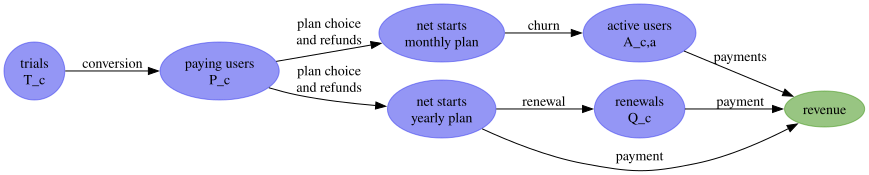

In [2]:
funnel = gr.Digraph(graph_attr={"rankdir": "LR"})
funnel.node("trials", label="trials\nT_c", color="#2a2eec80", style="filled")
funnel.node("paying", label="paying users\nP_c", color="#2a2eec80", style="filled")
funnel.node(
    "monthly", label="net starts\nmonthly plan", color="#2a2eec80", style="filled"
)
funnel.node(
    "yearly", label="net starts\nyearly plan", color="#2a2eec80", style="filled"
)
funnel.node("active", label="active users\nA_c,a", color="#2a2eec80", style="filled")
funnel.node("renewed", label="renewals\nQ_c", color="#2a2eec80", style="filled")
funnel.node("revenue", label="revenue", color="#328c0680", style="filled")
funnel.edge("trials", "paying", label="conversion")
funnel.edge("paying", "monthly", label="plan choice\nand refunds")
funnel.edge("paying", "yearly", label="plan choice\nand refunds")
funnel.edge("monthly", "active", label="churn")
funnel.edge("yearly", "renewed", label="renewal")
funnel.edge("active", "revenue", label="payments")
funnel.edge("yearly", "revenue", label="payment")
funnel.edge("renewed", "revenue", label="payment")
funnel

Let $h_c(a)$ be the **hazard** of the monthly plan at age $a \geq 1$: the probability that a user of cohort $c$ who paid at age $a - 1$ does not pay at age $a$. The **survival** $S_c(a)$, the probability that a monthly user is still active at age $a$, is the product of the probabilities to stay in every month so far:

$$
S_c(a) = \prod_{j=1}^{a} \left(1 - h_c(j)\right), \qquad S_c(0) = 1.
$$

We want to estimate two quantities. The first one is the **value per trial** $V_m$, the expected revenue over the horizon of one trial that starts in calendar month $m$. To write it down, let $p^{\text{conv}}_m$ be the conversion probability, $p^{\text{year}}_m$ the probability of the yearly plan, $r_k$ the refund probability of plan $k$, $p^{\text{renew}}_m$ the renewal probability and $\mu_k$ the **average revenue per payment** of plan $k$.

Each payment adds its average amount times the probability that it happens, so by the linearity of the expectation

$$
V_m = p^{\text{conv}}_m \left[ \left(1 - p^{\text{year}}_m\right) \left(1 - r_{\text{monthly}}\right) \mu_{\text{monthly}} \sum_{a=0}^{H-1} S_m(a) + p^{\text{year}}_m \left(1 - r_{\text{yearly}}\right) \mu_{\text{yearly}} \left(1 + p^{\text{renew}}_m\right) \right],
$$

where $S_m$ is the survival of a new cohort that starts in month $m$. Note that $\sum_{a} S_m(a)$ is the expected number of payments of a monthly user within the horizon.

The second quantity is the **cohort revenue** $R_c$, the total revenue of cohort $c$ over its first $H$ months. At the time of the forecast we have seen the revenue of cohort $c$ up to its current age, and we have to predict the rest.

We make the following assumptions:

- **Monthly time unit:** A trial converts, or not, within the month in which it starts, and every payment happens at the start of a month of age.
- **Two plans, no changes:** A user keeps the plan that they choose after the trial.
- **Refunds only on the first payment:** A refunded user leaves and never pays again.
- **Horizon of $24$ months:** We value a trial by its revenue in its first two years, a common payback period for paid acquisition. The users who remain after two years keep paying, so the value over a longer horizon is larger.
- **One renewal in the horizon:** The yearly plan pays at age $0$ and, if the user renews, at age $12$.
- **Stable funnel:** Apart from the season, the promotion and a random effect on the churn of each cohort, the rates of the funnel do not change across cohorts.
- **Promotion every November:** The promotion runs in the same month every year. We can only separate its effect from a November effect if we assume that a November cohort without the promotion would behave like the cohorts of the other months.
- **Gross revenue:** We ignore taxes, app store fees and the time value of money. So the value per trial is an upper bound on what we can pay for a trial, before these costs.

Before we generate data, let's look at the property of the churn that drives the value of a cohort.

### Survivor Selection

Suppose that every user has a constant churn probability $\theta$, so that a user with $\theta = 0.1$ cancels in any month with probability $0.1$, whatever their tenure. Users differ, and we describe the spread of $\theta$ within a cohort by a $\text{Beta}(\alpha, \beta)$ distribution. This is the **shifted-beta-geometric (sBG) model** of Fader and Hardie (2007): the lifetime of a single user is geometric, and the Beta distribution mixes over the users.

How does the cohort change with age? A user with churn probability $\theta$ is still active at age $a$ with probability $(1 - \theta)^a$. By Bayes' theorem, the density of $\theta$ among the users who are still active is proportional to the Beta density times this probability:

$$
f(\theta \mid \text{active at age } a) \propto \theta^{\alpha - 1} (1 - \theta)^{\beta - 1} (1 - \theta)^{a} = \theta^{\alpha - 1} (1 - \theta)^{\beta + a - 1}.
$$

So the active users at age $a$ follow a $\text{Beta}(\alpha, \beta + a)$ distribution. The hazard of the cohort at age $a + 1$ is the mean churn probability of these users:

$$
h(a + 1) = \text{E}[\theta \mid \text{active at age } a] = \frac{\alpha}{\alpha + \beta + a}.
$$

Let's work a simple example with $\alpha = 1$ and $\beta = 3$, the values of our generator. The mean churn probability of a new user is $1/4$. We plot the density of $\theta$ among the active users at a few ages.

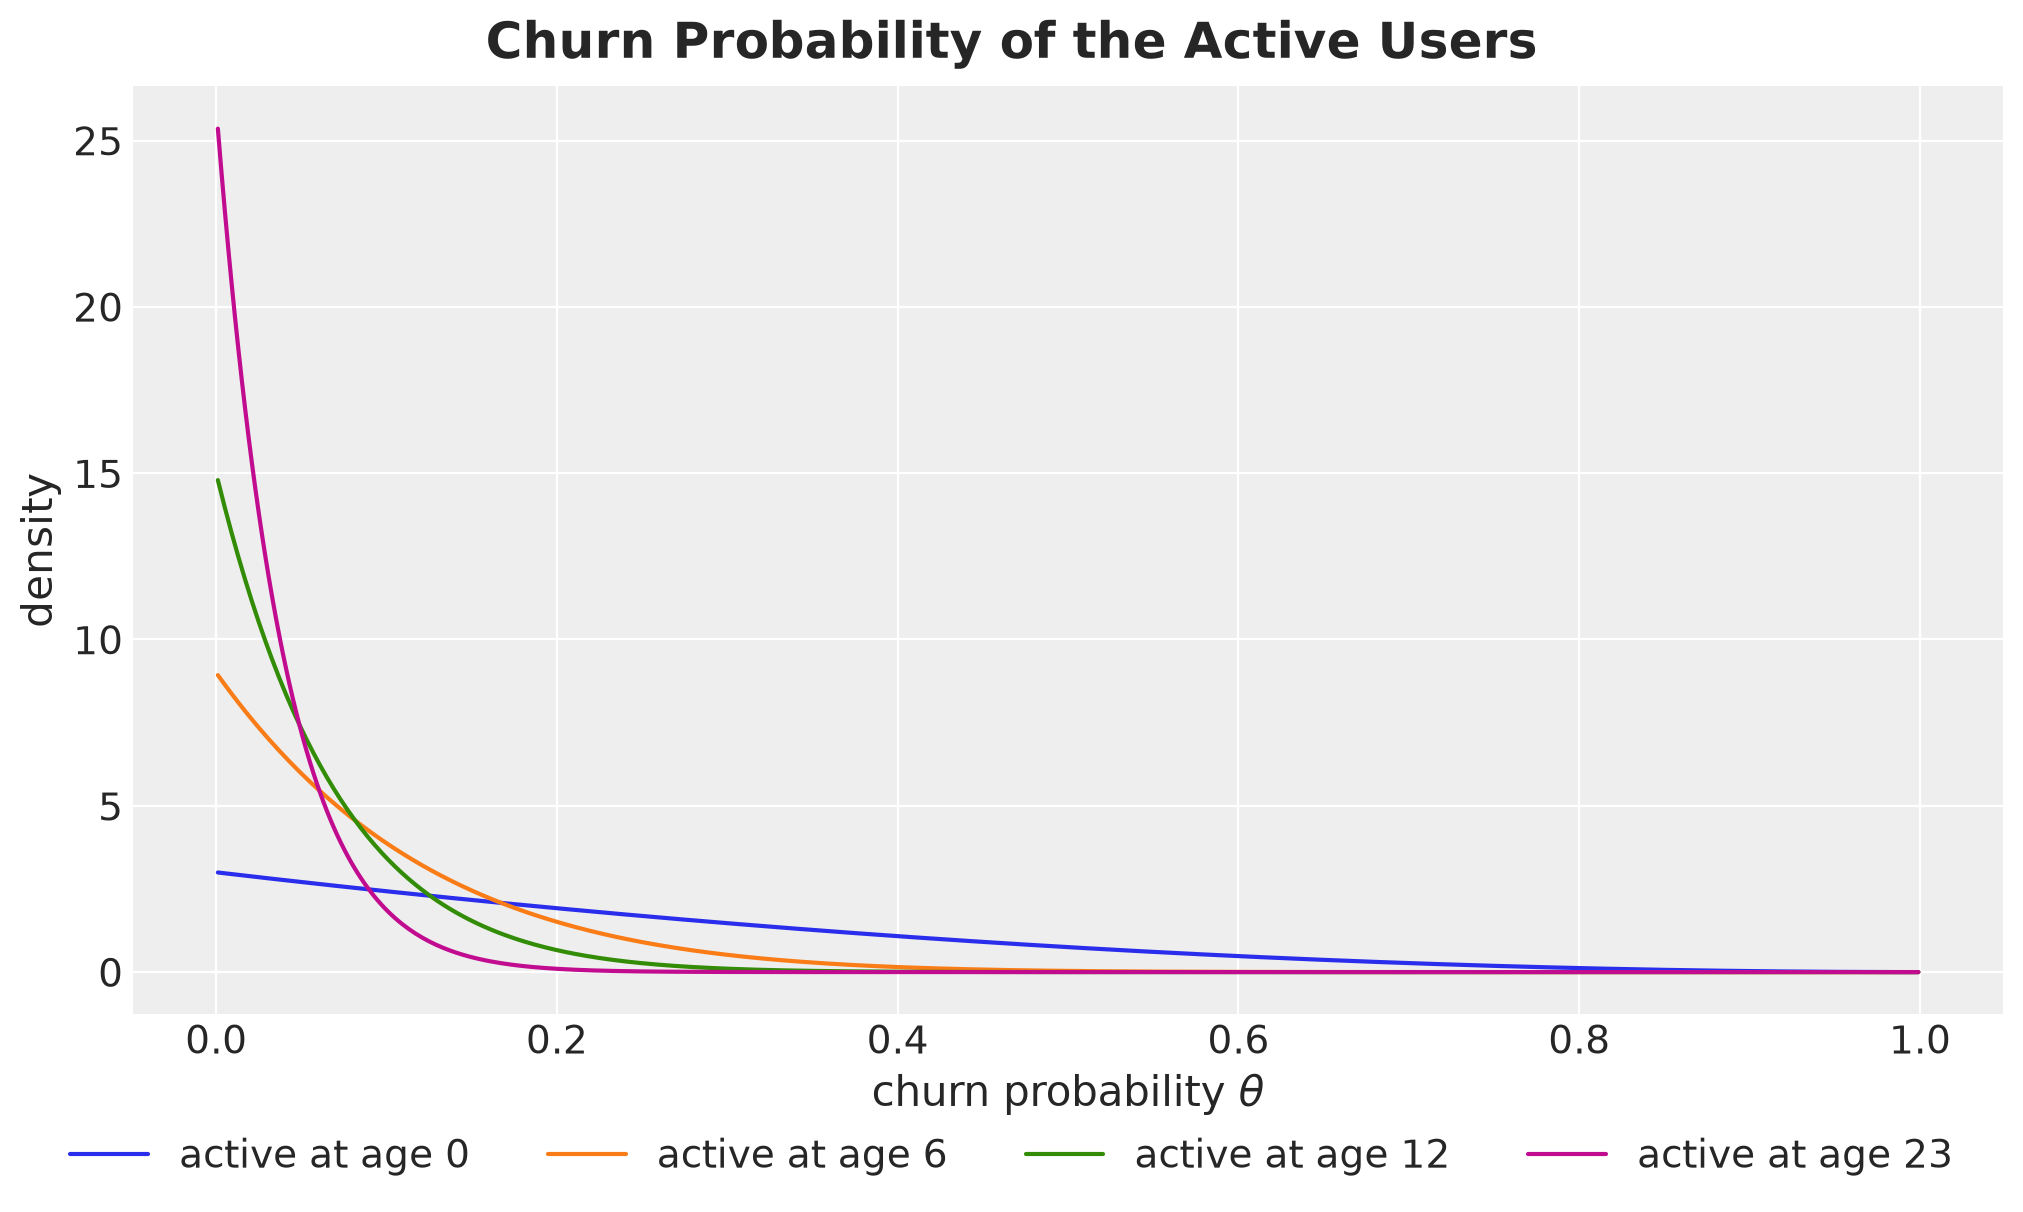

In [3]:
SBG_ALPHA, SBG_BETA = 1.0, 3.0

theta_values = np.linspace(0.001, 0.999, 500)

fig, ax = plt.subplots()

for i, age in enumerate([0, 6, 12, 23]):
    density = pz.Beta(SBG_ALPHA, SBG_BETA + age).pdf(theta_values)
    ax.plot(theta_values, density, color=f"C{i}", label=f"active at age {age}")

ax.set(xlabel=r"churn probability $\theta$", ylabel="density")
fig.legend(loc="outside lower center", ncol=4)
fig.suptitle("Churn Probability of the Active Users", fontsize=18, fontweight="bold");

The mass moves toward low churn probabilities as the cohort ages. No user changes their churn probability, but the users with a high $\theta$ leave first, and the ones who remain churn less. This is **survivor selection**.

Next, let's see what survivor selection does to the hazard and to the survival of the cohort. We compare the sBG cohort with a projection that keeps the churn of the first month, $h(1) = 1/4$, constant over the horizon.

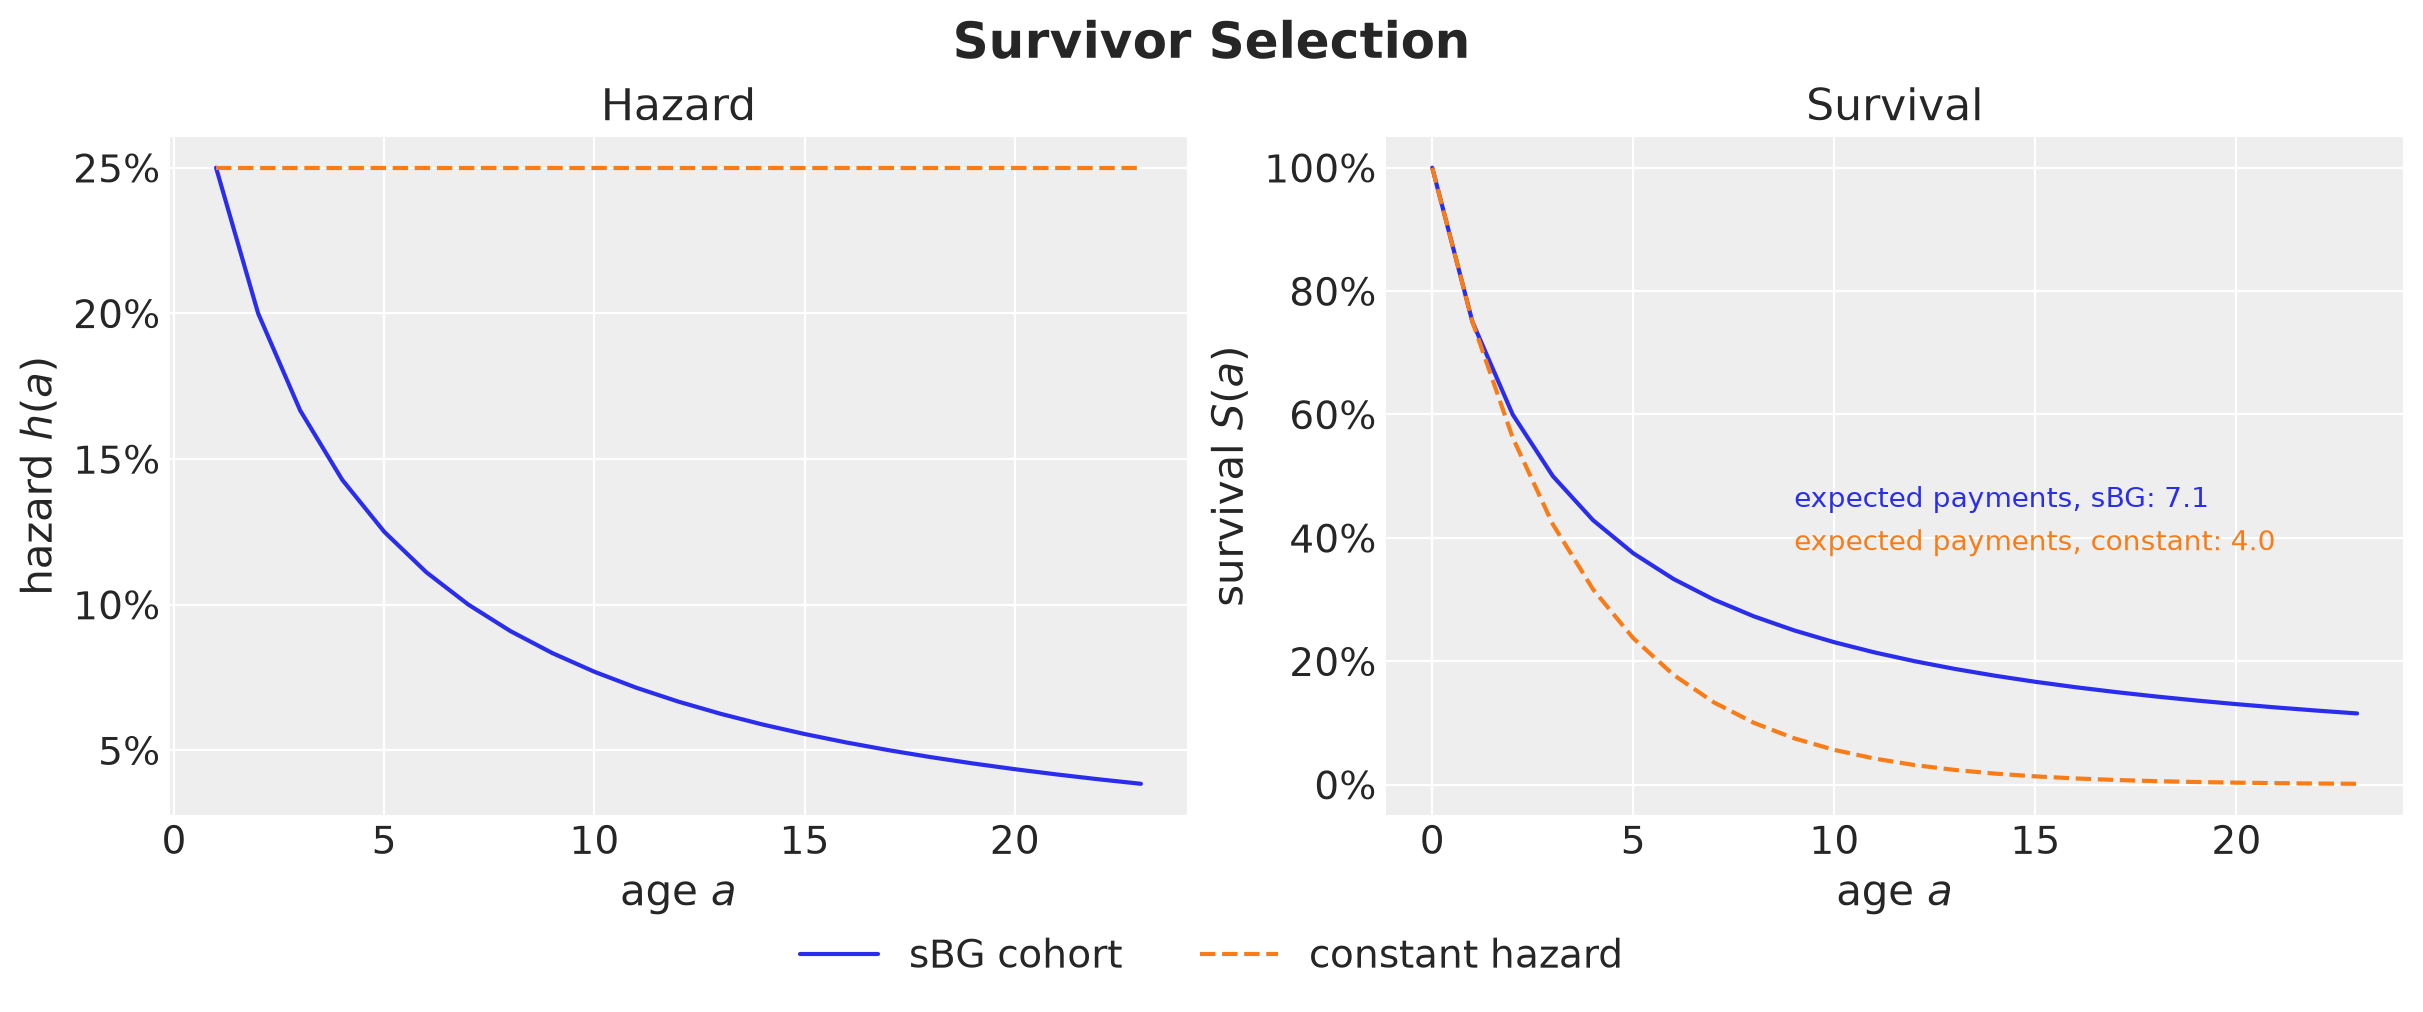

In [4]:
tenure_values = np.arange(1, 24)
age_values = np.arange(24)
hazard_sbg = SBG_ALPHA / (SBG_ALPHA + SBG_BETA + tenure_values - 1)
hazard_constant = np.full_like(hazard_sbg, hazard_sbg[0])
survival_sbg = np.concatenate([[1.0], np.cumprod(1 - hazard_sbg)])
survival_constant = np.concatenate([[1.0], np.cumprod(1 - hazard_constant)])

fig, axes = plt.subplots(ncols=2, figsize=(12, 5), layout="constrained")
ax = axes[0]
ax.plot(tenure_values, hazard_sbg, color="C0", label="sBG cohort")
ax.plot(
    tenure_values, hazard_constant, color="C1", linestyle="--", label="constant hazard"
)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(xlabel="age $a$", ylabel="hazard $h(a)$", title="Hazard")
ax = axes[1]
ax.plot(age_values, survival_sbg, color="C0")
ax.plot(age_values, survival_constant, color="C1", linestyle="--")
ax.text(9, 0.45, f"expected payments, sBG: {survival_sbg.sum():.1f}", color="C0")
ax.text(
    9, 0.38, f"expected payments, constant: {survival_constant.sum():.1f}", color="C1"
)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(xlabel="age $a$", ylabel="survival $S(a)$", title="Survival")
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle("Survivor Selection", fontsize=18, fontweight="bold");

The hazard of the sBG cohort falls from $25\%$ at age $1$ to about $4\%$ at age $23$. The projection with the churn of the first month expects about $4$ payments per monthly user over two years, against about $7$ for the sBG cohort. A model that ignores survivor selection underestimates the value of a monthly user by almost half.

The shape of the hazard comes from the spread of $\theta$, which we do not know in practice. So in our model we do not force a shape on the hazard. Each age gets its own effect, and a random walk ties neighboring ages together. Every age of the horizon is observed in the older cohorts, so the data fix the shape.

Survivor selection has a second consequence. Suppose that a promotion brings users whose churn probabilities are all a bit higher: the logit of the churn probability of each user moves up by $\kappa$, at every age. The cohort with the promotion loses its high-churn users faster, so its survivors are more selected than those of a cohort without the promotion, and the gap between the hazards of the two cohorts shrinks with age.

How fast does it shrink? For small churn probabilities the logit is close to the log, so the shift multiplies the churn probability of every user by $e^{\kappa}$. The frailty models of demography give a closed form for this case (Vaupel, Manton and Stallard 1979). Suppose that every user has a constant hazard $\phi$ times a **frailty** that follows a Gamma distribution with mean one and variance $v$. Then the hazard of the group at age $a$ is $\phi / (1 + v \phi a)$, and a group whose users all have their hazard multiplied by $e^{\kappa}$ has hazard $e^{\kappa} \phi / (1 + v e^{\kappa} \phi a)$. The log of the ratio of the two hazards is

$$
\begin{align*}
\log \frac{e^{\kappa} \phi / (1 + v e^{\kappa} \phi a)}{\phi / (1 + v \phi a)} & = \kappa - \log\left(1 + v e^{\kappa} \phi a\right) + \log\left(1 + v \phi a\right) \\
& \approx \kappa - \kappa \, \frac{v \phi a}{1 + v \phi a} = \frac{\kappa}{1 + v \phi a},
\end{align*}
$$

where the second line expands the first to first order in $\kappa$. So the gap shrinks by the same factor $1 / (1 + v \phi a)$ as the hazard of the group. Our Beta distribution behaves like a Gamma for small churn probabilities, so we expect the gap at age $a$ to be the gap at age $1$ times the factor by which the hazard of the sBG cohort has fallen since age $1$:

$$
\frac{h(a)}{h(1)} = \frac{\alpha + \beta}{\alpha + \beta + a - 1} = \frac{1}{1 + \lambda (a - 1)}, \qquad \lambda = \frac{1}{\alpha + \beta}.
$$

Let's check this with a cohort whose users all have their logit shifted by $\kappa = 0.25$. We compute the hazard of both cohorts on a grid of churn probabilities, with weights from the Beta density, and plot the gap between their logits.

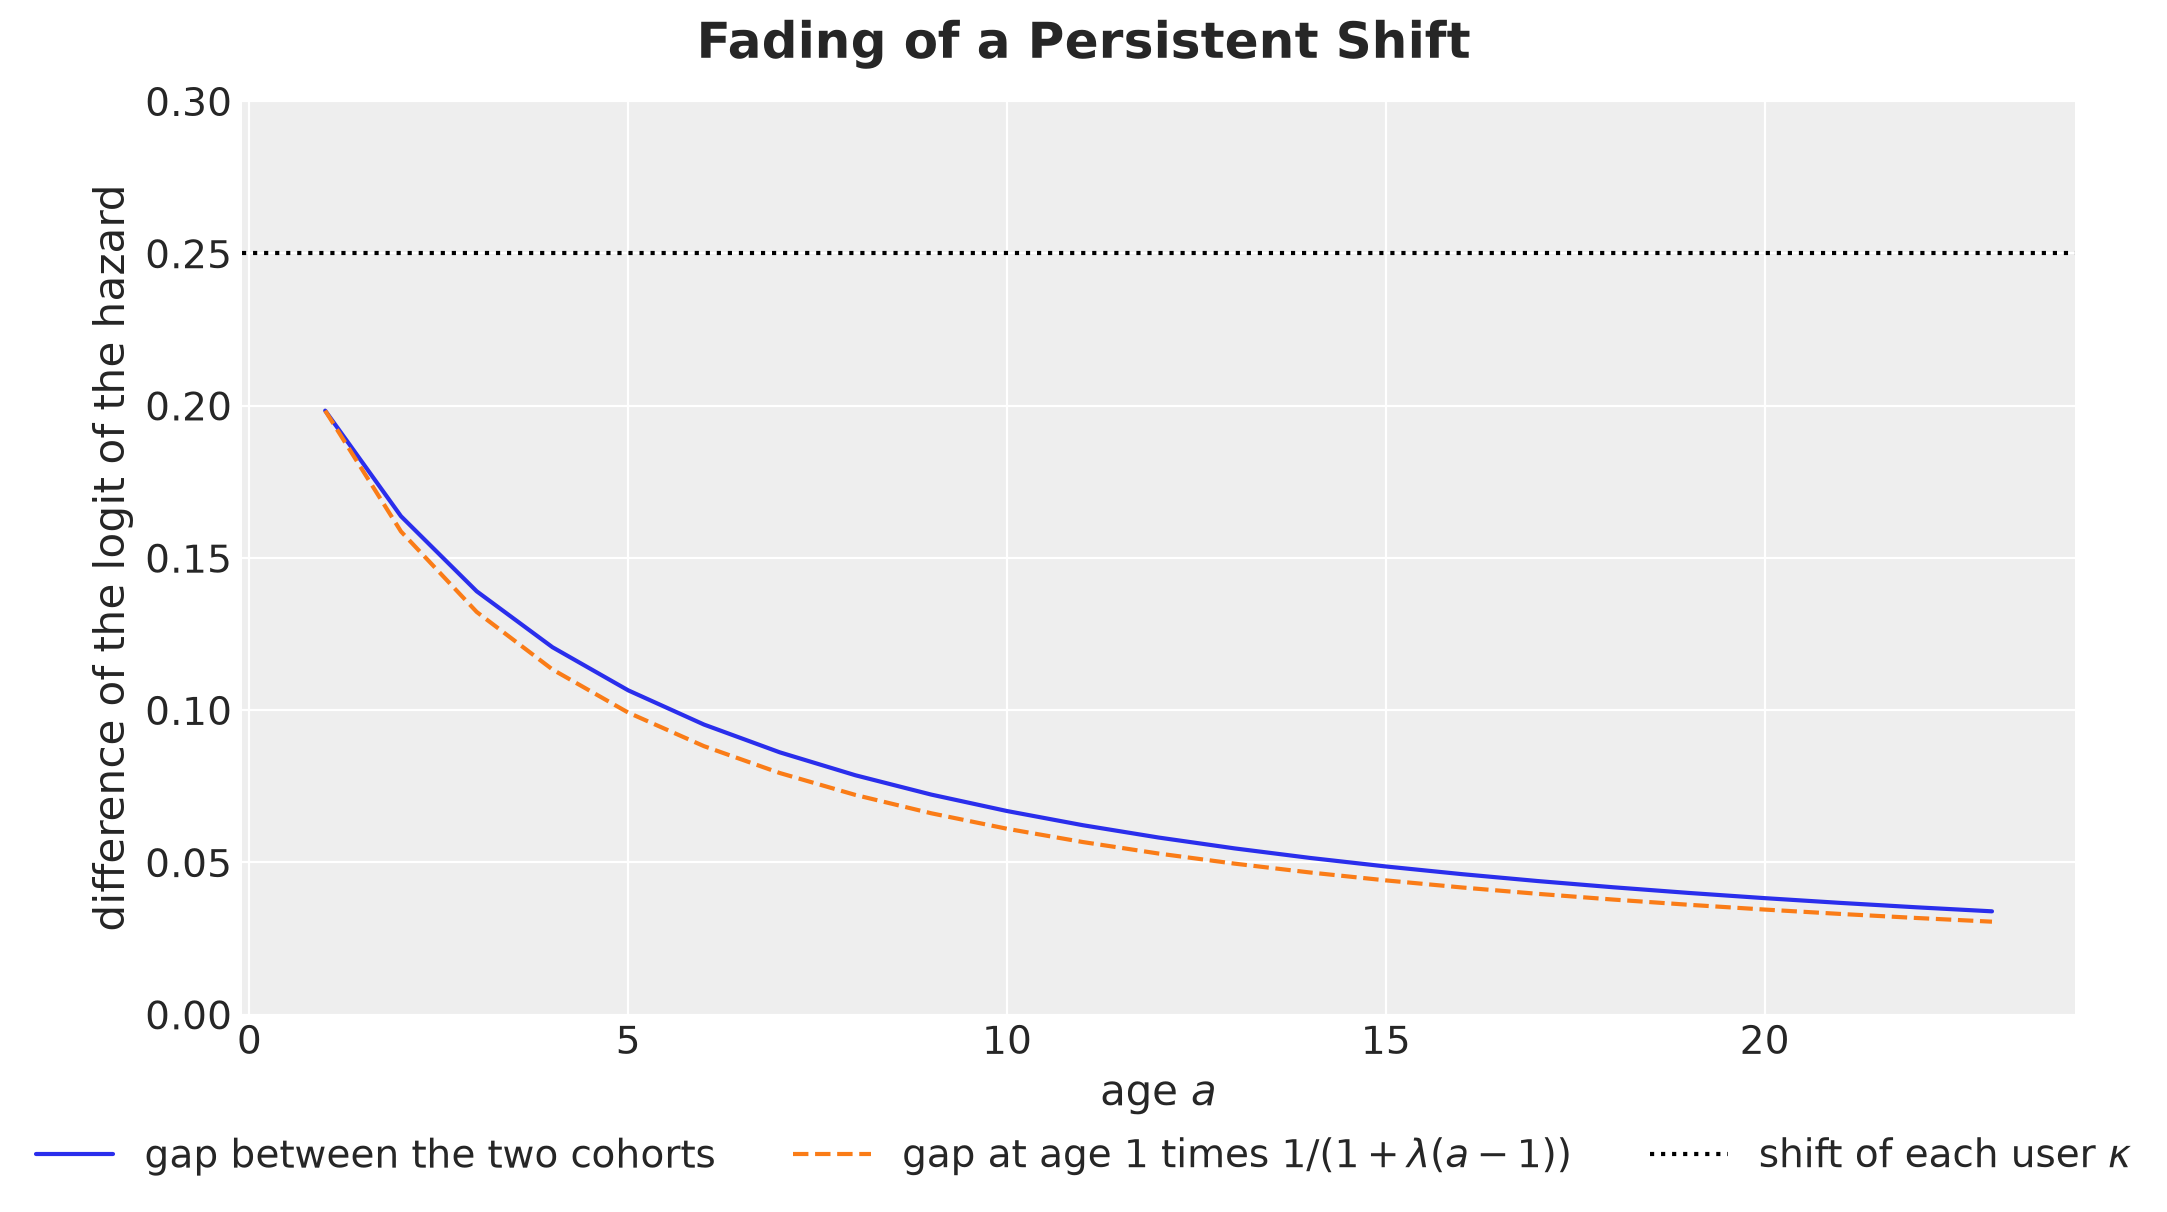

In [5]:
SHIFT = 0.25

theta_weights = pz.Beta(SBG_ALPHA, SBG_BETA).pdf(theta_values)


def cohort_hazard(shift: float) -> np.ndarray:
    """Hazard of an sBG cohort whose users have their logit shifted, by tenure."""
    churn = expit(logit(theta_values) + shift)
    active = (1 - churn[None, :]) ** (tenure_values[:, None] - 1)
    return (theta_weights * active * churn).sum(axis=1) / (theta_weights * active).sum(
        axis=1
    )


hazard_gap = logit(cohort_hazard(SHIFT)) - logit(cohort_hazard(0.0))
fading = 1 / (1 + (tenure_values - 1) / (SBG_ALPHA + SBG_BETA))

fig, ax = plt.subplots()
ax.plot(tenure_values, hazard_gap, color="C0", label="gap between the two cohorts")
ax.plot(
    tenure_values,
    hazard_gap[0] * fading,
    color="C1",
    linestyle="--",
    label=r"gap at age 1 times $1 / (1 + \lambda (a - 1))$",
)
ax.axhline(SHIFT, color="black", linestyle=":", label=r"shift of each user $\kappa$")
ax.set(xlabel="age $a$", ylabel="difference of the logit of the hazard", ylim=(0, 0.3))
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Fading of a Persistent Shift", fontsize=18, fontweight="bold");

Here are two important remarks:

- At age $1$ the gap between the cohorts is already smaller than the shift of each user, because the logit of an average is not the average of the logits. The hazard of a cohort is a **population-averaged** quantity, and its coefficients are smaller than the ones of each user ([Zeger, Liang and Albert 1988](https://doi.org/10.2307/2531734)).
- After age $1$ the gap fades, and the simple formula follows it closely. So in our model, the effects that last for the whole life of a cohort, such as the promotion, fade with age at a rate $\lambda$ that we learn from the data. The season acts only in its own month and changes the mix of users much less, so its effect does not fade.

Now we are ready to generate the data.

## Generate Data

We simulate four years of monthly cohorts with a generative model in PyMC, in three steps:

1. We write the model in PyMC.
2. We fix the true parameters with `pm.do`.
3. We take one draw with `pm.sample_prior_predictive`.

We first store the calendar of the app in a `Calendar` named tuple, and the plans and their list prices in a `Plan` enum and a dictionary.

In [6]:
class Plan(StrEnum):
    MONTHLY = "monthly"
    YEARLY = "yearly"


LIST_PRICE: Final[dict[Plan, float]] = {Plan.MONTHLY: 9.99, Plan.YEARLY: 69.99}
MONTHS: Final[list[str]] = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
]


class Calendar(NamedTuple):
    """Cohorts, horizon and promotion month of the synthetic app."""

    first_cohort: str = "2021-01"
    n_cohorts: int = 48
    horizon: int = 24  # months of revenue per cohort, ages 0 to 23
    promo_month: int = 10  # November, as an index of MONTHS

    @property
    def cohort_index(self) -> np.ndarray:
        return np.arange(self.n_cohorts)

    @property
    def cohort_labels(self) -> list[str]:
        first = np.datetime64(self.first_cohort, "M")
        return [str(first + i) for i in self.cohort_index]

    @property
    def start_month(self) -> np.ndarray:
        first = np.datetime64(self.first_cohort, "M").astype(int)
        return (first + self.cohort_index) % 12

    @property
    def promo(self) -> np.ndarray:
        return (self.start_month == self.promo_month).astype(float)

    @property
    def ages(self) -> np.ndarray:
        return np.arange(self.horizon)

    @property
    def tenures(self) -> np.ndarray:
        """Ages at which a monthly user can churn."""
        return np.arange(1, self.horizon)

    def payment_month(self, start_month: np.ndarray) -> np.ndarray:
        """Calendar month of the payment at each tenure, one row per start month."""
        return (start_month[:, None] + self.tenures[None, :]) % 12


calendar = Calendar()

Now, let's specify the data generating process. The trials follow a log-linear trend with a yearly pattern, and the conversion, the plan choice, the refunds and the renewal are Binomial counts with a logistic link. Let $t_c$ be the **time** of cohort $c$ in years since the first cohort. The parameters are:

- $\tau_0$, $\tau_1$ and $\tau_m$: the log level, the yearly growth and the monthly pattern of the trials.
- $\gamma_0$ and $\gamma_m$: the logit of the conversion and its monthly pattern.
- $\psi_0$ and $\psi_1$: the logit of the yearly plan and the effect of the promotion on it.
- $\rho_k$: the logit of the refund probability of plan $k$.
- $\eta_0$ and $\eta_1$: the logit of the renewal and the effect of the promotion on it.

The churn extends the sBG model of the *Survivor Selection* section with three shifts on the logit scale. Each user $i$ has a churn probability $\theta_i \sim \text{Beta}(\alpha, \beta)$, which moves with the season $\delta_m$ of the calendar month of the payment, the promotion effect $\kappa$ and a **cohort effect** $u_c \sim \text{Normal}(0, \sigma_u)$. The cohort effect stands for everything that makes one cohort churn more than another, such as the mix of ad networks that brought its users.

Finally, let $B_{c,k,a}$ be the number of **payers** of plan $k$ in cohort $c$ at age $a$ (the active users $A_{c,a}$ for the monthly plan, $N_{c,\text{yearly}}$ at age $0$ and $Q_c$ at age $12$ for the yearly plan) and $X_{c,k,a}$ their **revenue**. Each payment is a Gamma draw with mean $\mu_k$ and shape $\nu_k$, so the sum of $B_{c,k,a}$ payments is a Gamma with shape $B_{c,k,a} \nu_k$. In the earlier post the shape was the number of active users itself, and $\nu_k$ lets the amount of a single payment vary more or less. The data generating process is

$$
\begin{align*}
T_c & \sim \text{Poisson}\left(\exp\left(\tau_0 + \tau_1 t_c + \tau_{m_c}\right)\right) \\
P_c & \sim \text{Binomial}\left(T_c, \text{logit}^{-1}\left(\gamma_0 + \gamma_{m_c}\right)\right) \\
Y_c & \sim \text{Binomial}\left(P_c, \text{logit}^{-1}\left(\psi_0 + \psi_1 z_c\right)\right) \\
F_{c,k} & \sim \text{Binomial}\left(P_{c,k}, \text{logit}^{-1}\left(\rho_k\right)\right) \\
\theta_i & \sim \text{Beta}(\alpha, \beta) \\
\text{logit}\, h_i(a) & = \text{logit}\, \theta_i + \delta_{m_c + a} + \kappa z_c + u_c \\
Q_c & \sim \text{Binomial}\left(N_{c,\text{yearly}}, \text{logit}^{-1}\left(\eta_0 + \eta_1 z_c\right)\right) \\
X_{c,k,a} & \sim \text{Gamma}\left(B_{c,k,a} \nu_k, \nu_k / \mu_k\right),
\end{align*}
$$

where the Gamma has shape and rate parameters and the month index $m_c + a$ wraps around the year.

Simulating every user is slow, so we draw the users of a cohort in one step. Let the **lifetime** of a monthly user be the number of payments within the horizon, so that a user with lifetime $\ell$ pays at ages $0, \dots, \ell - 1$. Given the cohort effect, the users of a cohort are independent and have the same distribution of $\theta$, so their lifetimes are independent draws from one distribution. The counts of users by lifetime are therefore $\text{Multinomial}(N_{c,\text{monthly}}, \pi_c)$, with

$$
\pi_{c,\ell} = S_c(\ell - 1) - S_c(\ell) \quad \text{for } \ell < H, \qquad \pi_{c,H} = S_c(H - 1),
$$

where the survival $S_c(a)$ of the cohort is the average over $\theta$ of the survival of a single user. We compute this average on a grid of $200$ values of $\theta$, with weights proportional to the Beta density. The generator also records the true hazard of each cohort, $1 - S_c(a) / S_c(a - 1)$, which we use to check the model later.

Finally, the generator computes the true value per trial $V_m$ of *The Subscription Funnel* section. For a new cohort the effect $u$ is unknown, so we average the survival over $u \sim \text{Normal}(0, \sigma_u)$ with **Gauss-Hermite quadrature**, a weighted sum over $20$ fixed points that integrates a smooth function against a Normal density almost exactly. The helper functions below hold the two averages and the formula of $V_m$.

In [7]:
class Quadrature(NamedTuple):
    """Nodes and weights of a weighted sum that approximates an expectation."""

    nodes: np.ndarray
    weights: np.ndarray


def gauss_hermite(n_nodes: int) -> Quadrature:
    """Quadrature of the standard Normal distribution, with weights that sum to one."""
    nodes, weights = np.polynomial.hermite_e.hermegauss(n_nodes)
    return Quadrature(nodes=nodes, weights=weights / weights.sum())


def theta_grid(n_points: int) -> np.ndarray:
    """Midpoints of equal bins of the unit interval."""
    return (np.arange(n_points) + 0.5) / n_points


def survival(hazard: pmd.XTensorVariable) -> pmd.XTensorVariable:
    """Probability to be active at each tenure, the cumulative product of 1 - hazard."""
    return pmd.math.exp(pmd.math.log1p(-hazard).cumsum("tenure"))


def value_per_trial(
    conversion: pmd.XTensorVariable,
    yearly_share: pmd.XTensorVariable,
    refund: pmd.XTensorVariable,
    monthly_payments: pmd.XTensorVariable,
    renewal: pmd.XTensorVariable,
    revenue_per_payment: pmd.XTensorVariable,
) -> pmd.XTensorVariable:
    """Expected revenue of one trial over the horizon (the formula of V_m)."""
    monthly_value = (
        (1 - yearly_share)
        * (1 - refund.isel(plan=0))
        * revenue_per_payment.isel(plan=0)
        * monthly_payments
    )
    yearly_value = (
        yearly_share
        * (1 - refund.isel(plan=1))
        * revenue_per_payment.isel(plan=1)
        * (1 + renewal)
    )
    return conversion * (monthly_value + yearly_value)


QUADRATURE: Final[Quadrature] = gauss_hermite(n_nodes=20)
THETA_GRID: Final[np.ndarray] = theta_grid(n_points=200)

We proceed by implementing the generator. The priors inside it play no role, since `pm.do` fixes every parameter, and we choose the priors of the funnel model later. We use the [`pymc.dims`](https://www.pymc.io/projects/docs/en/stable/learn/core_notebooks/dims_module.html) module, in which every variable carries named dimensions and arithmetic aligns by name. It does not include the Binomial and the Multinomial distributions yet, so for these lines we convert to regular tensors with `.values` and use the classic API.

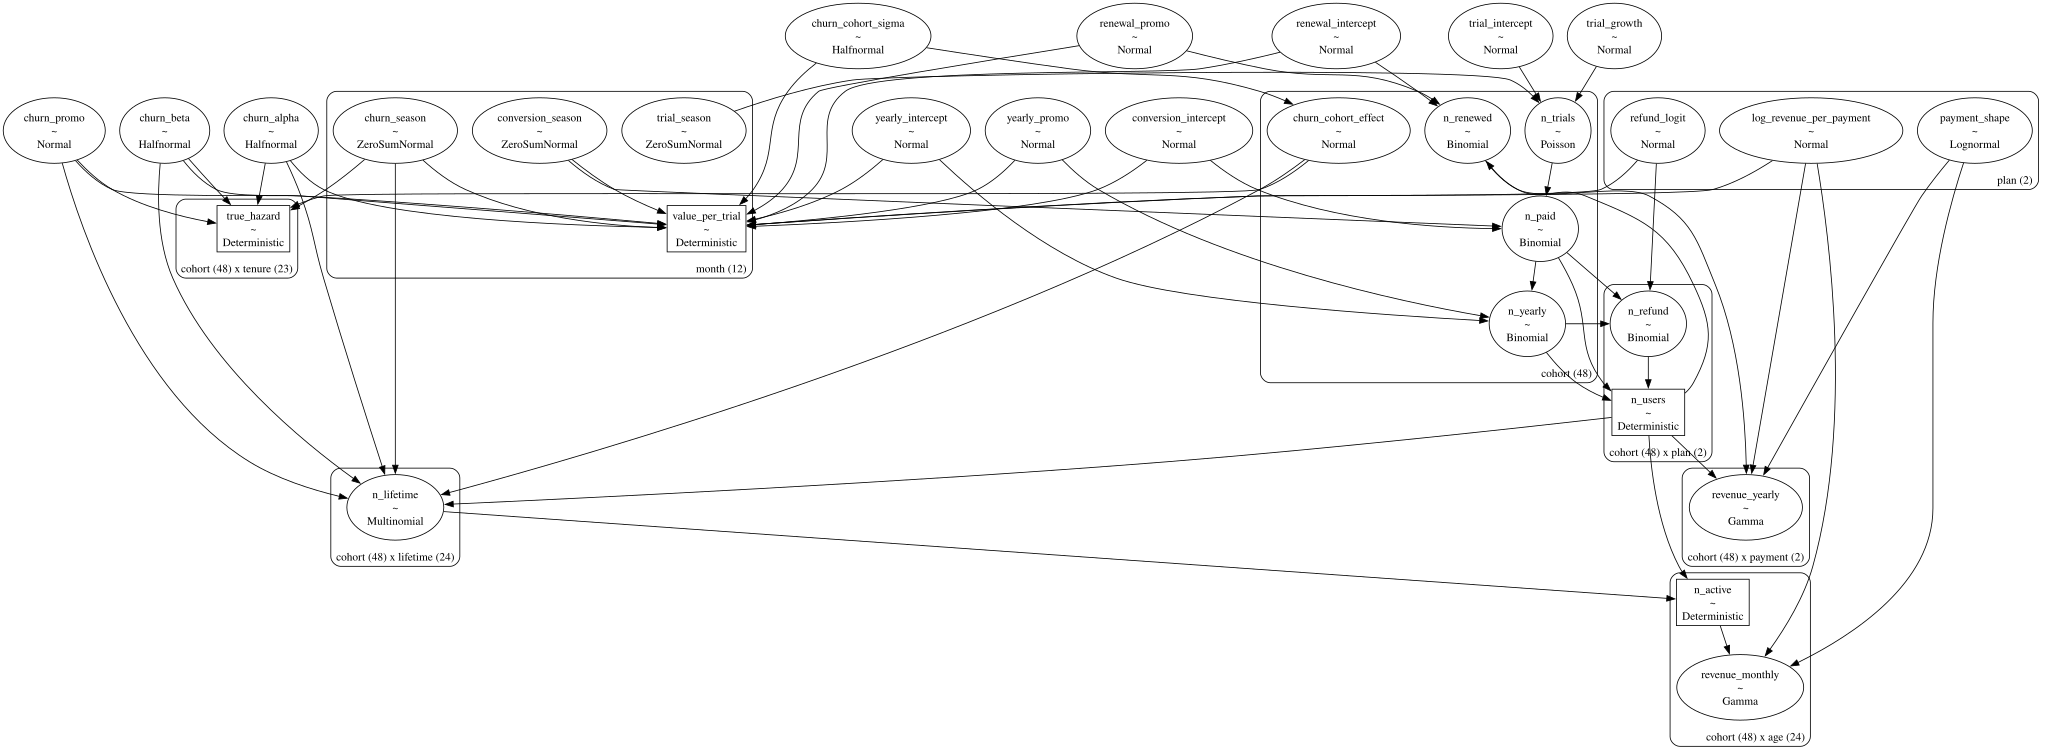

In [8]:
generator_coords = {
    "cohort": calendar.cohort_labels,
    "month": MONTHS,
    "plan": list(Plan),
    "age": calendar.ages,
    "tenure": calendar.tenures,
    "lifetime": np.arange(1, calendar.horizon + 1),
    "payment": ["initial", "renewal"],
    "theta": THETA_GRID,
    "node": QUADRATURE.nodes,
}

with pm.Model(coords=generator_coords) as generator:
    start_month = pmd.as_xtensor(calendar.start_month, dims=("cohort",))
    promo = pmd.as_xtensor(calendar.promo, dims=("cohort",))
    years = pmd.as_xtensor(calendar.cohort_index / 12, dims=("cohort",))
    payment_month = pmd.as_xtensor(
        calendar.payment_month(calendar.start_month), dims=("cohort", "tenure")
    )
    theta = pmd.as_xtensor(THETA_GRID, dims=("theta",))

    # --- trials and conversion ---
    trial_intercept = pmd.Normal("trial_intercept", 8.0, 1.0)
    trial_growth = pmd.Normal("trial_growth", 0.0, 0.2)
    trial_season = pmd.ZeroSumNormal(
        "trial_season", sigma=0.2, core_dims="month", dims="month"
    )
    n_trials = pmd.Poisson(
        "n_trials",
        mu=pmd.math.exp(
            trial_intercept
            + trial_growth * years
            + trial_season.isel(month=start_month)
        ),
    )
    conversion_intercept = pmd.Normal("conversion_intercept", 0.0, 1.0)
    conversion_season = pmd.ZeroSumNormal(
        "conversion_season", sigma=0.3, core_dims="month", dims="month"
    )
    n_paid = pm.Binomial(
        "n_paid",
        n=n_trials.values,
        logit_p=(
            conversion_intercept + conversion_season.isel(month=start_month)
        ).values,
        dims="cohort",
    )

    # --- plan choice and refunds ---
    yearly_intercept = pmd.Normal("yearly_intercept", 0.0, 1.0)
    yearly_promo = pmd.Normal("yearly_promo", 0.0, 1.0)
    n_yearly = pm.Binomial(
        "n_yearly",
        n=n_paid,
        logit_p=(yearly_intercept + yearly_promo * promo).values,
        dims="cohort",
    )
    n_plan = pt.stack([n_paid - n_yearly, n_yearly], axis=-1)
    refund_logit = pmd.Normal("refund_logit", -3.0, 1.0, dims="plan")
    n_refund = pm.Binomial(
        "n_refund", n=n_plan, logit_p=refund_logit.values, dims=("cohort", "plan")
    )
    n_users = pm.Deterministic("n_users", n_plan - n_refund, dims=("cohort", "plan"))

    # --- monthly churn: sBG users with season, promotion and cohort shifts ---
    churn_alpha = pmd.HalfNormal("churn_alpha", 2.0)
    churn_beta = pmd.HalfNormal("churn_beta", 5.0)
    theta_density = pmd.math.exp(
        (churn_alpha - 1) * pmd.math.log(theta)
        + (churn_beta - 1) * pmd.math.log1p(-theta)
    )
    theta_weight = theta_density / theta_density.sum("theta")
    churn_season = pmd.ZeroSumNormal(
        "churn_season", sigma=0.2, core_dims="month", dims="month"
    )
    churn_promo = pmd.Normal("churn_promo", 0.0, 0.5)
    churn_cohort_sigma = pmd.HalfNormal("churn_cohort_sigma", 0.2)
    churn_cohort_effect = pmd.Normal(
        "churn_cohort_effect", 0.0, churn_cohort_sigma, dims="cohort"
    )
    logit_theta = pmd.math.log(theta) - pmd.math.log1p(-theta)
    user_hazard = pmd.math.sigmoid(
        logit_theta
        + churn_season.isel(month=payment_month)
        + churn_promo * promo
        + churn_cohort_effect
    )
    cohort_survival = (
        (survival(user_hazard) * theta_weight)
        .sum("theta")
        .transpose("cohort", "tenure")
        .values
    )
    cohort_survival = pt.concatenate(
        [pt.ones((calendar.n_cohorts, 1)), cohort_survival], axis=1
    )
    pm.Deterministic(
        "true_hazard",
        1 - cohort_survival[:, 1:] / cohort_survival[:, :-1],
        dims=("cohort", "tenure"),
    )
    lifetime_probability = pt.concatenate(
        [cohort_survival[:, :-1] - cohort_survival[:, 1:], cohort_survival[:, -1:]],
        axis=1,
    )
    n_lifetime = pm.Multinomial(
        "n_lifetime",
        n=n_users[:, 0],
        p=lifetime_probability,
        dims=("cohort", "lifetime"),
    )
    n_churned = pt.cumsum(n_lifetime[:, :-1], axis=1)
    n_active = pm.Deterministic(
        "n_active",
        pt.concatenate([n_users[:, :1], n_users[:, :1] - n_churned], axis=1),
        dims=("cohort", "age"),
    )

    # --- yearly renewal ---
    renewal_intercept = pmd.Normal("renewal_intercept", 0.0, 1.0)
    renewal_promo = pmd.Normal("renewal_promo", 0.0, 1.0)
    n_renewed = pm.Binomial(
        "n_renewed",
        n=n_users[:, 1],
        logit_p=(renewal_intercept + renewal_promo * promo).values,
        dims="cohort",
    )

    # --- revenue ---
    log_revenue_per_payment = pmd.Normal(
        "log_revenue_per_payment",
        pmd.as_xtensor(np.log(list(LIST_PRICE.values())), dims=("plan",)),
        0.2,
    )
    payment_shape = pmd.LogNormal("payment_shape", np.log(50.0), 1.0, dims="plan")
    revenue_per_payment = pmd.math.exp(log_revenue_per_payment)
    shape, mean = payment_shape.values, revenue_per_payment.values
    pm.Gamma(
        "revenue_monthly",
        alpha=n_active * shape[0],
        beta=shape[0] / mean[0],
        dims=("cohort", "age"),
    )
    yearly_payers = pt.stack([n_users[:, 1], n_renewed], axis=-1)
    pm.Gamma(
        "revenue_yearly",
        alpha=yearly_payers * shape[1],
        beta=shape[1] / mean[1],
        dims=("cohort", "payment"),
    )

    # --- true value per trial of a new cohort, by start month ---
    new_start_month = np.arange(12)
    new_promo = pmd.as_xtensor(
        (new_start_month == calendar.promo_month).astype(float), dims=("month",)
    )
    new_payment_month = pmd.as_xtensor(
        calendar.payment_month(new_start_month), dims=("month", "tenure")
    )
    new_cohort_effect = churn_cohort_sigma * pmd.as_xtensor(
        QUADRATURE.nodes, dims=("node",)
    )
    new_user_hazard = pmd.math.sigmoid(
        logit_theta
        + churn_season.isel(month=new_payment_month)
        + churn_promo * new_promo
        + new_cohort_effect
    )
    node_weight = pmd.as_xtensor(QUADRATURE.weights, dims=("node",))
    monthly_payments = 1 + (survival(new_user_hazard) * theta_weight * node_weight).sum(
        ("theta", "node", "tenure")
    )
    pmd.Deterministic(
        "value_per_trial",
        value_per_trial(
            conversion=pmd.math.sigmoid(conversion_intercept + conversion_season),
            yearly_share=pmd.math.sigmoid(yearly_intercept + yearly_promo * new_promo),
            refund=pmd.math.sigmoid(refund_logit),
            monthly_payments=monthly_payments,
            renewal=pmd.math.sigmoid(renewal_intercept + renewal_promo * new_promo),
            revenue_per_payment=revenue_per_payment,
        ),
    )

pm.model_to_graphviz(generator)

We now fix the true parameter values that we intervene on, and take one draw. The rates are the ones of a typical subscription app: $60\%$ of the trials convert, $30\%$ of the paying users choose the yearly plan, and $32\%$ of the yearly users renew. The promotion raises the share of the yearly plan, and the users that it brings churn more and renew less. The amount of a payment is a little below the list price, for example because of taxes and discounts.

In [9]:
def centered(values: list[float]) -> np.ndarray:
    """Subtract the mean, so that a monthly pattern sums to zero."""
    values = np.asarray(values, dtype=float)
    return values - values.mean()


TRUE_PARAMS: Final[dict[str, float | np.ndarray]] = {
    "trial_intercept": np.log(3_000.0),
    "trial_growth": 0.12,
    "trial_season": centered(np.log([1.35, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1.25, 1.15])),
    "conversion_intercept": logit(0.6),
    "conversion_season": centered(
        [0.45, 0.10, 0.05, 0.0, -0.05, -0.40, -0.80, -0.70, -0.05, 0.10, 0.25, 0.35]
    ),
    "yearly_intercept": logit(0.3),
    "yearly_promo": 0.9,
    "refund_logit": logit(np.array([0.02, 0.12])),
    "churn_alpha": SBG_ALPHA,
    "churn_beta": SBG_BETA,
    "churn_season": centered(
        [0.20, 0.05, 0.0, -0.05, -0.05, 0.0, 0.05, 0.05, 0.10, -0.05, -0.10, -0.20]
    ),
    "churn_promo": 0.25,
    "churn_cohort_sigma": 0.15,
    "renewal_intercept": logit(0.32),
    "renewal_promo": -0.6,
    "log_revenue_per_payment": np.log([9.99 * 0.95, 69.99 * 0.93]),
    "payment_shape": np.array([40.0, 60.0]),
}

world = pm.sample_prior_predictive(
    draws=1, model=pm.do(generator, TRUE_PARAMS), random_seed=rng
)["prior"].isel(chain=0, draw=0)

assert (np.diff(world["n_active"].values, axis=1) <= 0).all()

The assertion checks that the number of active users never grows with age. Next, we collect the draw in two polars tables: `cohorts`, with one row per cohort and the counts of the first steps of the funnel, and `payments`, with one row per cohort, plan and age at which a payment can happen. The `period` column counts the calendar months since January 2021, so that we can cut the data at any date, and `month` is the calendar month of the payment.

In [10]:
cohorts = pl.DataFrame(
    {
        "cohort": calendar.cohort_index,
        "start_month": calendar.start_month,
        "promo": calendar.promo,
        "n_trials": world["n_trials"].values,
        "n_paid": world["n_paid"].values,
        "n_yearly": world["n_yearly"].values,
        "n_refund_monthly": world["n_refund"].sel(plan=Plan.MONTHLY).values,
        "n_refund_yearly": world["n_refund"].sel(plan=Plan.YEARLY).values,
        "n_users_monthly": world["n_users"].sel(plan=Plan.MONTHLY).values,
        "n_users_yearly": world["n_users"].sel(plan=Plan.YEARLY).values,
    }
)

monthly_payments = pl.DataFrame(
    {
        "cohort": np.repeat(calendar.cohort_index, calendar.horizon),
        "age": np.tile(calendar.ages, calendar.n_cohorts),
        "n_payers": world["n_active"].values.ravel(),
        "revenue": world["revenue_monthly"].values.ravel(),
    }
).with_columns(plan=pl.lit(Plan.MONTHLY.value))

yearly_payments = pl.DataFrame(
    {
        "cohort": np.repeat(calendar.cohort_index, 2),
        "age": np.tile([0, 12], calendar.n_cohorts),
        "n_payers": np.column_stack(
            [
                world["n_users"].sel(plan=Plan.YEARLY).values,
                world["n_renewed"].values,
            ]
        ).ravel(),
        "revenue": world["revenue_yearly"].values.ravel(),
    }
).with_columns(plan=pl.lit(Plan.YEARLY.value))

payments = (
    pl.concat([monthly_payments, yearly_payments])
    .with_columns(period=pl.col("cohort") + pl.col("age"))
    .with_columns(month=pl.col("period") % 12)
    .sort("cohort", "plan", "age")
)

payments.head()

cohort,age,n_payers,revenue,plan,period,month
i64,i64,i64,f64,str,i64,i64
0,0,1851,17622.024391,"""monthly""",0,0
0,1,1315,12370.106797,"""monthly""",1,1
0,2,1045,9985.362679,"""monthly""",2,2
0,3,877,8291.817905,"""monthly""",3,3
0,4,752,7124.471694,"""monthly""",4,4


Let's look at the first steps of the funnel for every cohort: the trials and the paying users, and the share of the paying users who choose the yearly plan. The vertical lines mark the November cohorts, which get the promotion.

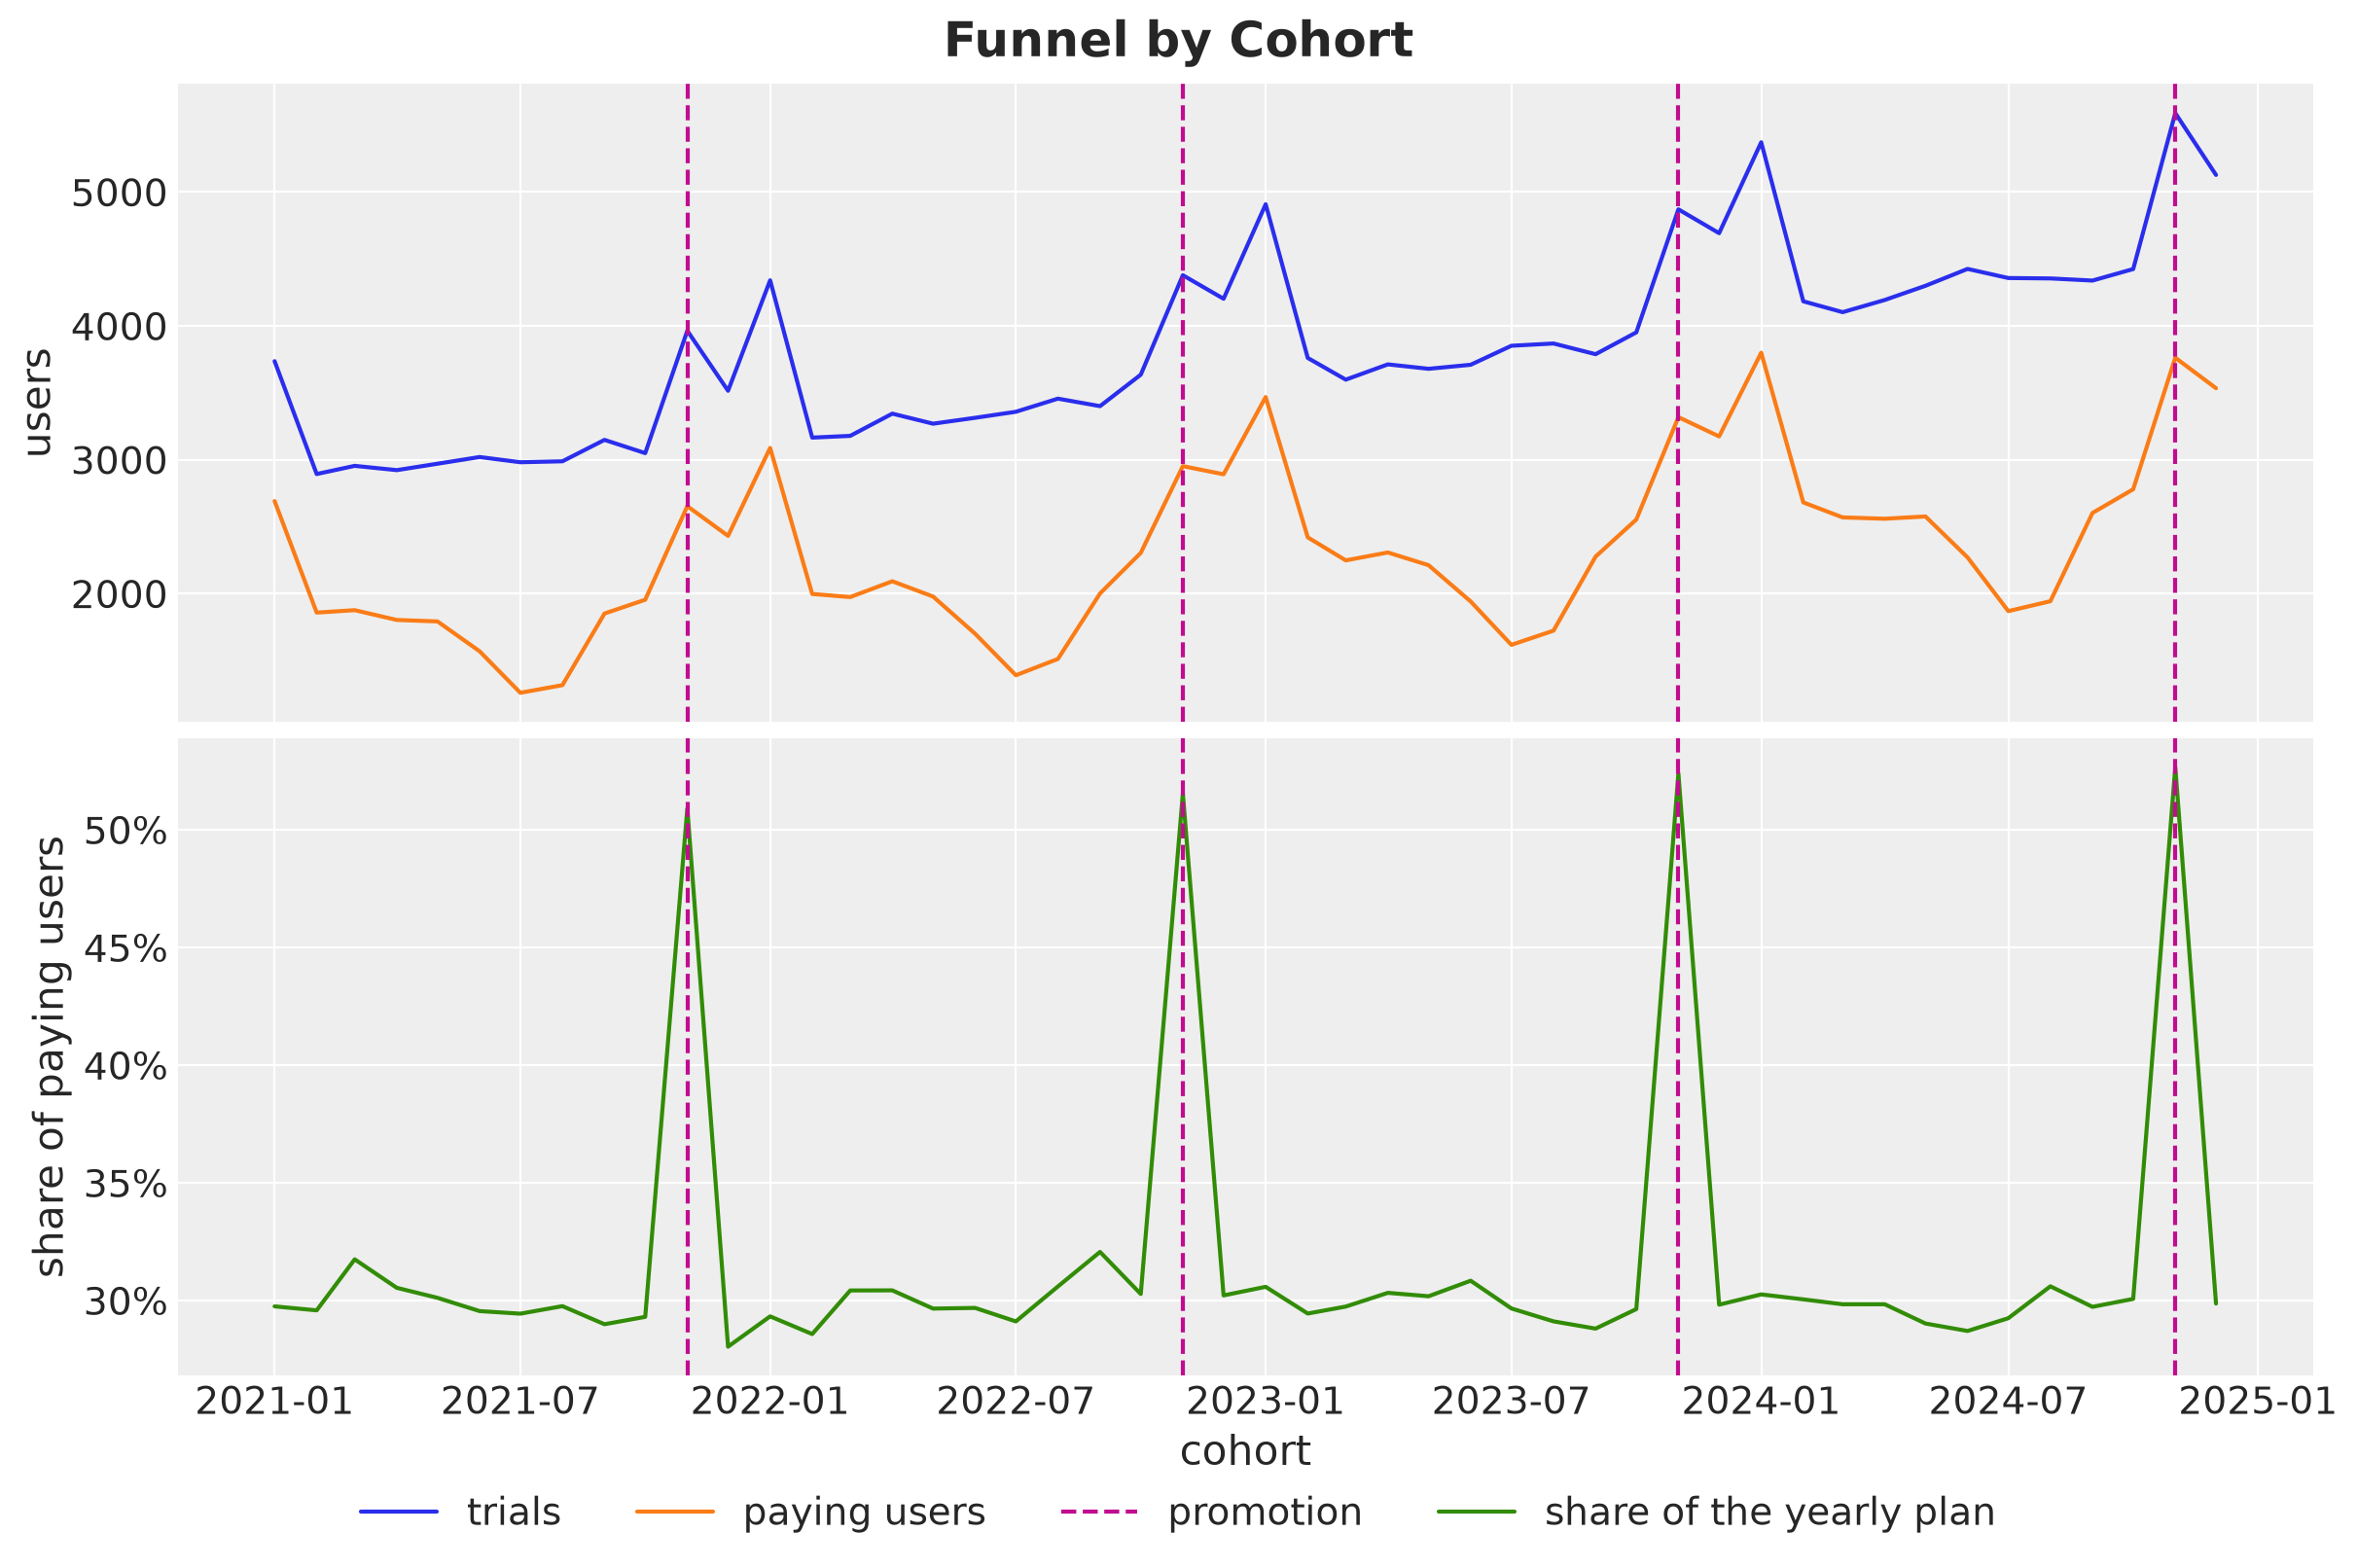

In [11]:
cohort_dates = np.array(calendar.cohort_labels, dtype="datetime64[M]")
promo_dates = cohort_dates[calendar.promo > 0]

fig, axes = plt.subplots(
    nrows=2, ncols=1, figsize=(12, 8), sharex=True, sharey=False, layout="constrained"
)
ax = axes[0]
ax.plot(cohort_dates, cohorts["n_trials"], color="C0", label="trials")
ax.plot(cohort_dates, cohorts["n_paid"], color="C1", label="paying users")
ax.set(ylabel="users")
ax = axes[1]
ax.plot(
    cohort_dates,
    cohorts["n_yearly"] / cohorts["n_paid"],
    color="C2",
    label="share of the yearly plan",
)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(xlabel="cohort", ylabel="share of paying users")

for ax in axes:
    for date in promo_dates:
        ax.axvline(date, color="C3", linestyle="--")

axes[0].lines[-1].set_label("promotion")
fig.legend(loc="outside lower center", ncol=4)
fig.suptitle("Funnel by Cohort", fontsize=18, fontweight="bold");

The trials grow over the years and peak every January. The conversion drops in the summer, so the paying users dip in July and August while the trials stay flat. In every November the promotion lifts the share of the yearly plan from about $30\%$ to more than $50\%$.

We now cut the data at the end of a month, the **freeze**, as if we were looking at the app on that date. The `FunnelData` named tuple holds what we know at the freeze: the cohorts that have started and the payments that have happened. Its `transitions` property gives the monthly users at risk of churning, one row per cohort and age, with the active users at the previous age.

In [12]:
class FunnelData(NamedTuple):
    """The cohorts and the payments that we know at the end of the freeze month."""

    freeze: int
    cohorts: pl.DataFrame
    payments: pl.DataFrame

    @property
    def cohort_labels(self) -> list[str]:
        return [calendar.cohort_labels[c] for c in self.cohorts["cohort"]]

    @property
    def transitions(self) -> pl.DataFrame:
        return (
            self.payments.filter(pl.col("plan") == Plan.MONTHLY)
            .with_columns(n_previous=pl.col("n_payers").shift(1).over("cohort"))
            .filter(pl.col("age") >= 1)
        )

    @property
    def renewals(self) -> pl.DataFrame:
        return self.payments.filter(
            (pl.col("plan") == Plan.YEARLY) & (pl.col("age") == 12)
        )

    @property
    def current_age(self) -> np.ndarray:
        """Age of each cohort at the freeze, capped at the end of the horizon."""
        return np.minimum(
            self.freeze - self.cohorts["cohort"].to_numpy(), calendar.horizon - 1
        )

    @property
    def current_active(self) -> np.ndarray:
        """Active users of the monthly plan of each cohort at its current age."""
        return (
            self.payments.filter(pl.col("plan") == Plan.MONTHLY)
            .group_by("cohort")
            .agg(pl.col("n_payers").sort_by("age").last())
            .sort("cohort")["n_payers"]
            .to_numpy()
        )

    @property
    def revenue_to_date(self) -> np.ndarray:
        """Revenue of each cohort up to the freeze, both plans."""
        return (
            self.payments.group_by("cohort")
            .agg(pl.col("revenue").sum())
            .sort("cohort")["revenue"]
            .to_numpy()
        )


def observe(freeze: int) -> FunnelData:
    """Cut the complete world at the end of the freeze month."""
    return FunnelData(
        freeze=freeze,
        cohorts=cohorts.filter(pl.col("cohort") <= freeze),
        payments=payments.filter(pl.col("period") <= freeze),
    )


FREEZE: Final[int] = calendar.cohort_labels.index("2024-12")

data = observe(FREEZE)

At the freeze of December 2024 we see the classic cohort triangle: the oldest cohorts are complete and the youngest one has made its first payment. We plot the **retention** of the monthly plan, the share $A_{c,a} / N_{c,\text{monthly}}$ of the net starts that are still active, for every cohort and age that we have observed.

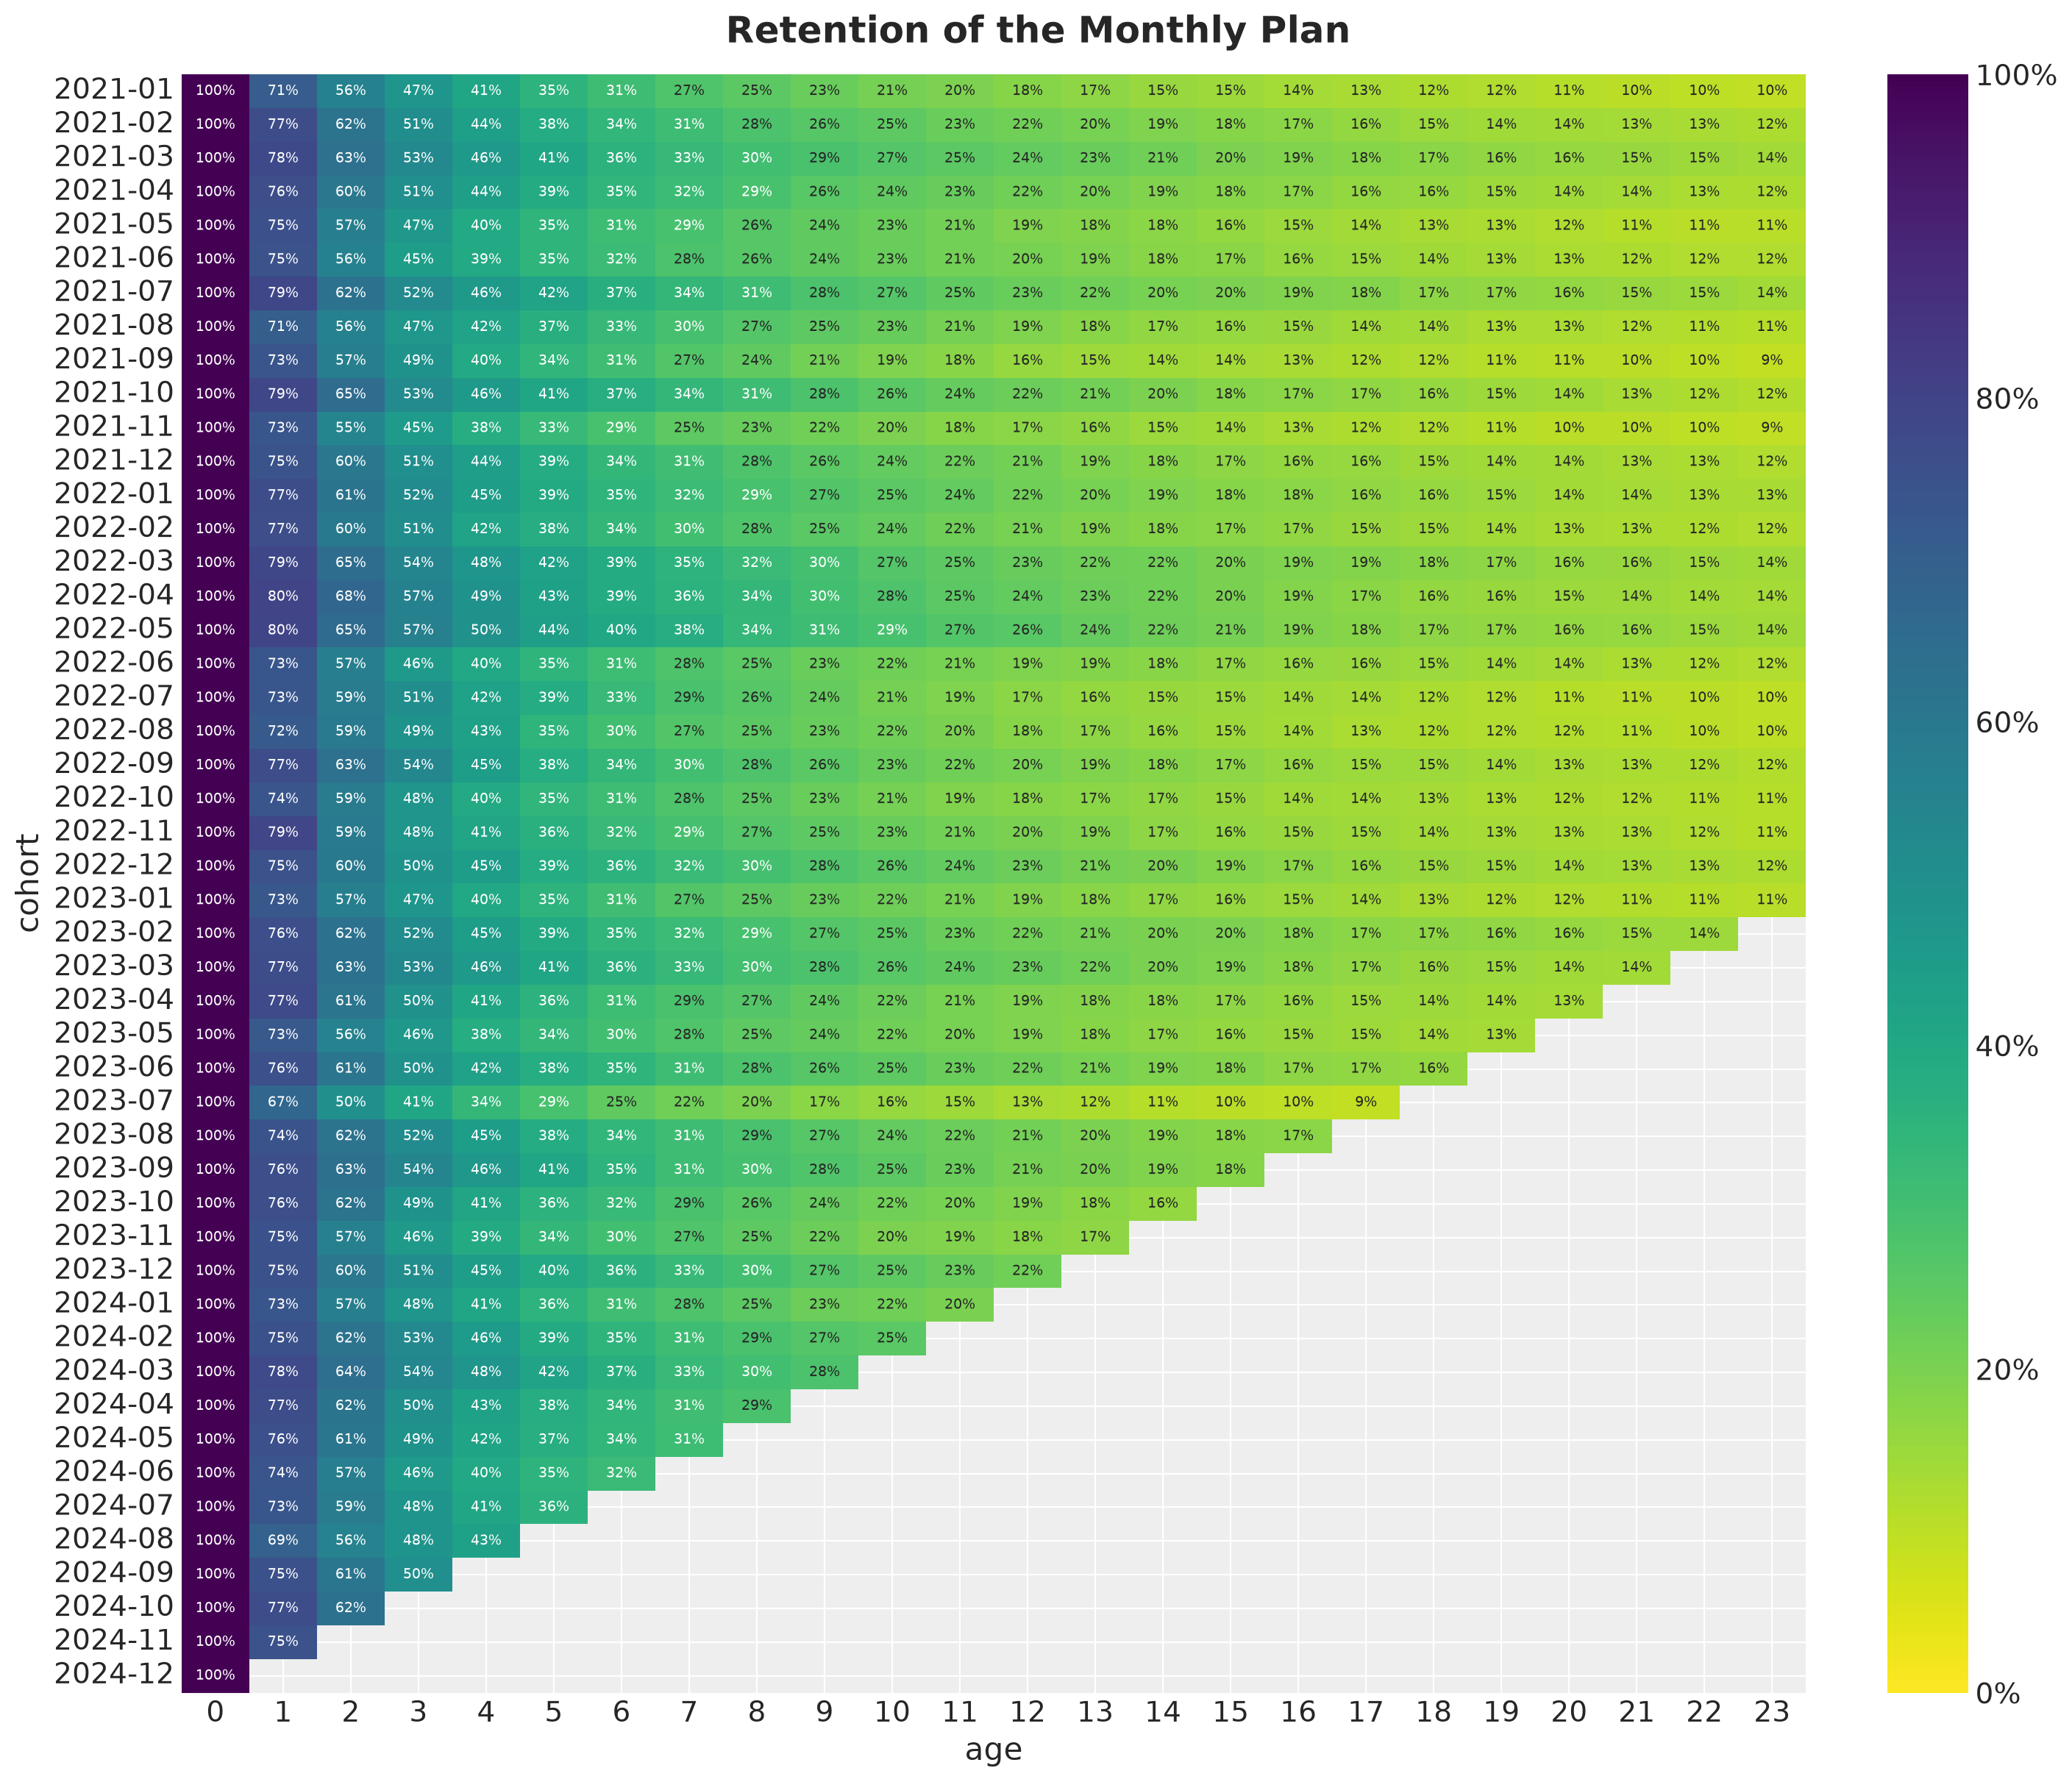

In [13]:
retention_triangle = (
    data.payments.filter(pl.col("plan") == Plan.MONTHLY)
    .join(data.cohorts.select("cohort", "n_users_monthly"), on="cohort")
    .with_columns(retention=pl.col("n_payers") / pl.col("n_users_monthly"))
    .pivot(on="age", index="cohort", values="retention")
    .sort("cohort")
)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    retention_triangle.drop("cohort").to_numpy(),
    cmap="viridis_r",
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".0%",
    annot_kws={"fontsize": 7},
    yticklabels=data.cohort_labels,
    cbar_kws={"format": PercentFormatter(xmax=1, decimals=0)},
    ax=ax,
)
ax.set(xlabel="age", ylabel="cohort")
fig.suptitle("Retention of the Monthly Plan", fontsize=18, fontweight="bold");

Here are two observations:

- The retention falls fast in the first months and slowly afterward, as survivor selection predicts. After one year, between about $13\%$ and $26\%$ of the monthly users of a cohort are still active.
- Some cohorts keep fewer users than their neighbors at every age, for example `2023-07`. This is the cohort effect, and the model has to learn it from the first months of a young cohort.

Now that we have the data, we can describe the funnel model.

## Model Specification

### Funnel Model

The funnel model has one GLM for each step. The first four steps have the same form as in the generator, since the conversion, the plan choice, the refunds and the renewal are Binomial counts with a logistic link in both. The churn is different. The model does not see the users, only the counts of active users of each cohort, so it describes the hazard $\bar{h}_c(a)$ of the whole cohort, a population-averaged quantity. We write the parameters of the churn with a bar to keep them apart from the parameters of the generator, which act on each user. Here is the model:

$$
\begin{align*}
P_c & \sim \text{Binomial}\left(T_c, \text{logit}^{-1}\left(\gamma_0 + \gamma_{m_c}\right)\right) \\
Y_c & \sim \text{Binomial}\left(P_c, \text{logit}^{-1}\left(\psi_0 + \psi_1 z_c\right)\right) \\
F_{c,k} & \sim \text{Binomial}\left(P_{c,k}, \text{logit}^{-1}\left(\rho_k\right)\right) \\
A_{c,a} & \sim \text{Binomial}\left(A_{c,a-1}, 1 - \bar{h}_c(a)\right) \\
\text{logit}\, \bar{h}_c(a) & = \bar{\omega} + \bar{f}_a + \bar{\delta}_{m_c + a} + g_{\lambda}(a) \left(\bar{\kappa} z_c + \bar{u}_c\right) \\
g_{\lambda}(a) & = \frac{1}{1 + \lambda (a - 1)} \\
\bar{f}_1 = 0, \quad \bar{f}_a & = \bar{f}_{a-1} + \varepsilon_a, \quad \varepsilon_a \sim \text{Normal}(0, \bar{\sigma}_f) \\
\bar{u}_c & \sim \text{Normal}(0, \bar{\sigma}_u) \\
Q_c & \sim \text{Binomial}\left(N_{c,\text{yearly}}, \text{logit}^{-1}\left(\eta_0 + \eta_1 z_c\right)\right) \\
X_{c,k,a} & \sim \text{Gamma}\left(B_{c,k,a} \nu_k, \nu_k / \mu_k\right).
\end{align*}
$$

The churn layer is a discrete-time hazard model in the sense of Allison (1982): a logistic regression of the users who pay again on the users who could. Here are its components:

- $\bar{\omega}$ is the logit of the hazard at age $1$ for a typical cohort in an average month, that is, the first-month churn.
- $\bar{f}_a$ is the **age effect**. A random walk over the ages lets it take the shape that survivor selection gives it.
- $\bar{\delta}_m$ is the season of the payment month.
- $\bar{\kappa}$ is the promotion effect and $\bar{u}_c$ the cohort effect, both at age $1$. They fade with age through $g_{\lambda}(a)$, as in the second example of the *Survivor Selection* section.
- A cohort that has paid for a few months tells us about its own effect $\bar{u}_c$, and partial pooling shrinks it toward zero when the cohort has little data. For the youngest cohort it is a draw from $\text{Normal}(0, \bar{\sigma}_u)$.

Here is an important remark: the steps of the funnel share no parameter, and each likelihood conditions on the observed counts of the previous step. So the posterior factorizes into one independent block per step, and one joint fit gives the same posterior as six separate fits. The steps are coupled in the forecast, where the draws of one step feed the next.

We add the value per trial $V_m$ to the model as a deterministic, with the same `value_per_trial` function as the generator. The survival of a new cohort averages over $\bar{u} \sim \text{Normal}(0, \bar{\sigma}_u)$ with the Gauss-Hermite quadrature of the *Generate Data* section, so every posterior draw gives the value per trial without a simulation.

### Prior Elicitation

For the rates of the funnel we state a range on the probability scale and use [PreliZ](https://preliz.readthedocs.io/) to turn it into a prior. The function `pz.maxent` returns the member of a family that puts a given mass between two bounds (the one with maximum entropy, so it adds nothing beyond our constraints). We ask for $94\%$ of the mass between the bounds. Here is the reasoning for each quantity:

- **Conversion:** We believe that between $20\%$ and $90\%$ of the trials of a subscription app convert.
- **Yearly share:** Between $5\%$ and $70\%$ of the paying users choose the yearly plan.
- **Refund:** Between $0.5\%$ and $25\%$ of the first payments are refunded, for each plan.
- **First-month churn:** Between $5\%$ and $60\%$ of the monthly users do not pay a second time.
- **Renewal:** Between $10\%$ and $80\%$ of the yearly users renew.

For these five quantities we use a `LogitNormal`: if a probability follows a $\text{LogitNormal}(s, t)$, its logit follows a $\text{Normal}(s, t)$, which is the prior of the intercept on the logit scale.

For the revenue we reason about two more quantities:

- **Revenue per payment:** The average payment is between $70\%$ and $105\%$ of the list price, since taxes and discounts lower it and a price increase could raise it a little. We use a `LogNormal` for this ratio, so the log of the revenue per payment $\log \mu_k$ is Normal around the log of the list price.
- **Variation of a payment:** A single payment varies around its mean with a coefficient of variation between $5\%$ and $50\%$. For a Gamma with shape $\nu_k$ the coefficient of variation is $1 / \sqrt{\nu_k}$, so if it follows a $\text{LogNormal}(s, t)$, then $\nu_k$ follows a $\text{LogNormal}(-2s, 2t)$.

We run the seven elicitations and plot each density on the scale on which we reasoned, with the two bounds.

/Users/juanitorduz/Documents/website_projects/.pixi/envs/default/lib/python3.14/site-packages/scipy/optimize/_numdiff.py:710: RuntimeWarning: invalid value encountered in subtract
  df = [f_eval - f0 for f_eval in f_evals]


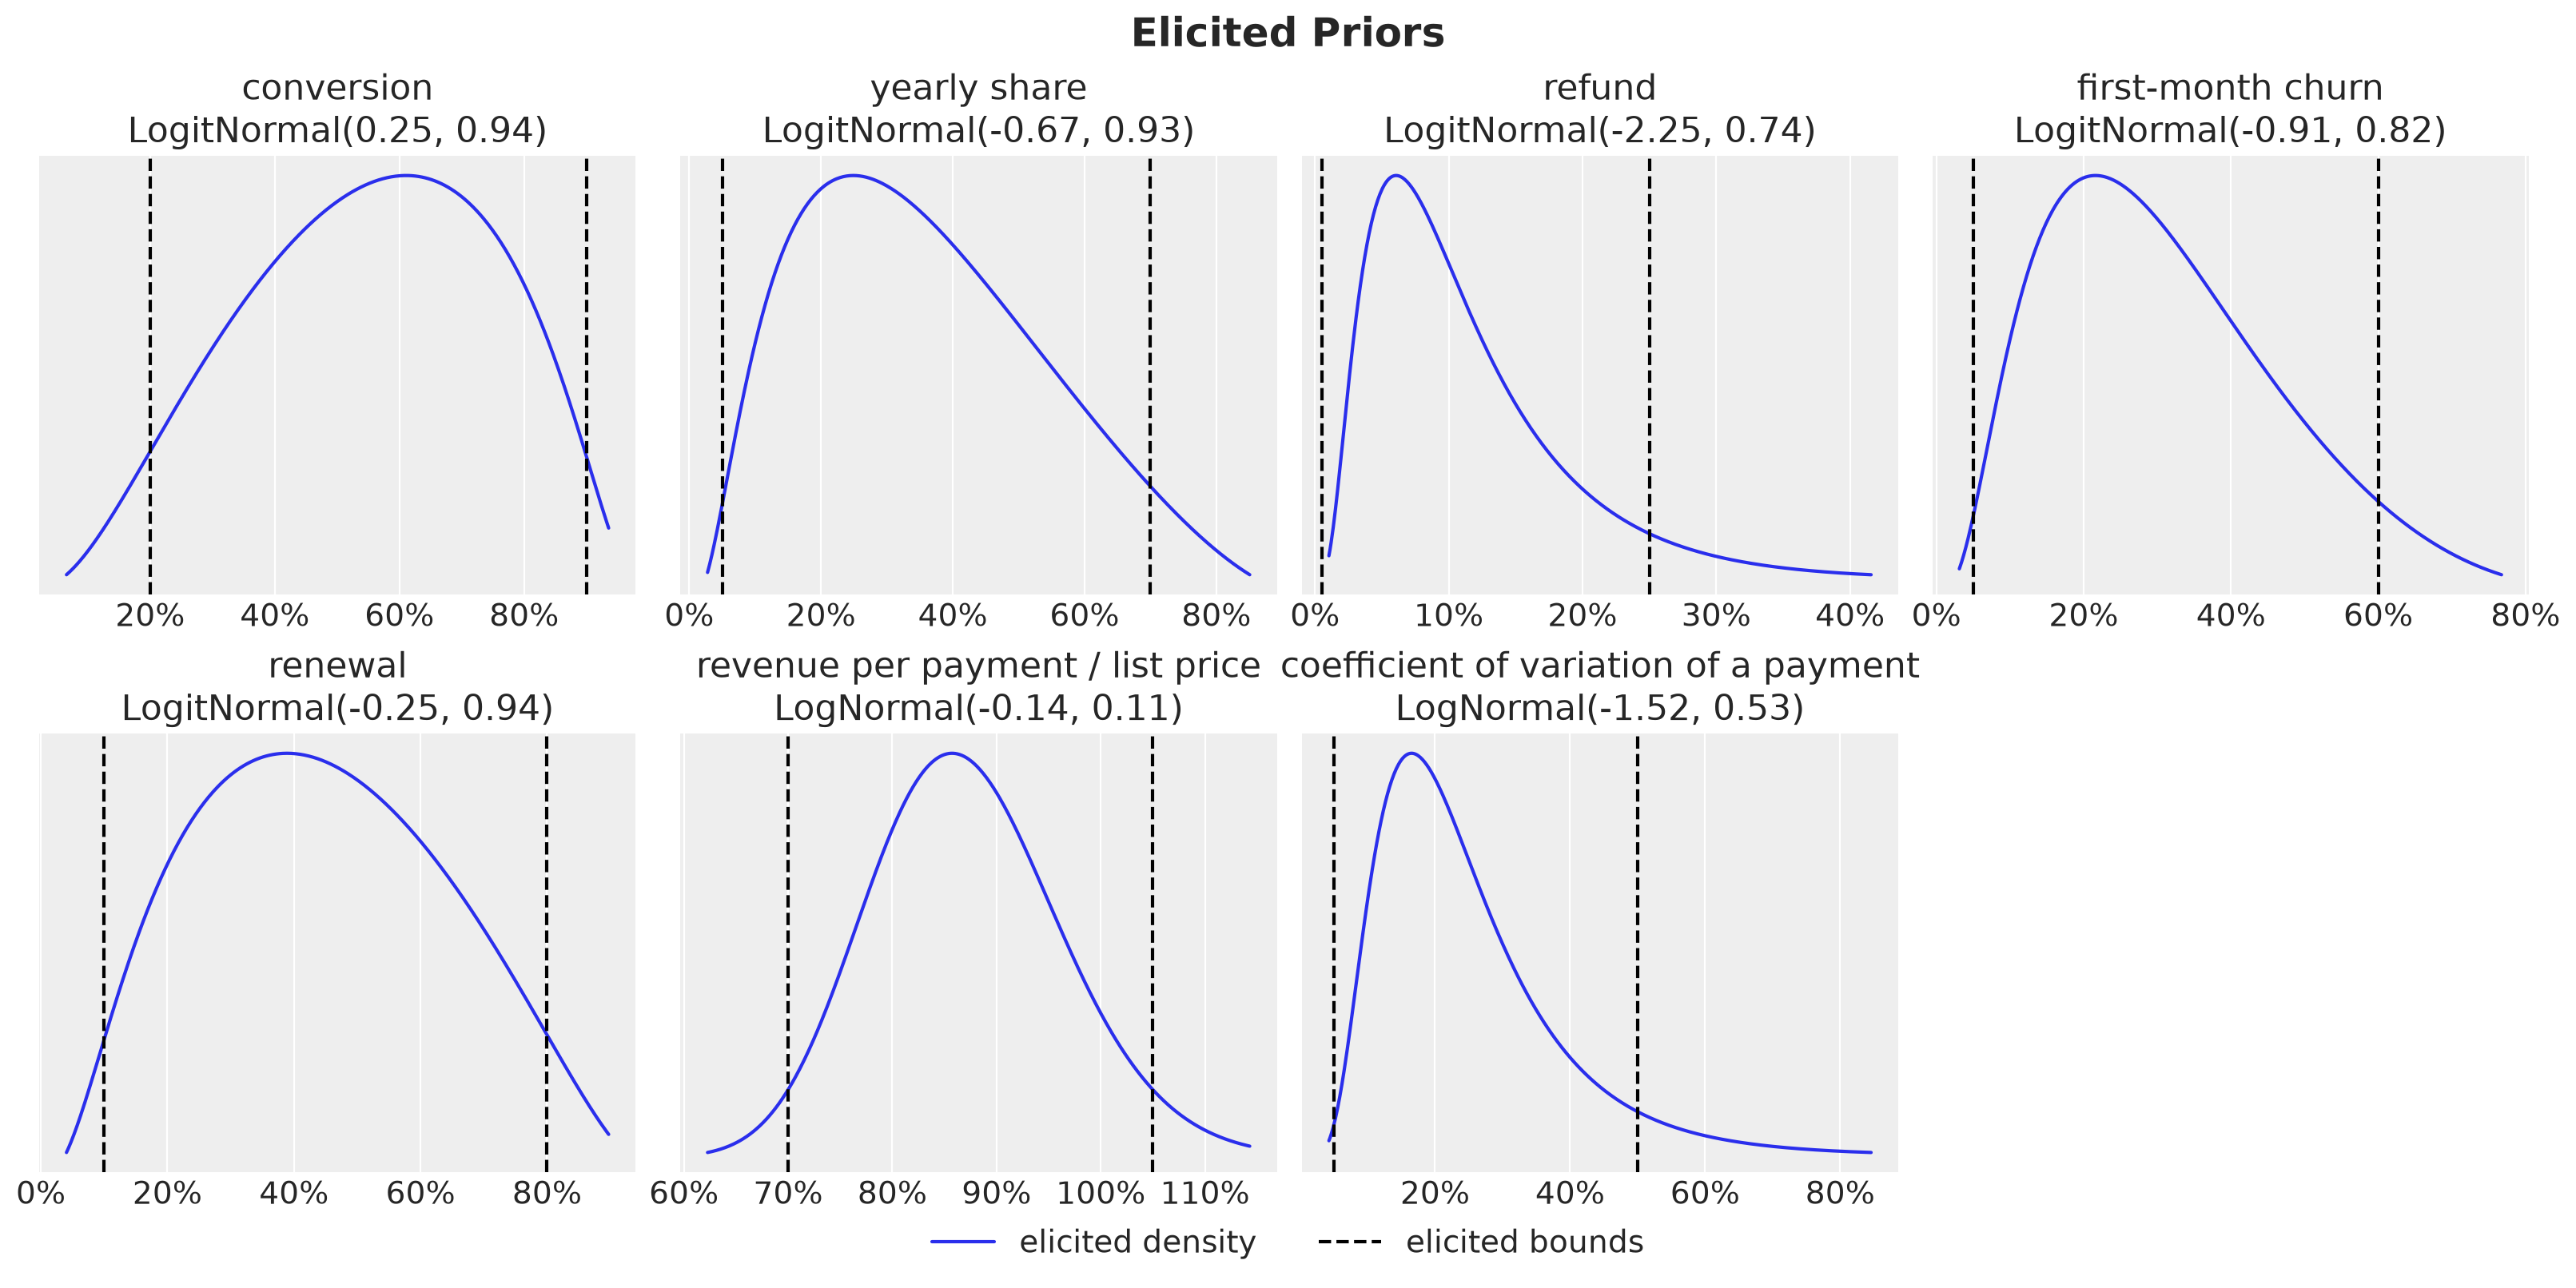

In [14]:
class Elicitation(NamedTuple):
    """A range that we believe in, and the PreliZ family that we fit to it."""

    lower: float
    upper: float
    family: pz.distributions.distributions.Continuous
    label: str


ELICITATION_MASS: Final[float] = 0.94

elicitations = {
    "conversion": Elicitation(0.2, 0.9, pz.LogitNormal(), "conversion"),
    "yearly": Elicitation(0.05, 0.7, pz.LogitNormal(), "yearly share"),
    "refund": Elicitation(0.005, 0.25, pz.LogitNormal(), "refund"),
    "churn": Elicitation(0.05, 0.6, pz.LogitNormal(), "first-month churn"),
    "renewal": Elicitation(0.1, 0.8, pz.LogitNormal(), "renewal"),
    "revenue_ratio": Elicitation(
        0.7, 1.05, pz.LogNormal(), "revenue per payment / list price"
    ),
    "payment_cv": Elicitation(
        0.05, 0.5, pz.LogNormal(), "coefficient of variation of a payment"
    ),
}

priors = {
    name: pz.maxent(
        elicitation.family,
        elicitation.lower,
        elicitation.upper,
        mass=ELICITATION_MASS,
        plot=False,
    )
    for name, elicitation in elicitations.items()
}

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16, 8), layout="constrained")

for ax, (name, elicitation) in zip(axes.flat, elicitations.items(), strict=False):
    prior = priors[name]
    x = np.linspace(*prior.ppf([0.001, 0.995]), 500)
    ax.plot(x, prior.pdf(x), color="C0", label="elicited density")
    ax.axvline(
        elicitation.lower, color="black", linestyle="--", label="elicited bounds"
    )
    ax.axvline(elicitation.upper, color="black", linestyle="--")
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set(
        title=f"{elicitation.label}\n"
        f"{type(prior).__name__}({prior.mu:.2f}, {prior.sigma:.2f})",
        yticks=[],
    )

axes.flat[-1].remove()
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=2)
fig.suptitle("Elicited Priors", fontsize=18, fontweight="bold");

Each panel puts $94\%$ of the mass between the two bounds. The true values of the generator ($60\%$ conversion, $30\%$ yearly share, refunds of $2\%$ and $12\%$, $25\%$ first-month churn, $32\%$ renewal, payments at $95\%$ and $93\%$ of the list price) sit well inside these priors.

The other priors we state directly, on the logit scale:

- **Promotion effects:** The promotion is a discount on the yearly plan, so we expect it to raise the yearly share, and the users that it brings are often deal seekers who churn more and renew less. So we center the three effects on these signs: $\psi_1 \sim \text{Normal}(0.5, 0.5)$, $\bar{\kappa} \sim \text{Normal}(0.2, 0.3)$ and $\eta_1 \sim \text{Normal}(-0.5, 0.5)$. Each prior leaves the opposite sign possible if the data ask for it.
- **Seasons:** The monthly patterns of the conversion and of the churn are `ZeroSumNormal` with scales from a $\text{HalfNormal}(0.5)$ and a $\text{HalfNormal}(0.3)$, since the season moves these rates by a few percentage points.
- **Age effect:** The steps of the random walk get a scale $\bar{\sigma}_f \sim \text{HalfNormal}(0.3)$. Under the sBG model the logit of the hazard falls by about $0.3$ from age $1$ to age $2$ and by less afterward, so this scale allows the steps that survivor selection produces.
- **Fading:** The rate $\lambda \sim \text{HalfNormal}(0.5)$ allows anything from no fading ($\lambda = 0$) to a fast one, and it covers the value $1 / (\alpha + \beta)$ of the sBG cohort.
- **Cohort effects:** The scale $\bar{\sigma}_u \sim \text{HalfNormal}(0.2)$ lets the odds of the first-month churn of a cohort differ from the ones of a typical cohort by about $20\%$.

### Implementation

We now write the model in PyMC. The parameters keep the names of the generator, and the logit-scale priors come from the elicited distributions. The age steps are centered, because thousands of users per cohort and age fix each step tightly, and the cohort effects are non-centered, because the youngest cohorts have little data.

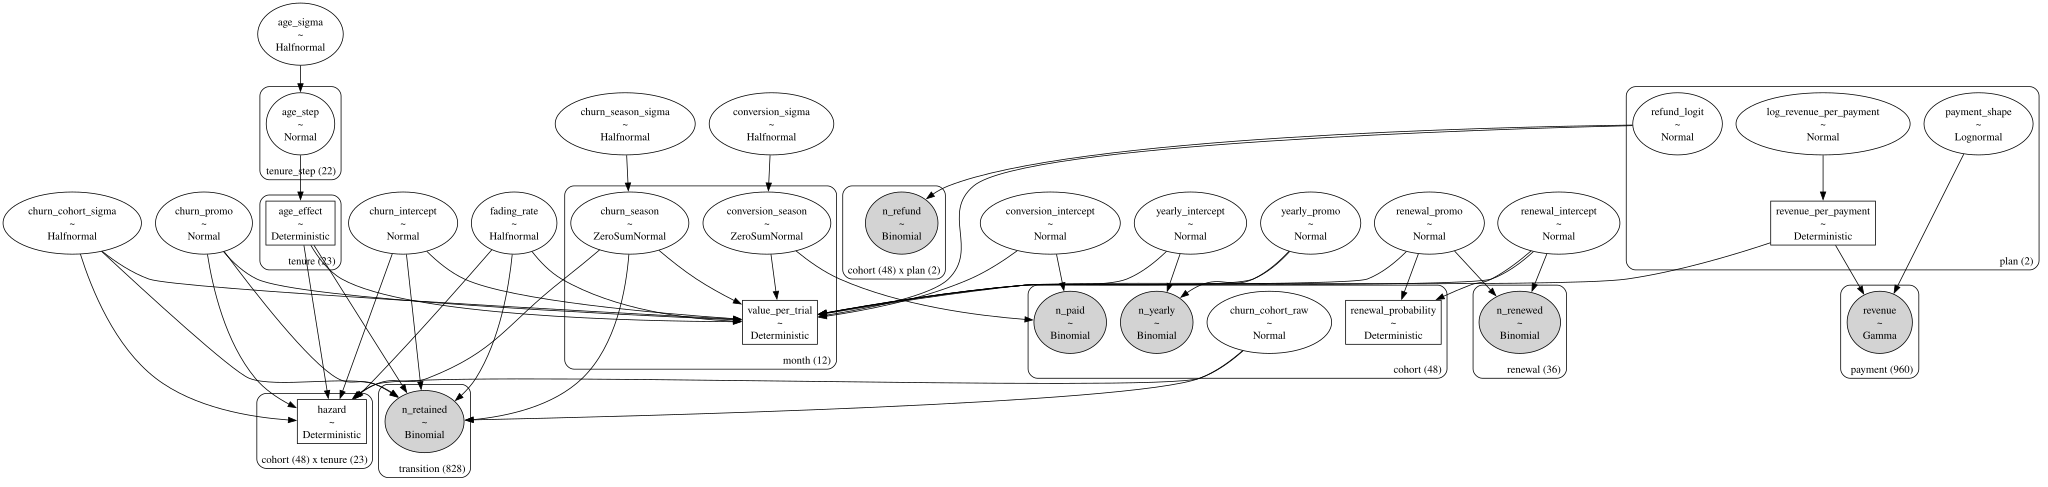

In [15]:
def logit_normal(name: str, prior: pz.LogitNormal, **kwargs) -> pmd.XTensorVariable:
    """Normal prior on the logit scale from an elicited LogitNormal."""
    return pmd.Normal(name, prior.mu, prior.sigma, **kwargs)


def build_model(data: FunnelData) -> pm.Model:
    """Funnel model on the data that we know at the freeze."""
    cohort_index = data.cohorts["cohort"].to_numpy()
    transitions = data.transitions
    renewals = data.renewals
    payers = data.payments.filter(pl.col("n_payers") > 0)
    # positions of the rows of the long tables in the cohort axis
    transition_cohort = np.searchsorted(cohort_index, transitions["cohort"].to_numpy())
    transition_tenure = transitions["age"].to_numpy() - 1
    renewal_cohort = np.searchsorted(cohort_index, renewals["cohort"].to_numpy())
    payment_plan = (payers["plan"] == Plan.YEARLY).cast(pl.Int64).to_numpy()
    n_plan = np.column_stack(
        [
            (data.cohorts["n_paid"] - data.cohorts["n_yearly"]).to_numpy(),
            data.cohorts["n_yearly"].to_numpy(),
        ]
    )
    n_refund = data.cohorts.select("n_refund_monthly", "n_refund_yearly").to_numpy()

    coords = {
        "cohort": data.cohort_labels,
        "month": MONTHS,
        "plan": list(Plan),
        "tenure": calendar.tenures,
        "tenure_step": calendar.tenures[1:],
        "node": QUADRATURE.nodes,
        "transition": np.arange(len(transitions)),
        "renewal": np.arange(len(renewals)),
        "payment": np.arange(len(payers)),
    }

    with pm.Model(coords=coords) as model:
        start_month = pmd.as_xtensor(
            data.cohorts["start_month"].to_numpy(), dims=("cohort",)
        )
        promo = pmd.as_xtensor(data.cohorts["promo"].to_numpy(), dims=("cohort",))
        payment_month = pmd.as_xtensor(
            calendar.payment_month(data.cohorts["start_month"].to_numpy()),
            dims=("cohort", "tenure"),
        )
        tenure = pmd.as_xtensor(calendar.tenures.astype(float), dims=("tenure",))

        # --- conversion ---
        conversion_intercept = logit_normal(
            "conversion_intercept", priors["conversion"]
        )
        conversion_sigma = pmd.HalfNormal("conversion_sigma", 0.5)
        conversion_season = pmd.ZeroSumNormal(
            "conversion_season",
            sigma=conversion_sigma,
            core_dims="month",
            dims="month",
        )
        pm.Binomial(
            "n_paid",
            n=data.cohorts["n_trials"].to_numpy(),
            logit_p=(
                conversion_intercept + conversion_season.isel(month=start_month)
            ).values,
            observed=data.cohorts["n_paid"].to_numpy(),
            dims="cohort",
        )

        # --- plan choice ---
        yearly_intercept = logit_normal("yearly_intercept", priors["yearly"])
        yearly_promo = pmd.Normal("yearly_promo", 0.5, 0.5)
        pm.Binomial(
            "n_yearly",
            n=data.cohorts["n_paid"].to_numpy(),
            logit_p=(yearly_intercept + yearly_promo * promo).values,
            observed=data.cohorts["n_yearly"].to_numpy(),
            dims="cohort",
        )

        # --- refunds ---
        refund_logit = logit_normal("refund_logit", priors["refund"], dims="plan")
        pm.Binomial(
            "n_refund",
            n=n_plan,
            logit_p=refund_logit.values,
            observed=n_refund,
            dims=("cohort", "plan"),
        )

        # --- monthly churn ---
        churn_intercept = logit_normal("churn_intercept", priors["churn"])
        age_sigma = pmd.HalfNormal("age_sigma", 0.3)
        age_step = pmd.Normal("age_step", 0.0, age_sigma, dims="tenure_step")
        age_effect = pmd.Deterministic(
            "age_effect",
            pmd.as_xtensor(
                pt.concatenate([pt.zeros(1), age_step.cumsum("tenure_step").values]),
                dims=("tenure",),
            ),
        )
        churn_season_sigma = pmd.HalfNormal("churn_season_sigma", 0.3)
        churn_season = pmd.ZeroSumNormal(
            "churn_season", sigma=churn_season_sigma, core_dims="month", dims="month"
        )
        churn_promo = pmd.Normal("churn_promo", 0.2, 0.3)
        churn_cohort_sigma = pmd.HalfNormal("churn_cohort_sigma", 0.2)
        churn_cohort_raw = pmd.Normal("churn_cohort_raw", 0.0, 1.0, dims="cohort")
        fading_rate = pmd.HalfNormal("fading_rate", 0.5)
        fading = 1 / (1 + fading_rate * (tenure - 1))
        logit_hazard = (
            churn_intercept
            + age_effect
            + churn_season.isel(month=payment_month)
            + fading * (churn_promo * promo + churn_cohort_sigma * churn_cohort_raw)
        ).transpose("cohort", "tenure")
        pmd.Deterministic("hazard", pmd.math.sigmoid(logit_hazard))
        pm.Binomial(
            "n_retained",
            n=transitions["n_previous"].to_numpy(),
            logit_p=-logit_hazard.values[transition_cohort, transition_tenure],
            observed=transitions["n_payers"].to_numpy(),
            dims="transition",
        )

        # --- yearly renewal ---
        renewal_intercept = logit_normal("renewal_intercept", priors["renewal"])
        renewal_promo = pmd.Normal("renewal_promo", -0.5, 0.5)
        renewal_logit = renewal_intercept + renewal_promo * promo
        pmd.Deterministic("renewal_probability", pmd.math.sigmoid(renewal_logit))
        pm.Binomial(
            "n_renewed",
            n=data.cohorts["n_users_yearly"].to_numpy()[renewal_cohort],
            logit_p=renewal_logit.values[renewal_cohort],
            observed=renewals["n_payers"].to_numpy(),
            dims="renewal",
        )

        # --- revenue ---
        ratio_prior = priors["revenue_ratio"]
        log_revenue_per_payment = pmd.Normal(
            "log_revenue_per_payment",
            pmd.as_xtensor(
                np.log(list(LIST_PRICE.values())) + ratio_prior.mu, dims=("plan",)
            ),
            ratio_prior.sigma,
        )
        cv_prior = priors["payment_cv"]
        payment_shape = pmd.LogNormal(
            "payment_shape", -2 * cv_prior.mu, 2 * cv_prior.sigma, dims="plan"
        )
        revenue_per_payment = pmd.Deterministic(
            "revenue_per_payment", pmd.math.exp(log_revenue_per_payment)
        )
        shape = payment_shape.values[payment_plan]
        pm.Gamma(
            "revenue",
            alpha=payers["n_payers"].to_numpy() * shape,
            beta=shape / revenue_per_payment.values[payment_plan],
            observed=payers["revenue"].to_numpy(),
            dims="payment",
        )

        # --- value per trial of a new cohort, by start month ---
        new_start_month = np.arange(12)
        new_promo = pmd.as_xtensor(
            (new_start_month == calendar.promo_month).astype(float), dims=("month",)
        )
        new_payment_month = pmd.as_xtensor(
            calendar.payment_month(new_start_month), dims=("month", "tenure")
        )
        new_cohort_effect = churn_cohort_sigma * pmd.as_xtensor(
            QUADRATURE.nodes, dims=("node",)
        )
        new_hazard = pmd.math.sigmoid(
            churn_intercept
            + age_effect
            + churn_season.isel(month=new_payment_month)
            + fading * (churn_promo * new_promo + new_cohort_effect)
        )
        node_weight = pmd.as_xtensor(QUADRATURE.weights, dims=("node",))
        monthly_payments = 1 + (survival(new_hazard) * node_weight).sum(
            ("node", "tenure")
        )
        pmd.Deterministic(
            "value_per_trial",
            value_per_trial(
                conversion=pmd.math.sigmoid(conversion_intercept + conversion_season),
                yearly_share=pmd.math.sigmoid(
                    yearly_intercept + yearly_promo * new_promo
                ),
                refund=pmd.math.sigmoid(refund_logit),
                monthly_payments=monthly_payments,
                renewal=pmd.math.sigmoid(renewal_intercept + renewal_promo * new_promo),
                revenue_per_payment=revenue_per_payment,
            ),
        )

    return model


model = build_model(data)

pm.model_to_graphviz(model)

The graph has the six observed nodes of the funnel steps, each with its own parameters. The deterministics `hazard` and `renewal_probability` hold the quantities that the forecast needs for every cohort, and `value_per_trial` holds the value of a trial by start month.

## Prior Predictive Checks

Before we fit the model, we draw from the priors and compare the draws with the data. We look at the **one-month retention** by age: the share of the monthly users active at age $a - 1$ who pay again at age $a$, pooled over the cohorts. It is one minus the pooled hazard, and it is the quantity that drives the value of a monthly user. We plot the $50\%$ and $94\%$ highest density intervals (HDI) of the draws, the narrowest intervals that hold these shares of the draws, and the observed retention.

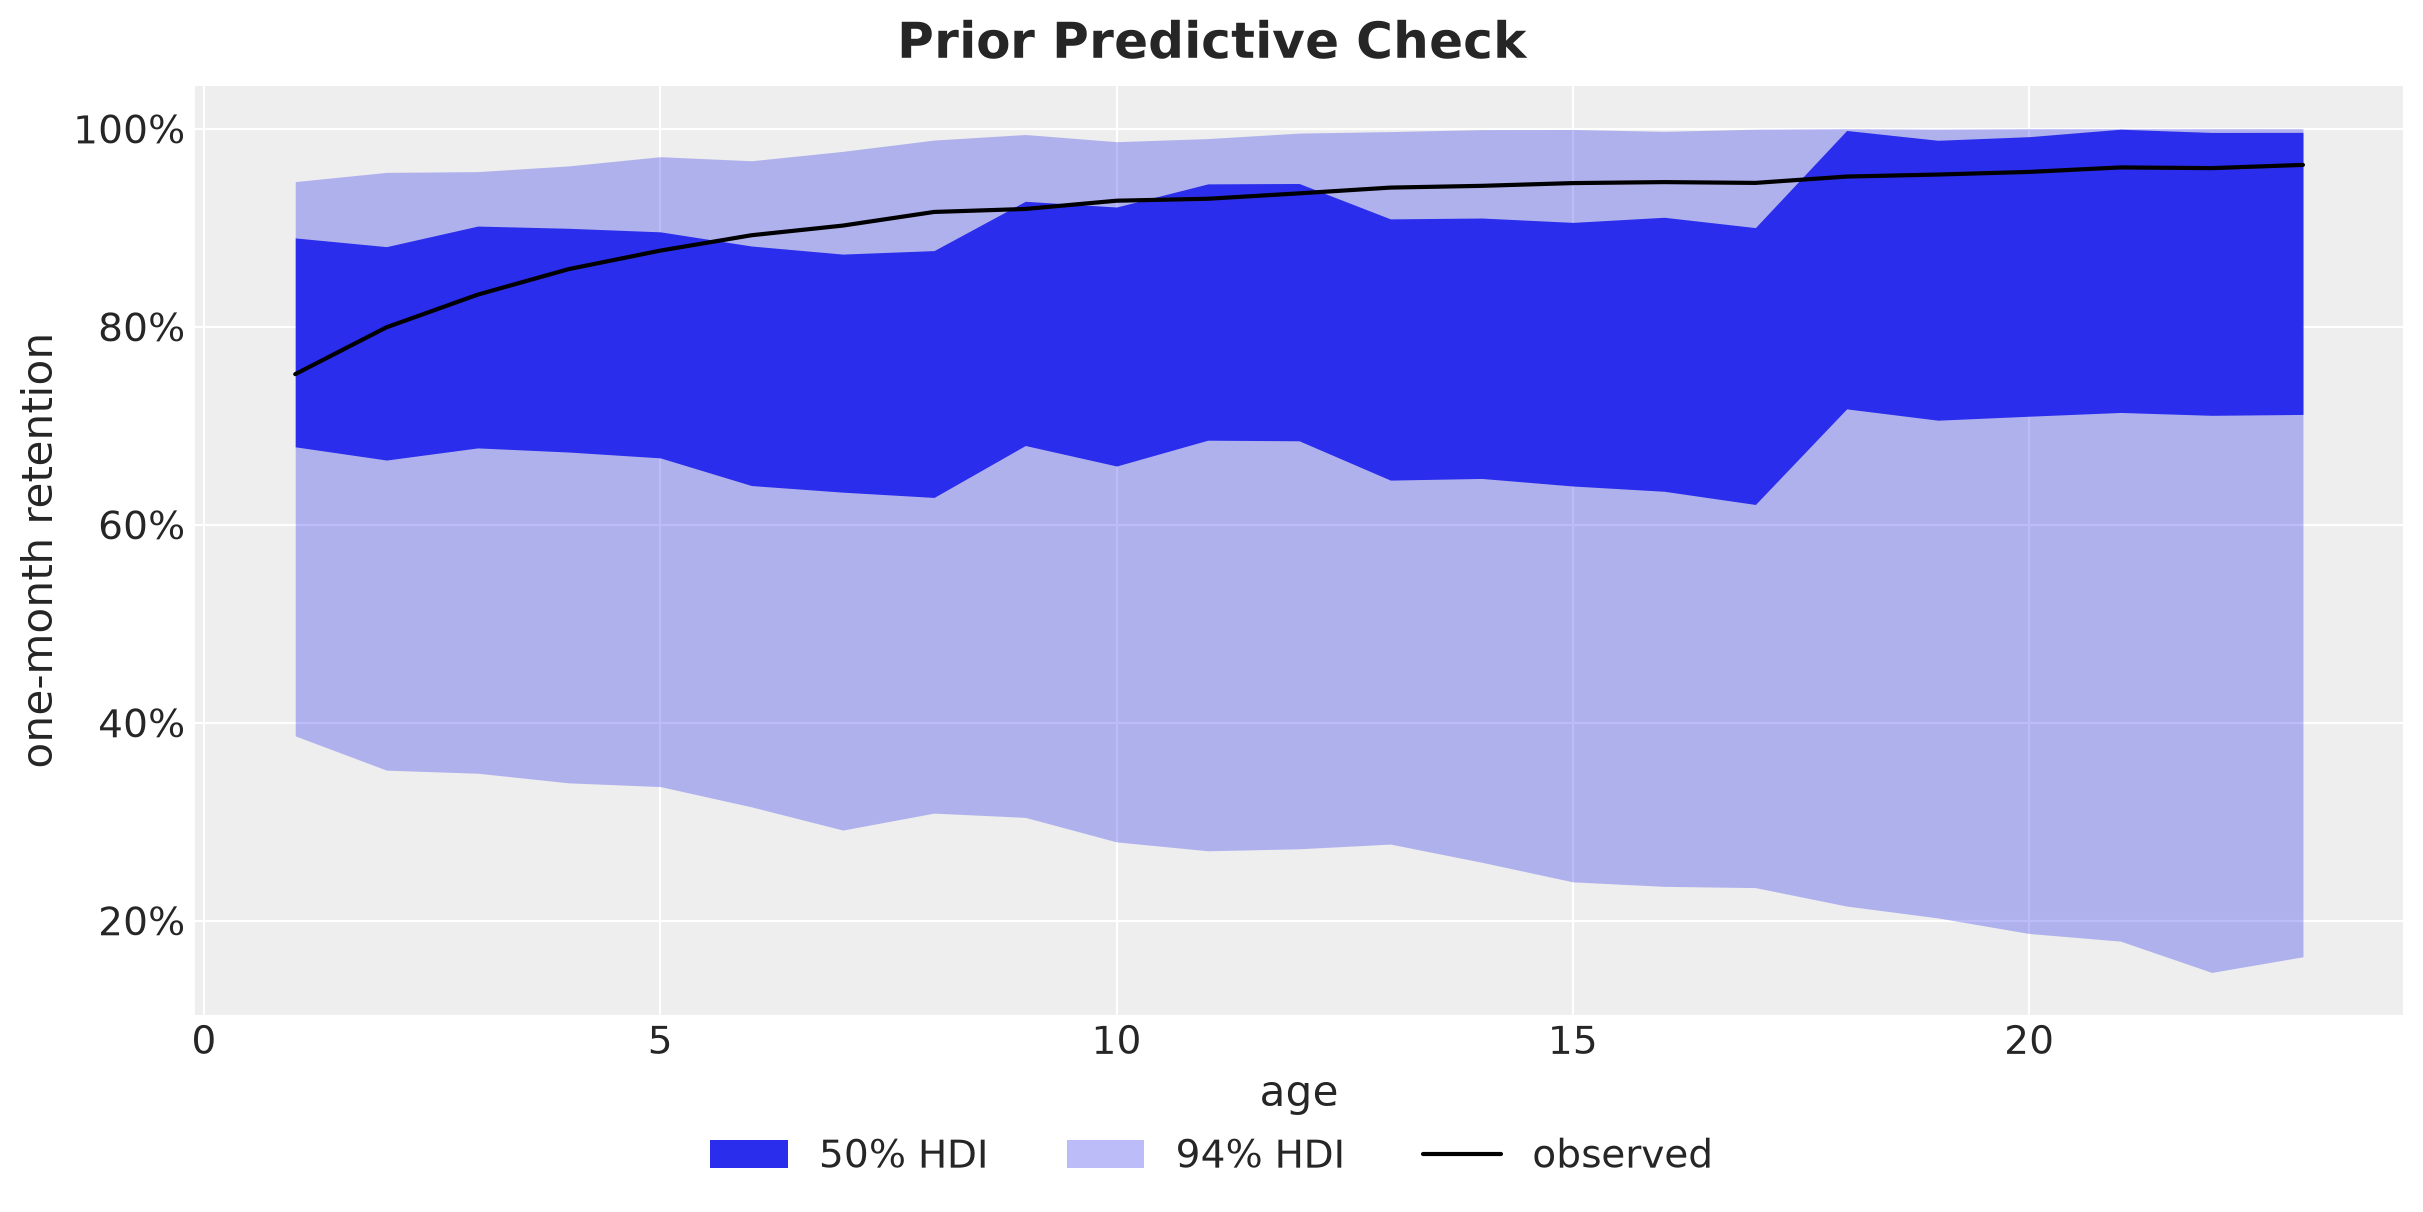

In [16]:
def pooled_retention(
    n_retained: xr.DataArray, data: FunnelData, by: str
) -> xr.DataArray:
    """Share of the users at risk who pay again, pooled over cohorts, by a column."""
    transitions = data.transitions
    key = xr.DataArray(transitions[by].to_numpy(), dims="transition", name=by)
    n_previous = xr.DataArray(transitions["n_previous"].to_numpy(), dims="transition")
    return n_retained.groupby(key).sum() / n_previous.groupby(key).sum()


def retention_tree(samples: xr.DataArray, observed: xr.DataArray) -> xr.DataTree:
    """ArviZ container for `plot_lm`: retention draws by age, observed retention."""
    ages = samples["age"].values.astype(float)
    return az.from_dict(
        {
            "posterior_predictive": {"retention": samples.values},
            "observed_data": {"retention": observed.values},
            "constant_data": {"x": ages},
        },
        coords={"age": ages},
        dims={"retention": ["age"], "x": ["age"]},
    )


def plot_retention_check(tree: xr.DataTree) -> az.PlotCollection:
    """Bands of the retention draws with the observed retention on top."""
    pc = az.plot_lm(
        tree,
        x="x",
        y="retention",
        smooth=False,
        ci_prob=(0.5, HDI_PROB),
        visuals={
            "ci_band": {"color": "C0"},
            "observed_scatter": False,
            "pe_line": False,
        },
        figure_kwargs={"figsize": (12, 6)},
    )
    ax = pc.viz["plot"]["x"].item()
    pc.viz["ci_band"]["x"].sel(prob=HDI_PROB).item().set_label(f"{HDI_PROB:.0%} HDI")
    pc.viz["ci_band"]["x"].sel(prob=0.5).item().set_label("50% HDI")
    ax.plot(
        tree["constant_data"]["x"].values,
        tree["observed_data"]["retention"].values,
        color="black",
        label="observed",
    )
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set(xlabel="age", ylabel="one-month retention", title="")
    pc.viz["figure"].item().legend(loc="outside lower center", ncol=3)
    return pc


observed_retention = pooled_retention(
    xr.DataArray(data.transitions["n_payers"].to_numpy(), dims="transition"),
    data,
    by="age",
)

prior_idata = pm.sample_prior_predictive(
    draws=1_000, model=model, var_names=["n_retained"], random_seed=rng
)
prior_retention = pooled_retention(
    prior_idata["prior_predictive"]["n_retained"], data, by="age"
)

pc = plot_retention_check(retention_tree(prior_retention, observed_retention))
pc.viz["figure"].item().suptitle(
    "Prior Predictive Check", fontsize=18, fontweight="bold"
);

At every age, the $94\%$ band of the priors reaches from below $35\%$ to above $90\%$. The observed retention, which rises from $75\%$ at age $1$ to $96\%$ at age $23$, sits inside it. The bands do not rise with age because the random walk of the age effect has no preferred direction, so the rise of the retention has to come from the data. Nothing here is implausible for a subscription app, so we move on to the fit.

## Model Fitting

We fit the model with NUTS from [nutpie](https://github.com/pymc-devs/nutpie), a fast implementation that we use because the *Backtest* section refits the model eleven more times. Then we draw from the posterior predictive distribution for the checks of the *Posterior Predictive Checks* section.

In [17]:
def fit(data: FunnelData) -> xr.DataTree:
    """Build the funnel model on the data of a freeze and sample its posterior."""
    with build_model(data):
        return pm.sample(nuts_sampler="nutpie", random_seed=rng, progressbar=False)


idata = fit(data)
idata = pm.sample_posterior_predictive(
    idata, model=model, extend_inferencedata=True, random_seed=rng, progressbar=False
)

Let's check the sampler diagnostics for the scalar parameters.

In [18]:
GLOBAL_PARAMS: Final[list[str]] = [
    "conversion_intercept",
    "conversion_sigma",
    "yearly_intercept",
    "yearly_promo",
    "refund_logit",
    "churn_intercept",
    "age_sigma",
    "churn_season_sigma",
    "churn_promo",
    "churn_cohort_sigma",
    "fading_rate",
    "renewal_intercept",
    "renewal_promo",
    "log_revenue_per_payment",
    "payment_shape",
]

az.summary(idata, var_names=GLOBAL_PARAMS, round_to=3)

,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
conversion_intercept,0.406,0.005,0.397,0.416,6091.960,3039.156,1.000,0.000,0.000
conversion_sigma,0.414,0.096,0.246,0.591,5310.047,2188.950,1.002,0.001,0.002
yearly_intercept,-0.855,0.007,-0.868,-0.842,4767.360,3106.175,1.000,0.000,0.000
yearly_promo,0.933,0.019,0.894,0.967,5045.450,3115.815,1.001,0.000,0.000
refund_logit[monthly],-3.881,0.026,-3.929,-3.833,6768.150,2979.231,1.000,0.000,0.000
refund_logit[yearly],-1.994,0.017,-2.026,-1.964,6391.282,2963.419,1.001,0.000,0.000
churn_intercept,-1.125,0.019,-1.159,-1.089,583.870,976.692,1.006,0.001,0.000
age_sigma,0.135,0.022,0.096,0.174,4168.729,3118.670,1.001,0.000,0.000
churn_season_sigma,0.106,0.028,0.062,0.156,4686.058,2586.113,1.001,0.000,0.001
churn_promo,0.163,0.062,0.044,0.282,860.765,1144.097,1.003,0.002,0.002


The table shows $\hat{R}$ values below $1.01$ and bulk effective sample sizes above $580$ for every scalar parameter. Two numbers of the churn layer connect to the *Survivor Selection* section:

- The fading rate has a posterior mean of $0.25$, the value $1 / (\alpha + \beta)$ of the sBG cohort.
- The promotion effect at age $1$ has a $94\%$ HDI from $0.04$ to $0.28$, which covers the gap of about $0.2$ that a shift of $0.25$ of every user makes at age $1$ in the *Fading of a Persistent Shift* figure. The interval is wide because only a few cohorts get the promotion.

Next, let's check all the parameters at once, including the age steps and the cohort effects, and look at the traces of the churn layer.

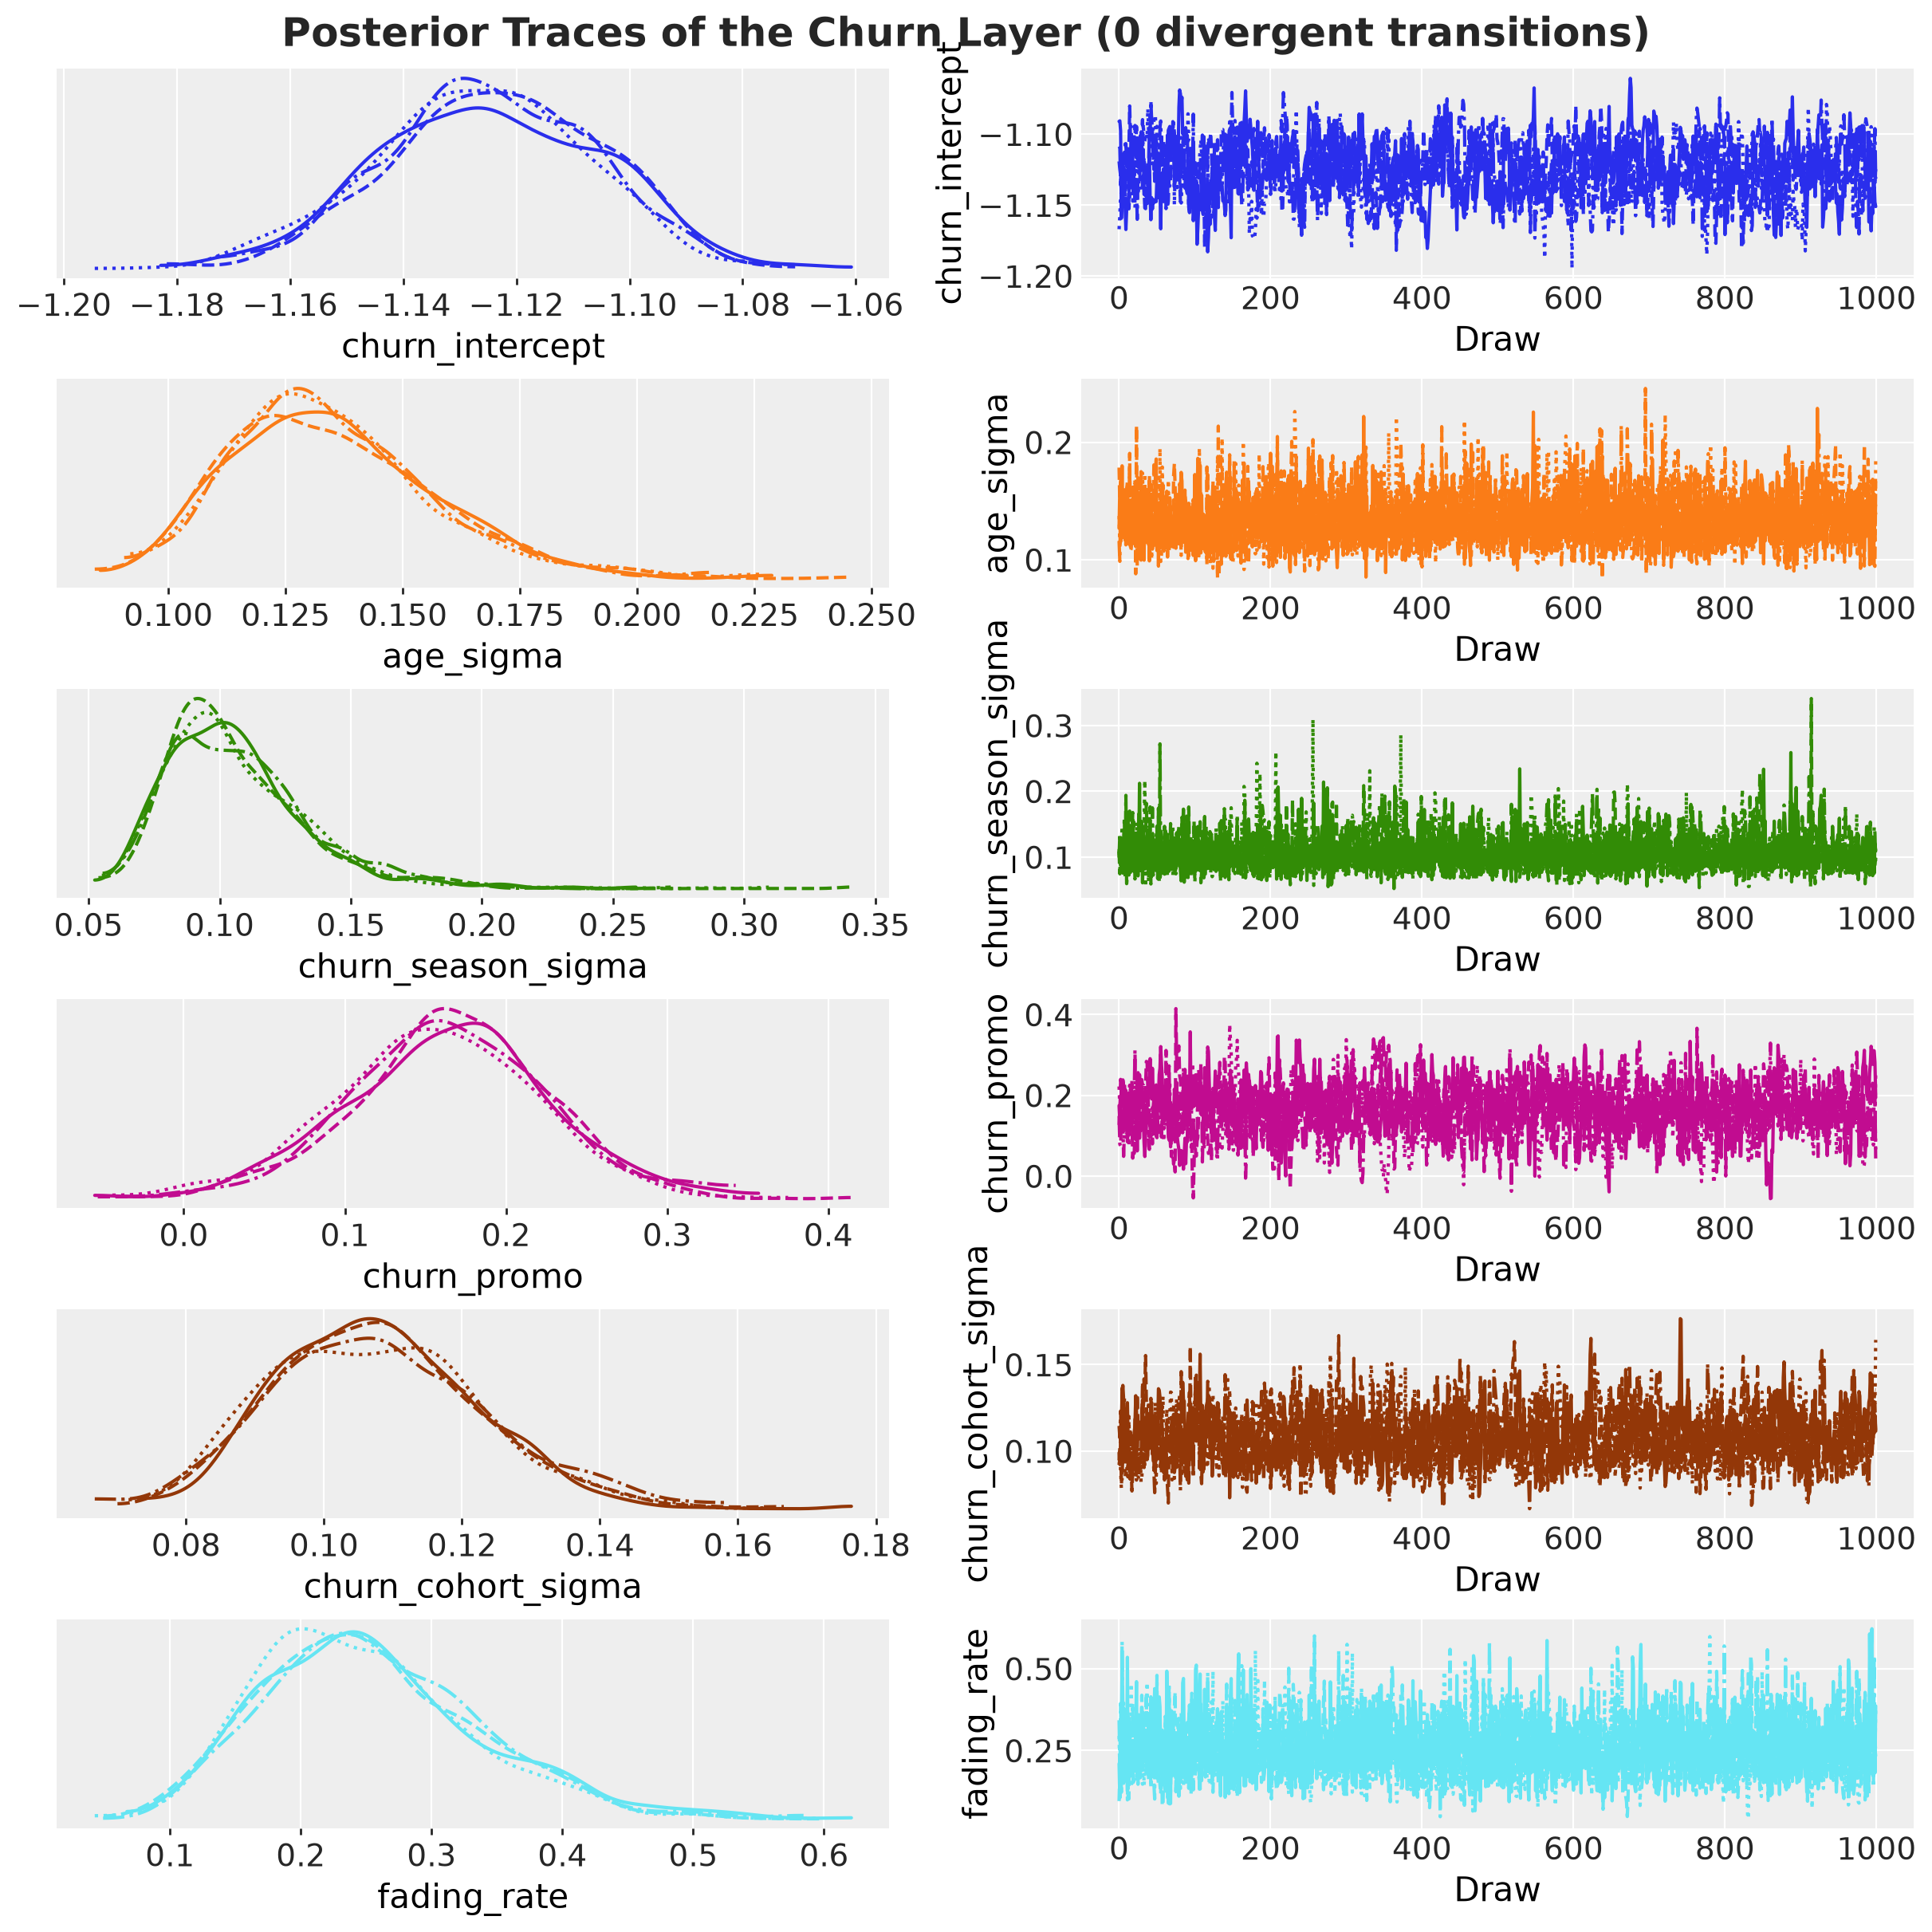

In [19]:
full_summary = az.summary(
    idata, var_names=[rv.name for rv in model.free_RVs], kind="diagnostics"
)
num_divergences = int(idata["sample_stats"]["diverging"].sum())

assert full_summary["r_hat"].max() < 1.01
assert full_summary["ess_bulk"].min() > 400

pc = az.plot_trace_dist(
    idata,
    var_names=[
        "churn_intercept",
        "age_sigma",
        "churn_season_sigma",
        "churn_promo",
        "churn_cohort_sigma",
        "fading_rate",
    ],
    figure_kwargs={"figsize": (12, 12)},
)
pc.viz["figure"].item().suptitle(
    f"Posterior Traces of the Churn Layer ({num_divergences} divergent transitions)",
    fontsize=18,
    fontweight="bold",
);

The chains mix well and the sampler had no divergent transitions. The assertions confirm that every $\hat{R}$ is below $1.01$ and every bulk effective sample size is above $400$.

### Parameter Recovery

Next, we check that the posterior recovers the parameters we fixed in the generator. We start with the steps of the funnel that have the same form in both models. The vertical lines are the true values.

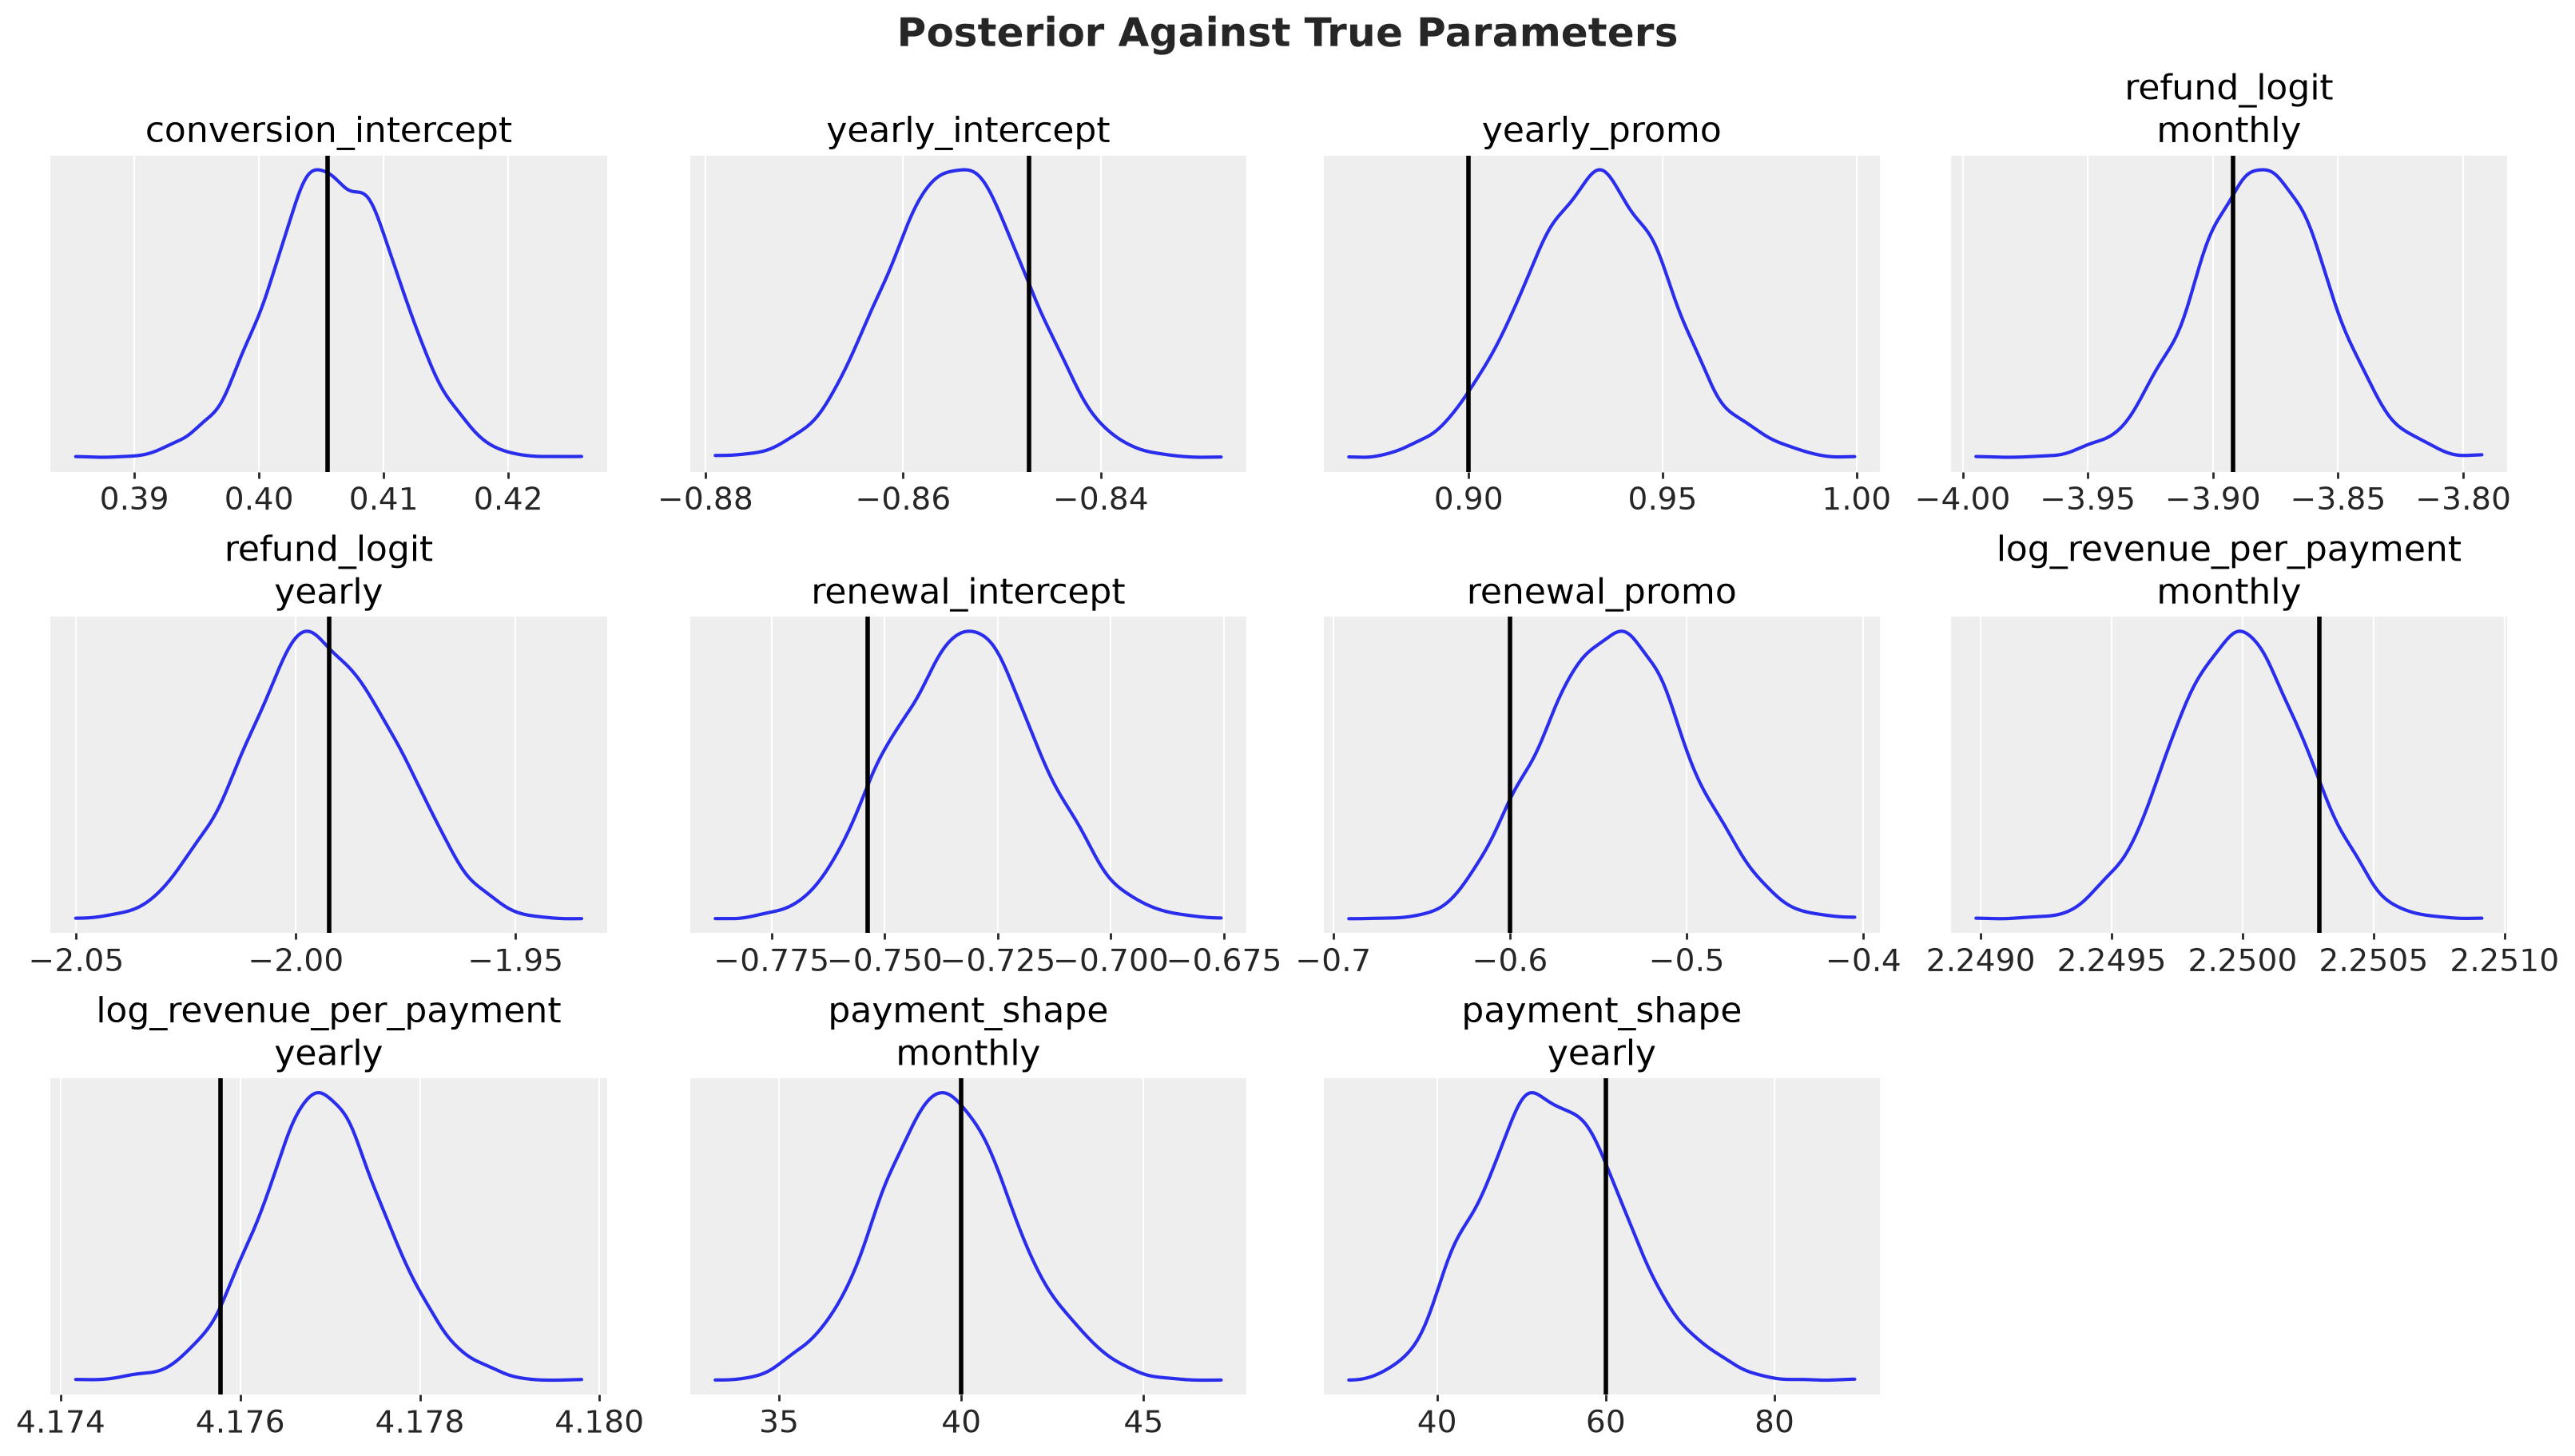

In [20]:
EXACT_PARAMS: Final[list[str]] = [
    "conversion_intercept",
    "yearly_intercept",
    "yearly_promo",
    "refund_logit",
    "renewal_intercept",
    "renewal_promo",
    "log_revenue_per_payment",
    "payment_shape",
]

true_values = xr.Dataset(
    {
        name: ("plan", TRUE_PARAMS[name])
        if np.ndim(TRUE_PARAMS[name])
        else float(TRUE_PARAMS[name])
        for name in EXACT_PARAMS
    },
    coords={"plan": list(Plan)},
)

pc = az.plot_dist(
    idata,
    var_names=EXACT_PARAMS,
    kind="kde",
    visuals={
        "point_estimate": False,
        "point_estimate_text": False,
        "credible_interval": False,
    },
    col_wrap=4,
    figure_kwargs={"figsize": (16, 9)},
)
az.add_lines(
    pc,
    values=true_values,
    aes_by_visuals={"ref_line": []},
    visuals={
        "ref_line": {"color": "black", "linestyle": "-", "linewidth": 2, "zorder": 2}
    },
)
pc.viz["figure"].item().suptitle(
    "Posterior Against True Parameters", fontsize=18, fontweight="bold"
);

The true values sit inside the posterior mass of every parameter, which is good! The posteriors are narrow because every likelihood counts thousands of users.

The monthly pattern of the conversion also has the same form in both models. We compare it with its true values in a forest plot, with the true values as a second entry.

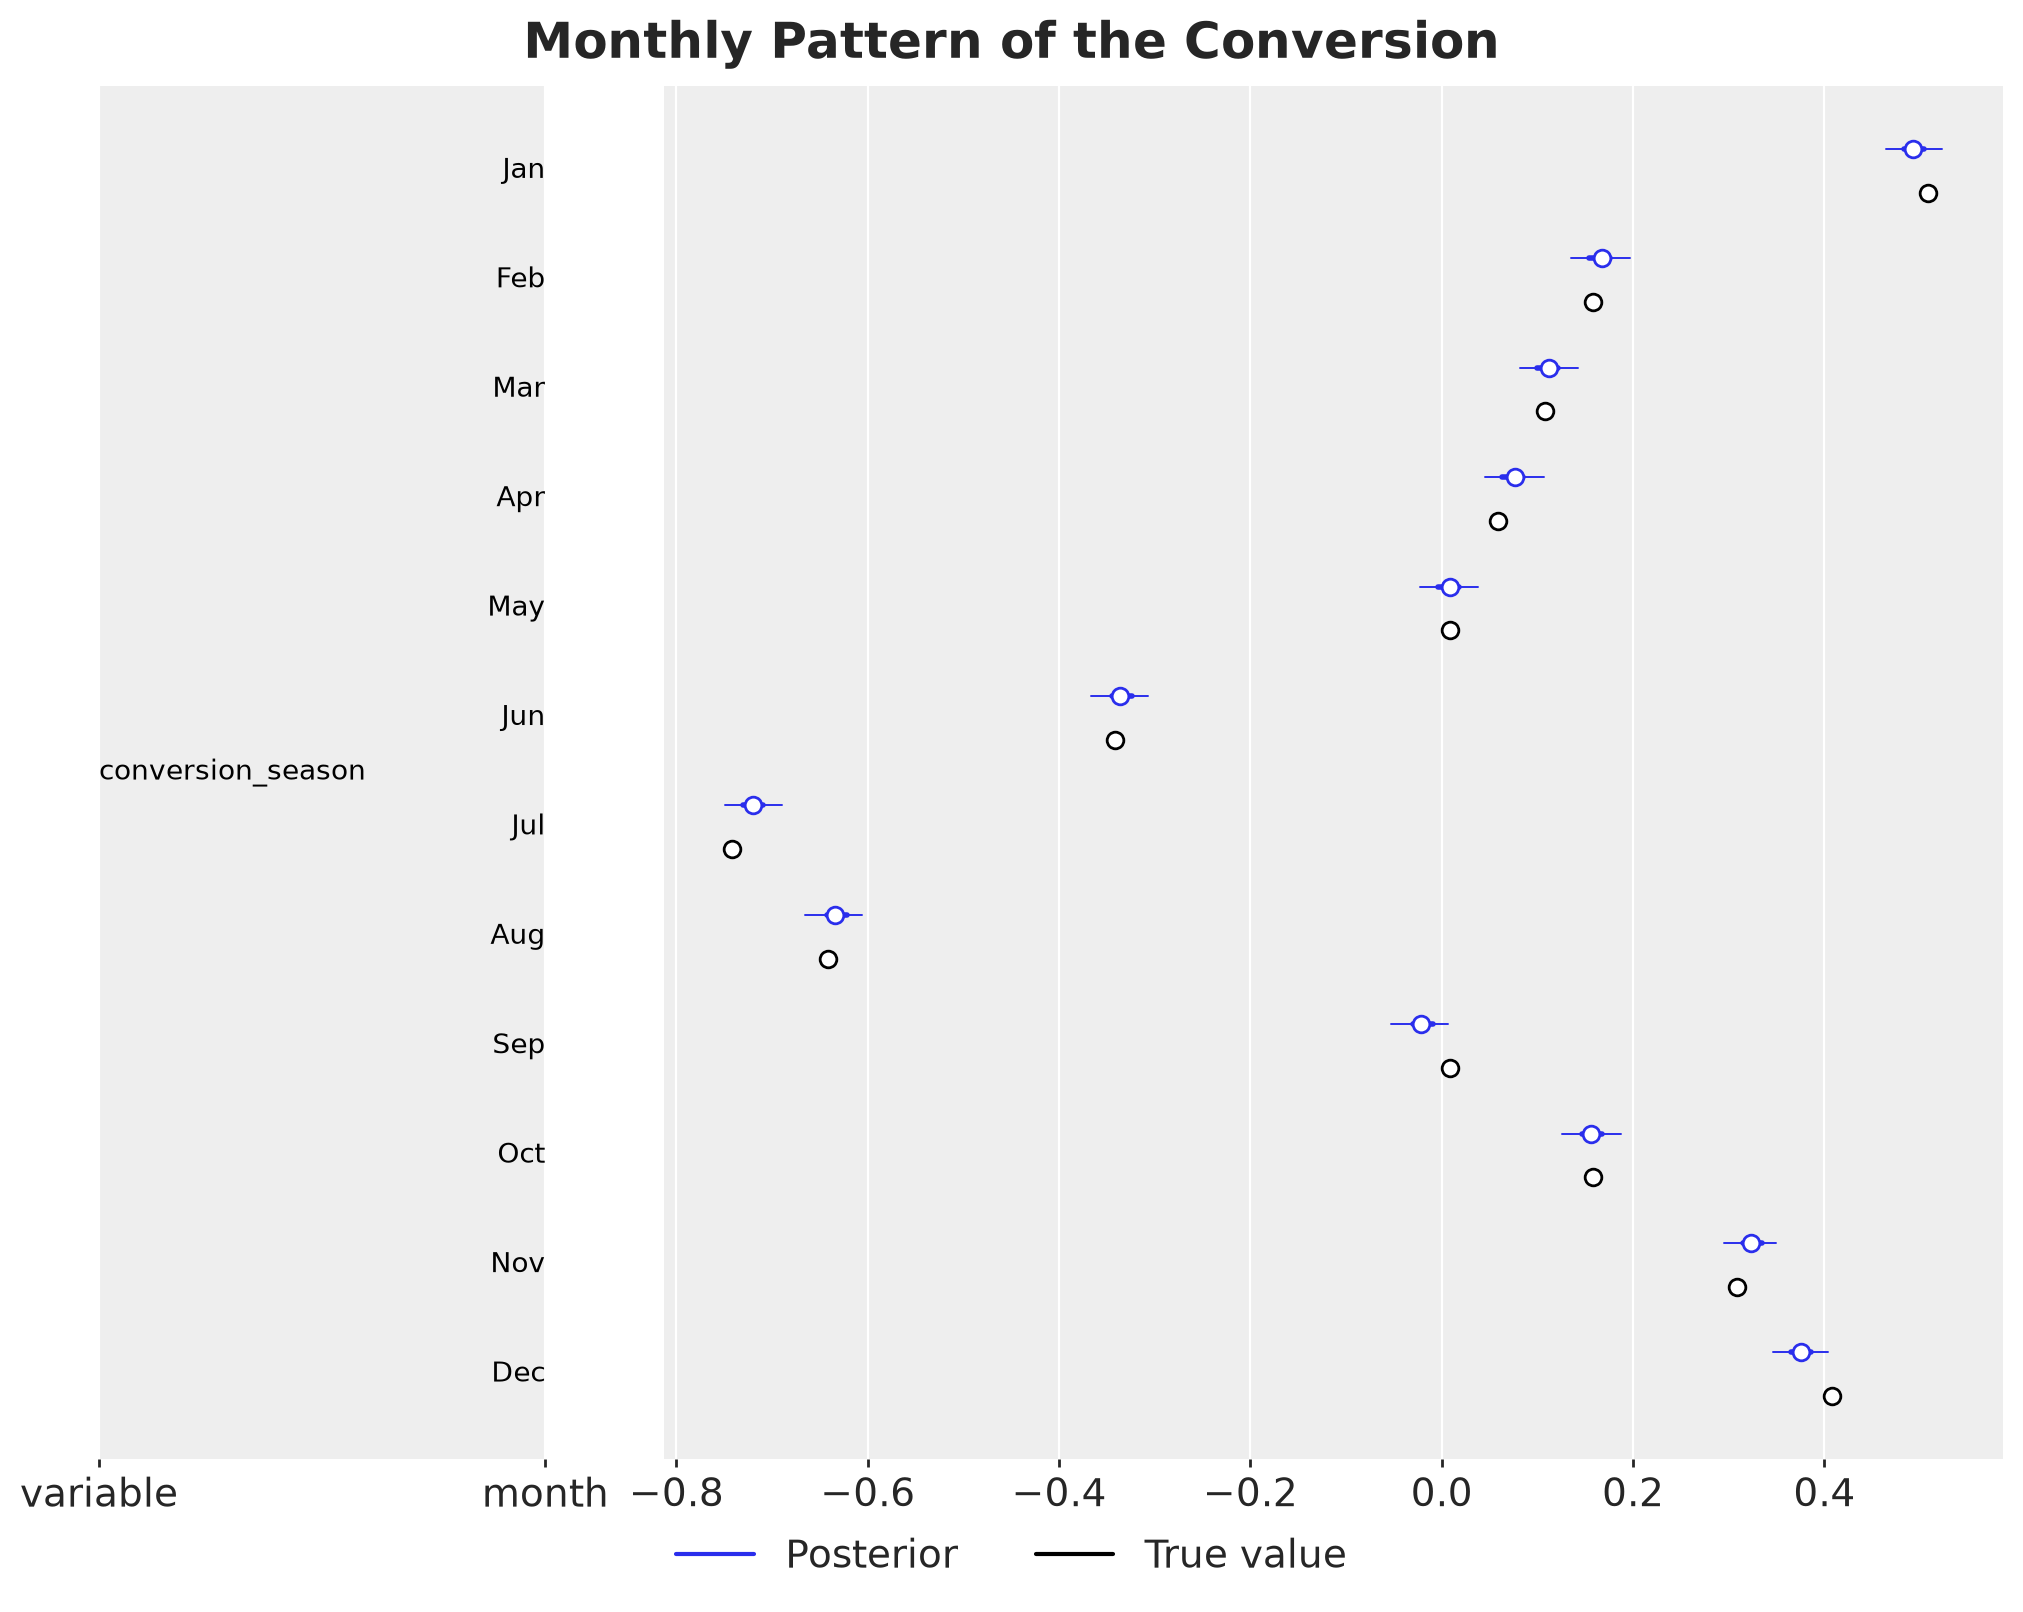

In [21]:
def truth_tree(values: dict[str, xr.DataArray], posterior: xr.Dataset) -> xr.DataTree:
    """Point masses at the true values, with the chains and draws of a posterior."""
    sample_sizes = {"chain": posterior.sizes["chain"], "draw": posterior.sizes["draw"]}
    return xr.DataTree.from_dict(
        {
            "posterior": xr.Dataset(
                {
                    name: value.expand_dims(sample_sizes)
                    for name, value in values.items()
                }
            )
        }
    )


season_truth = truth_tree(
    {
        "conversion_season": xr.DataArray(
            TRUE_PARAMS["conversion_season"], dims="month", coords={"month": MONTHS}
        )
    },
    posterior=idata["posterior"],
)

pc = az.plot_forest(
    {"Posterior": idata, "True value": season_truth},
    var_names=["conversion_season"],
    combined=True,
    color=["C0", "black"],
    figure_kwargs={"figsize": (10, 8)},
)
pc.add_legend("model", title="", loc="outside lower center", ncol=2)
pc.viz["figure"].item().suptitle(
    "Monthly Pattern of the Conversion", fontsize=18, fontweight="bold"
);

The posterior follows the true pattern, with the lowest conversion in July and the highest in January. The true value sits inside the $94\%$ HDI in $10$ of the $12$ months and just outside it in September and December. Since the pattern sums to zero, the errors of the months are not independent.

The churn layer has no parameter with a counterpart in the generator, because its parameters act on the hazard of a cohort and the ones of the generator on the hazard of each user. Recall that the generator recorded the true hazard of every cohort. So we compare the posterior `hazard` with it, for four cohorts:

- `2022-12`, a complete cohort.
- `2023-11`, a promotion cohort that is $13$ months old at the freeze.
- `2024-06`, a cohort that is $6$ months old at the freeze.
- `2024-12`, the youngest cohort, which has not paid a second time yet.

The dashed line marks the age of each cohort at the freeze, so the hazards to its right are forecasts.

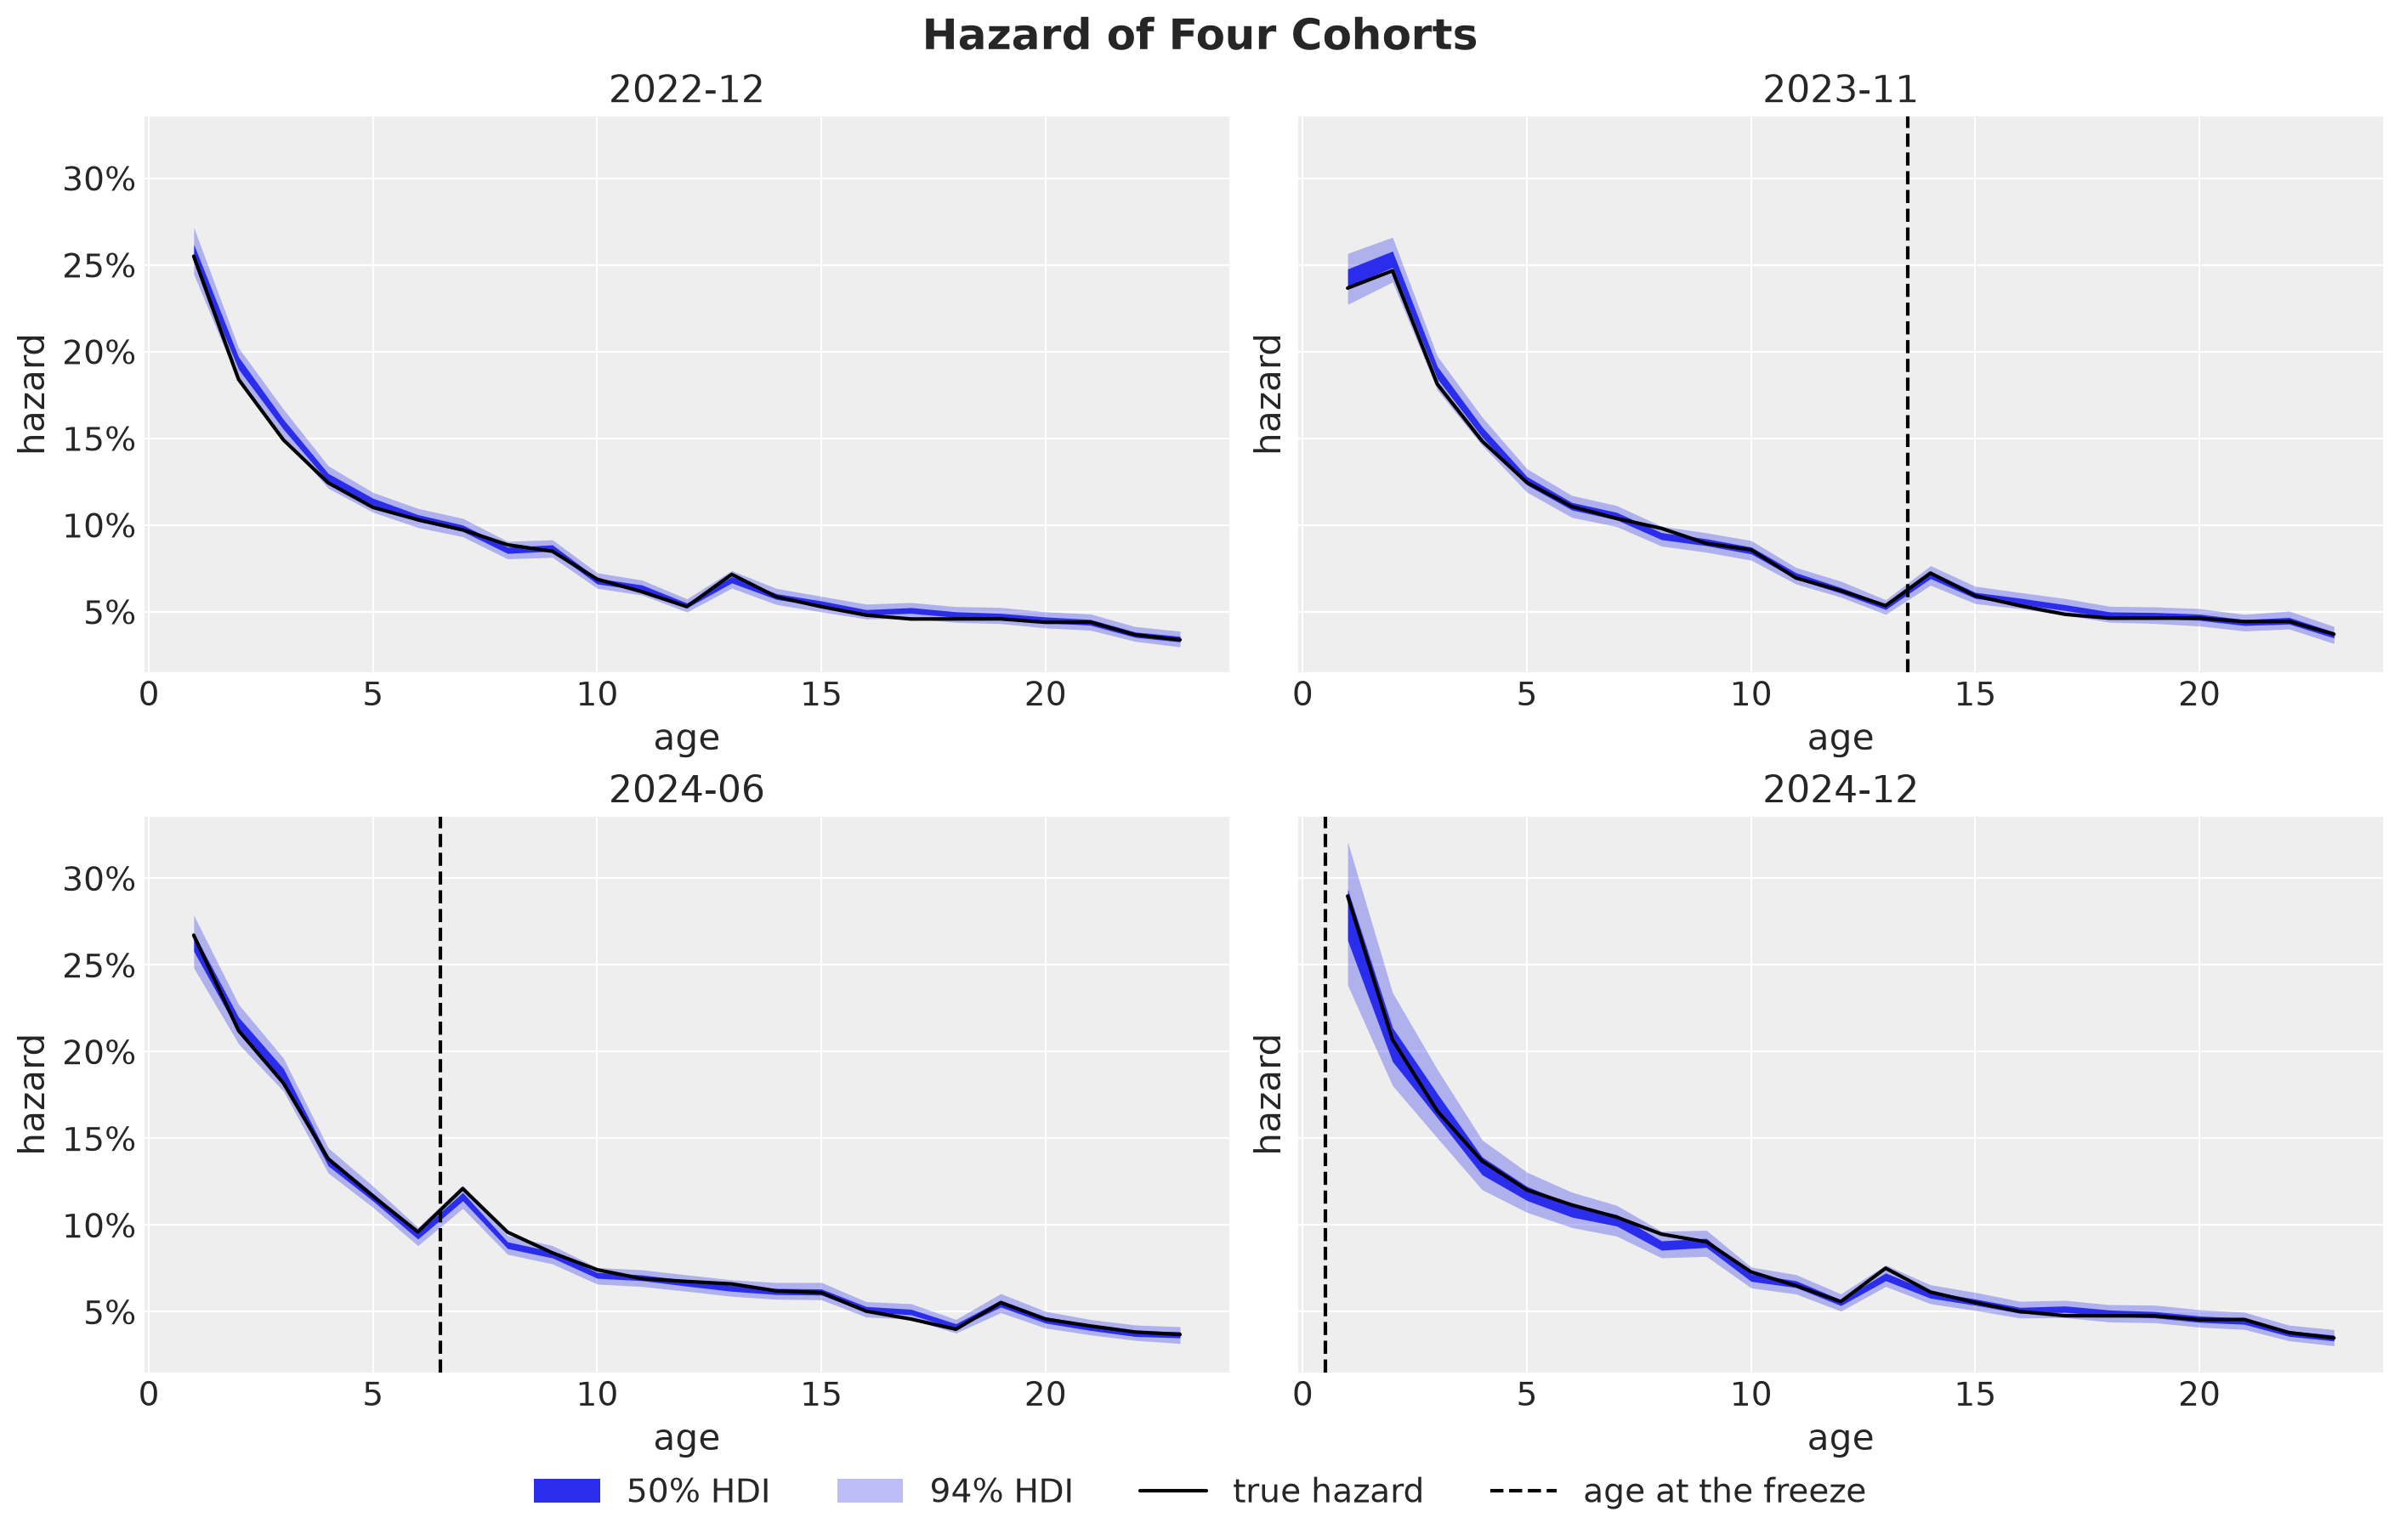

In [22]:
HAZARD_COHORTS: Final[list[str]] = ["2022-12", "2023-11", "2024-06", "2024-12"]

tenure_x = np.broadcast_to(
    calendar.tenures.astype(float), (len(HAZARD_COHORTS), len(calendar.tenures))
)
hazard_tree = az.from_dict(
    {
        "posterior_predictive": {
            "hazard": idata["posterior"]["hazard"]
            .sel(cohort=HAZARD_COHORTS)
            .transpose("chain", "draw", "cohort", "tenure")
            .values
        },
        "observed_data": {
            "hazard": world["true_hazard"]
            .sel(cohort=HAZARD_COHORTS)
            .transpose("cohort", "tenure")
            .values
        },
        "constant_data": {"x": tenure_x.copy()},
    },
    coords={"cohort": HAZARD_COHORTS, "tenure": calendar.tenures},
    dims={"hazard": ["cohort", "tenure"], "x": ["cohort", "tenure"]},
)

pc = az.plot_lm(
    hazard_tree,
    x="x",
    y="hazard",
    plot_dim="tenure",
    smooth=False,
    ci_prob=(0.5, HDI_PROB),
    visuals={"ci_band": {"color": "C0"}, "observed_scatter": False, "pe_line": False},
    col_wrap=2,
    figure_kwargs={"figsize": (14, 9), "sharey": True},
)

for label in HAZARD_COHORTS:
    ax = pc.get_target("x", {"cohort": label})
    current_age = FREEZE - calendar.cohort_labels.index(label)
    ax.plot(
        calendar.tenures,
        world["true_hazard"].sel(cohort=label).values,
        color="black",
        label="true hazard",
    )

    if current_age < calendar.horizon - 1:
        ax.axvline(
            current_age + 0.5, color="black", linestyle="--", label="age at the freeze"
        )

    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set(xlabel="age", ylabel="hazard", title=label)

bands = pc.viz["ci_band"]["x"]
bands.sel(cohort=HAZARD_COHORTS[0], prob=HDI_PROB).item().set_label(
    f"{HDI_PROB:.0%} HDI"
)
bands.sel(cohort=HAZARD_COHORTS[0], prob=0.5).item().set_label("50% HDI")
fig = pc.viz["figure"].item()
handles, labels = pc.get_target(
    "x", {"cohort": HAZARD_COHORTS[-1]}
).get_legend_handles_labels()
first_handles, first_labels = pc.get_target(
    "x", {"cohort": HAZARD_COHORTS[0]}
).get_legend_handles_labels()
fig.legend(
    [*first_handles[:3], handles[-1]],
    [*first_labels[:3], labels[-1]],
    loc="outside lower center",
    ncol=4,
)
fig.suptitle("Hazard of Four Cohorts", fontsize=18, fontweight="bold");

The true hazard sits inside the $94\%$ HDI at almost every age of the four cohorts, including the ages after the freeze. Here are three observations:

- For the complete cohort `2022-12` the bands are narrow and follow the bumps of the season, such as the bump at age $13$, a January payment.
- For the promotion cohort `2023-11` the forecast after the freeze continues the observed hazard, and the truth stays inside the bands.
- The youngest cohort `2024-12` has not paid a second time, so its hazard is the hazard of a typical December cohort, and the bands are wider because its cohort effect is unknown. The truth still sits inside them.

Now that we trust the churn layer, let's look at the fit to the data.

## Posterior Predictive Checks

Recall the one-month retention by age of the *Prior Predictive Checks* section. We now plot the same quantity from the posterior predictive draws.

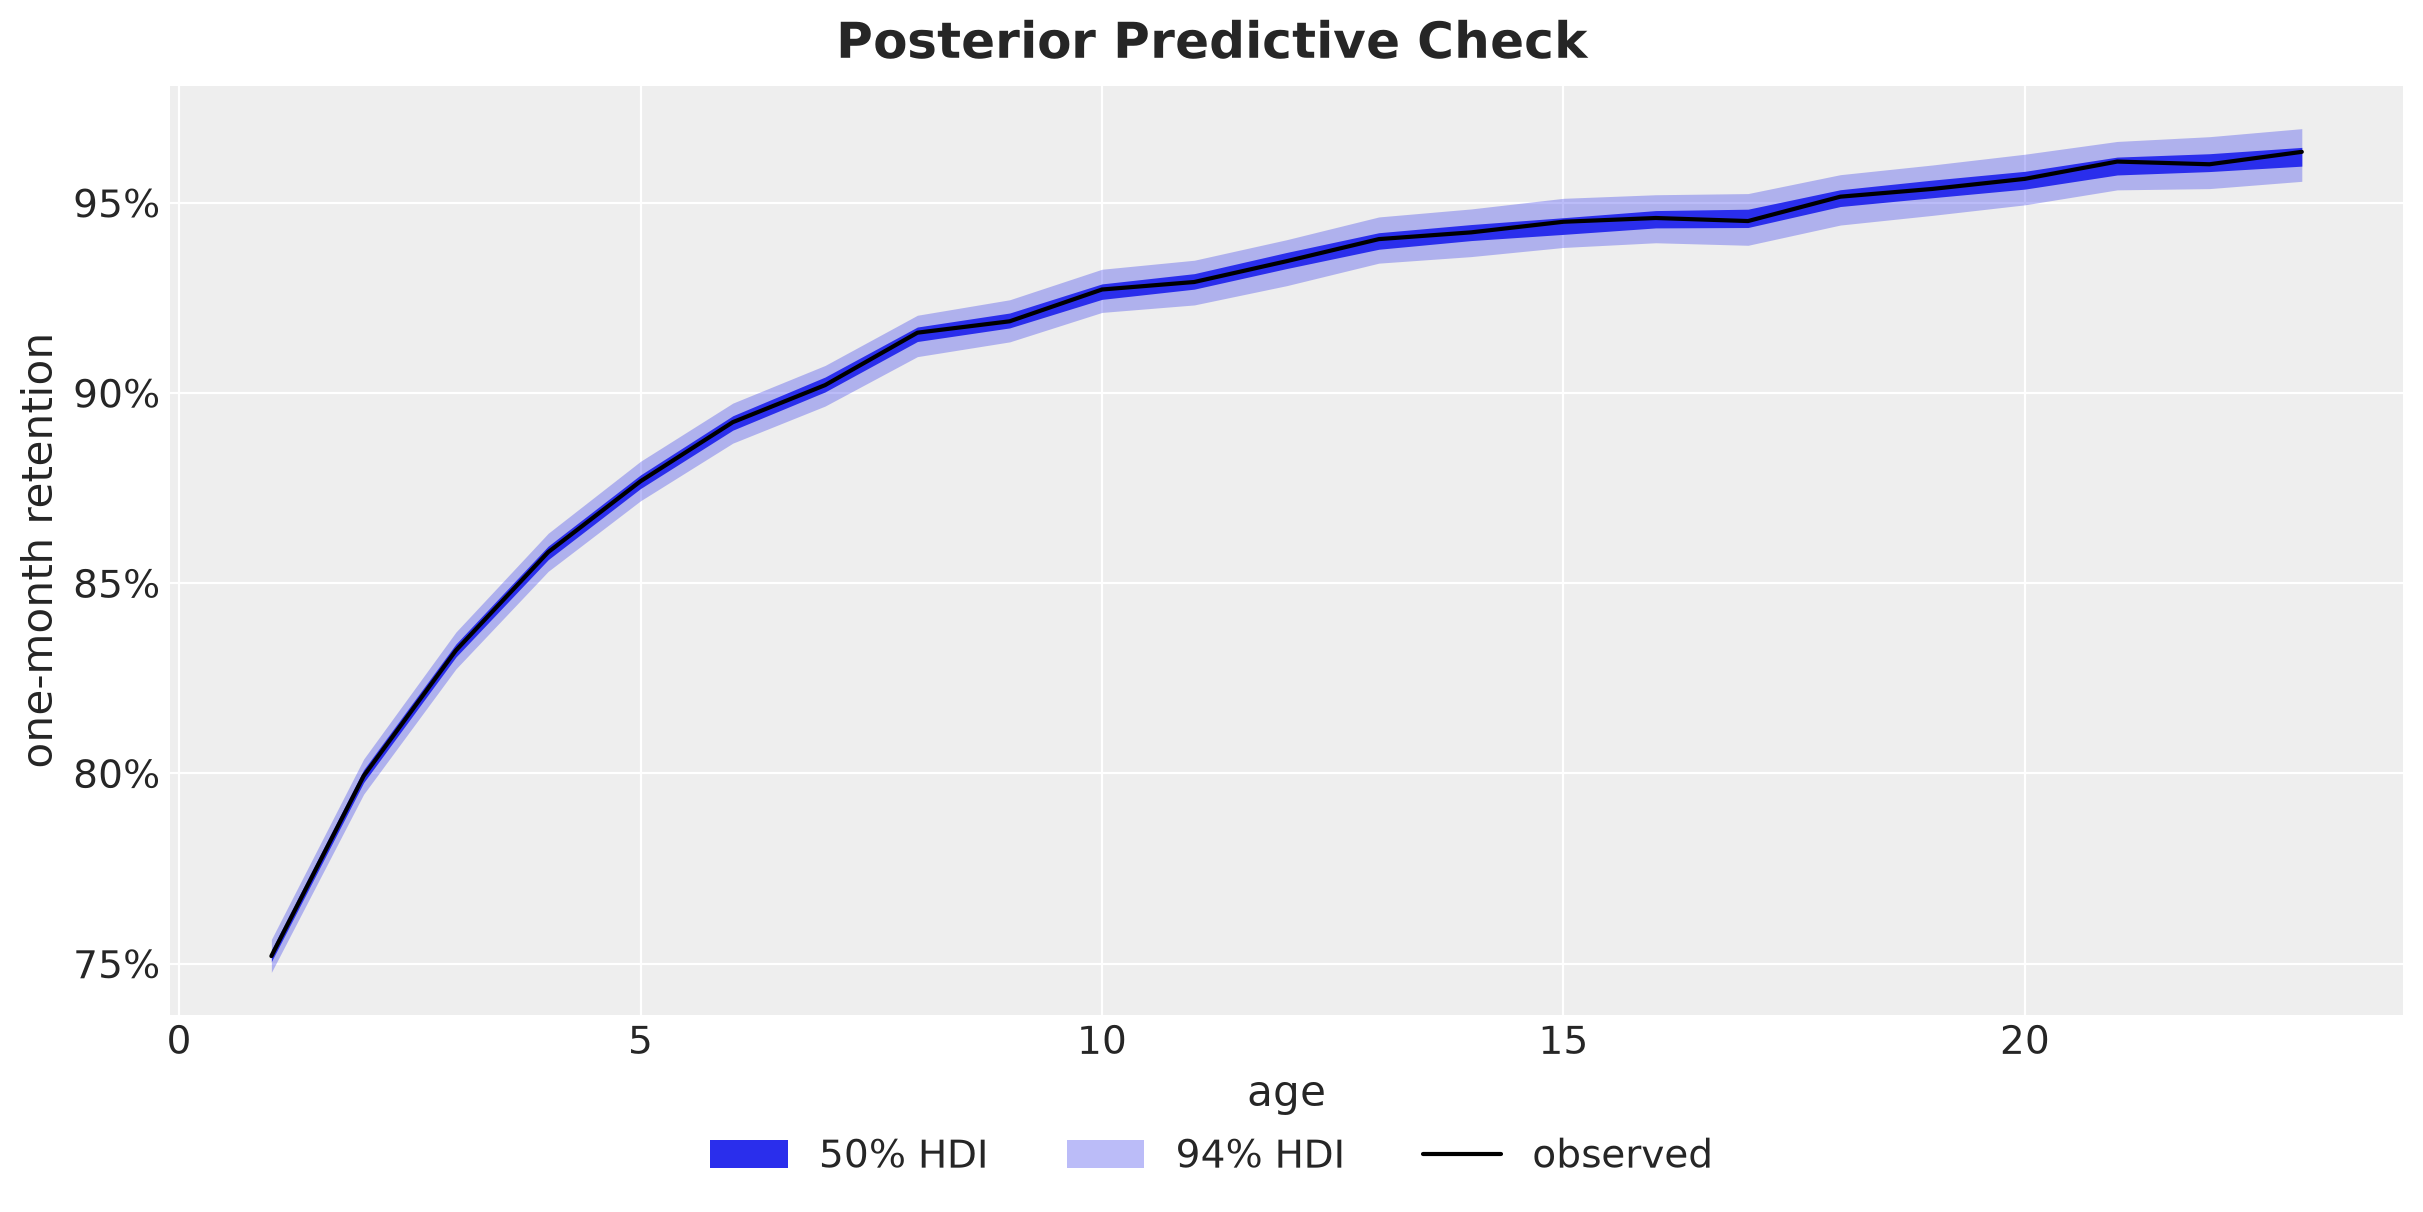

In [23]:
posterior_retention = pooled_retention(
    idata["posterior_predictive"]["n_retained"], data, by="age"
)

pc = plot_retention_check(retention_tree(posterior_retention, observed_retention))
pc.viz["figure"].item().suptitle(
    "Posterior Predictive Check", fontsize=18, fontweight="bold"
);

The bands are narrow and follow the observed retention at every age. The random walk of the age effect has learned the shape of survivor selection from the data.

The pooled retention hides the differences between cohorts and calendar months. So we also look at each cohort and age: we compute the **standardized residual** of the users who pay again, the observed count minus its posterior predictive mean, divided by its posterior predictive standard deviation. If the model fits, the residuals look like independent draws from a standard Normal, with no pattern by cohort or age.

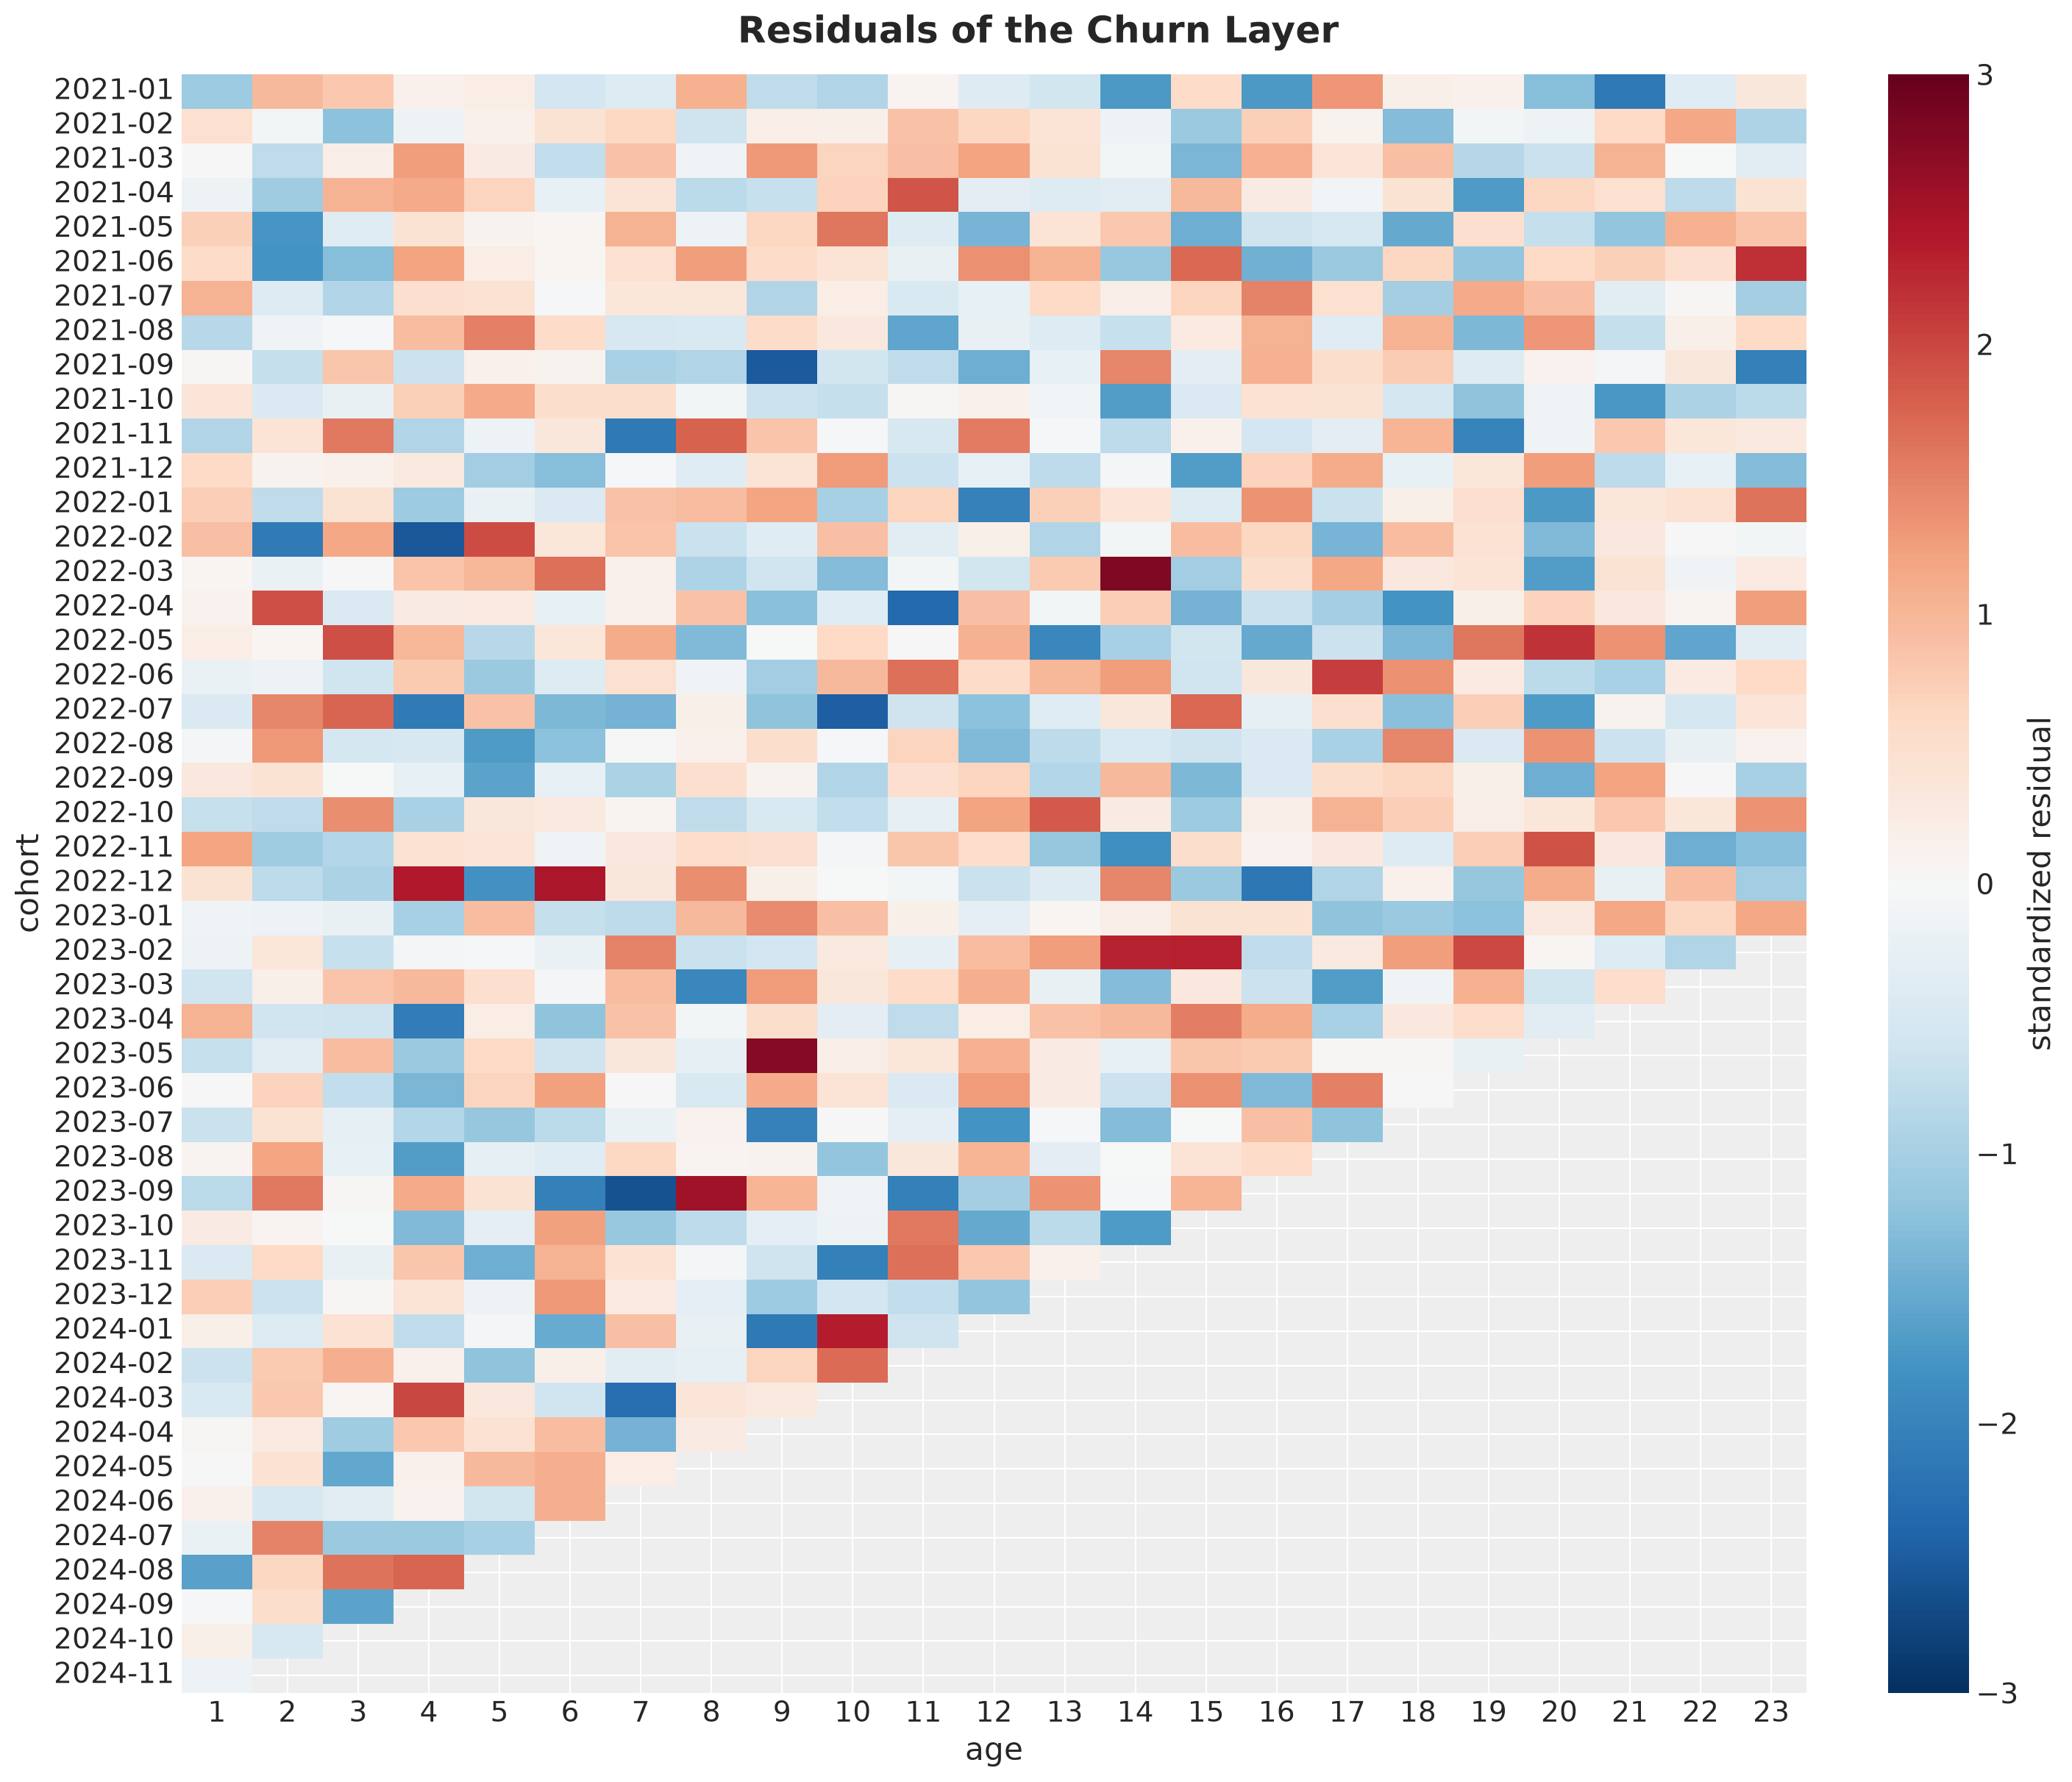

In [24]:
retained_draws = idata["posterior_predictive"]["n_retained"]
residuals = (
    data.transitions.with_columns(
        pl.Series(
            "residual",
            (
                data.transitions["n_payers"].to_numpy()
                - retained_draws.mean(("chain", "draw")).values
            )
            / retained_draws.std(("chain", "draw")).values,
        )
    )
    .pivot(on="age", index="cohort", values="residual")
    .sort("cohort")
)

assert np.nanmax(np.abs(residuals.drop("cohort").to_numpy())) < 3

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    residuals.drop("cohort").to_numpy(),
    cmap="RdBu_r",
    center=0,
    vmin=-3,
    vmax=3,
    xticklabels=calendar.tenures,
    yticklabels=[calendar.cohort_labels[c] for c in residuals["cohort"]],
    cbar_kws={"label": "standardized residual"},
    ax=ax,
)
ax.set(xlabel="age", ylabel="cohort")
fig.suptitle("Residuals of the Churn Layer", fontsize=18, fontweight="bold");

We see no pattern by cohort, by age or along the diagonals of the calendar months, and the assertion confirms that every residual lies between $-3$ and $3$. So the model captures the season, the cohort effects and their fading. Now we can turn to the two quantities that we want to estimate.

## Value per Trial

Recall from *The Subscription Funnel* section that the value per trial $V_m$ is the expected revenue over $24$ months of one trial that starts in month $m$. The model computes it for every posterior draw, and the generator computed its true value. Let's compare the two.

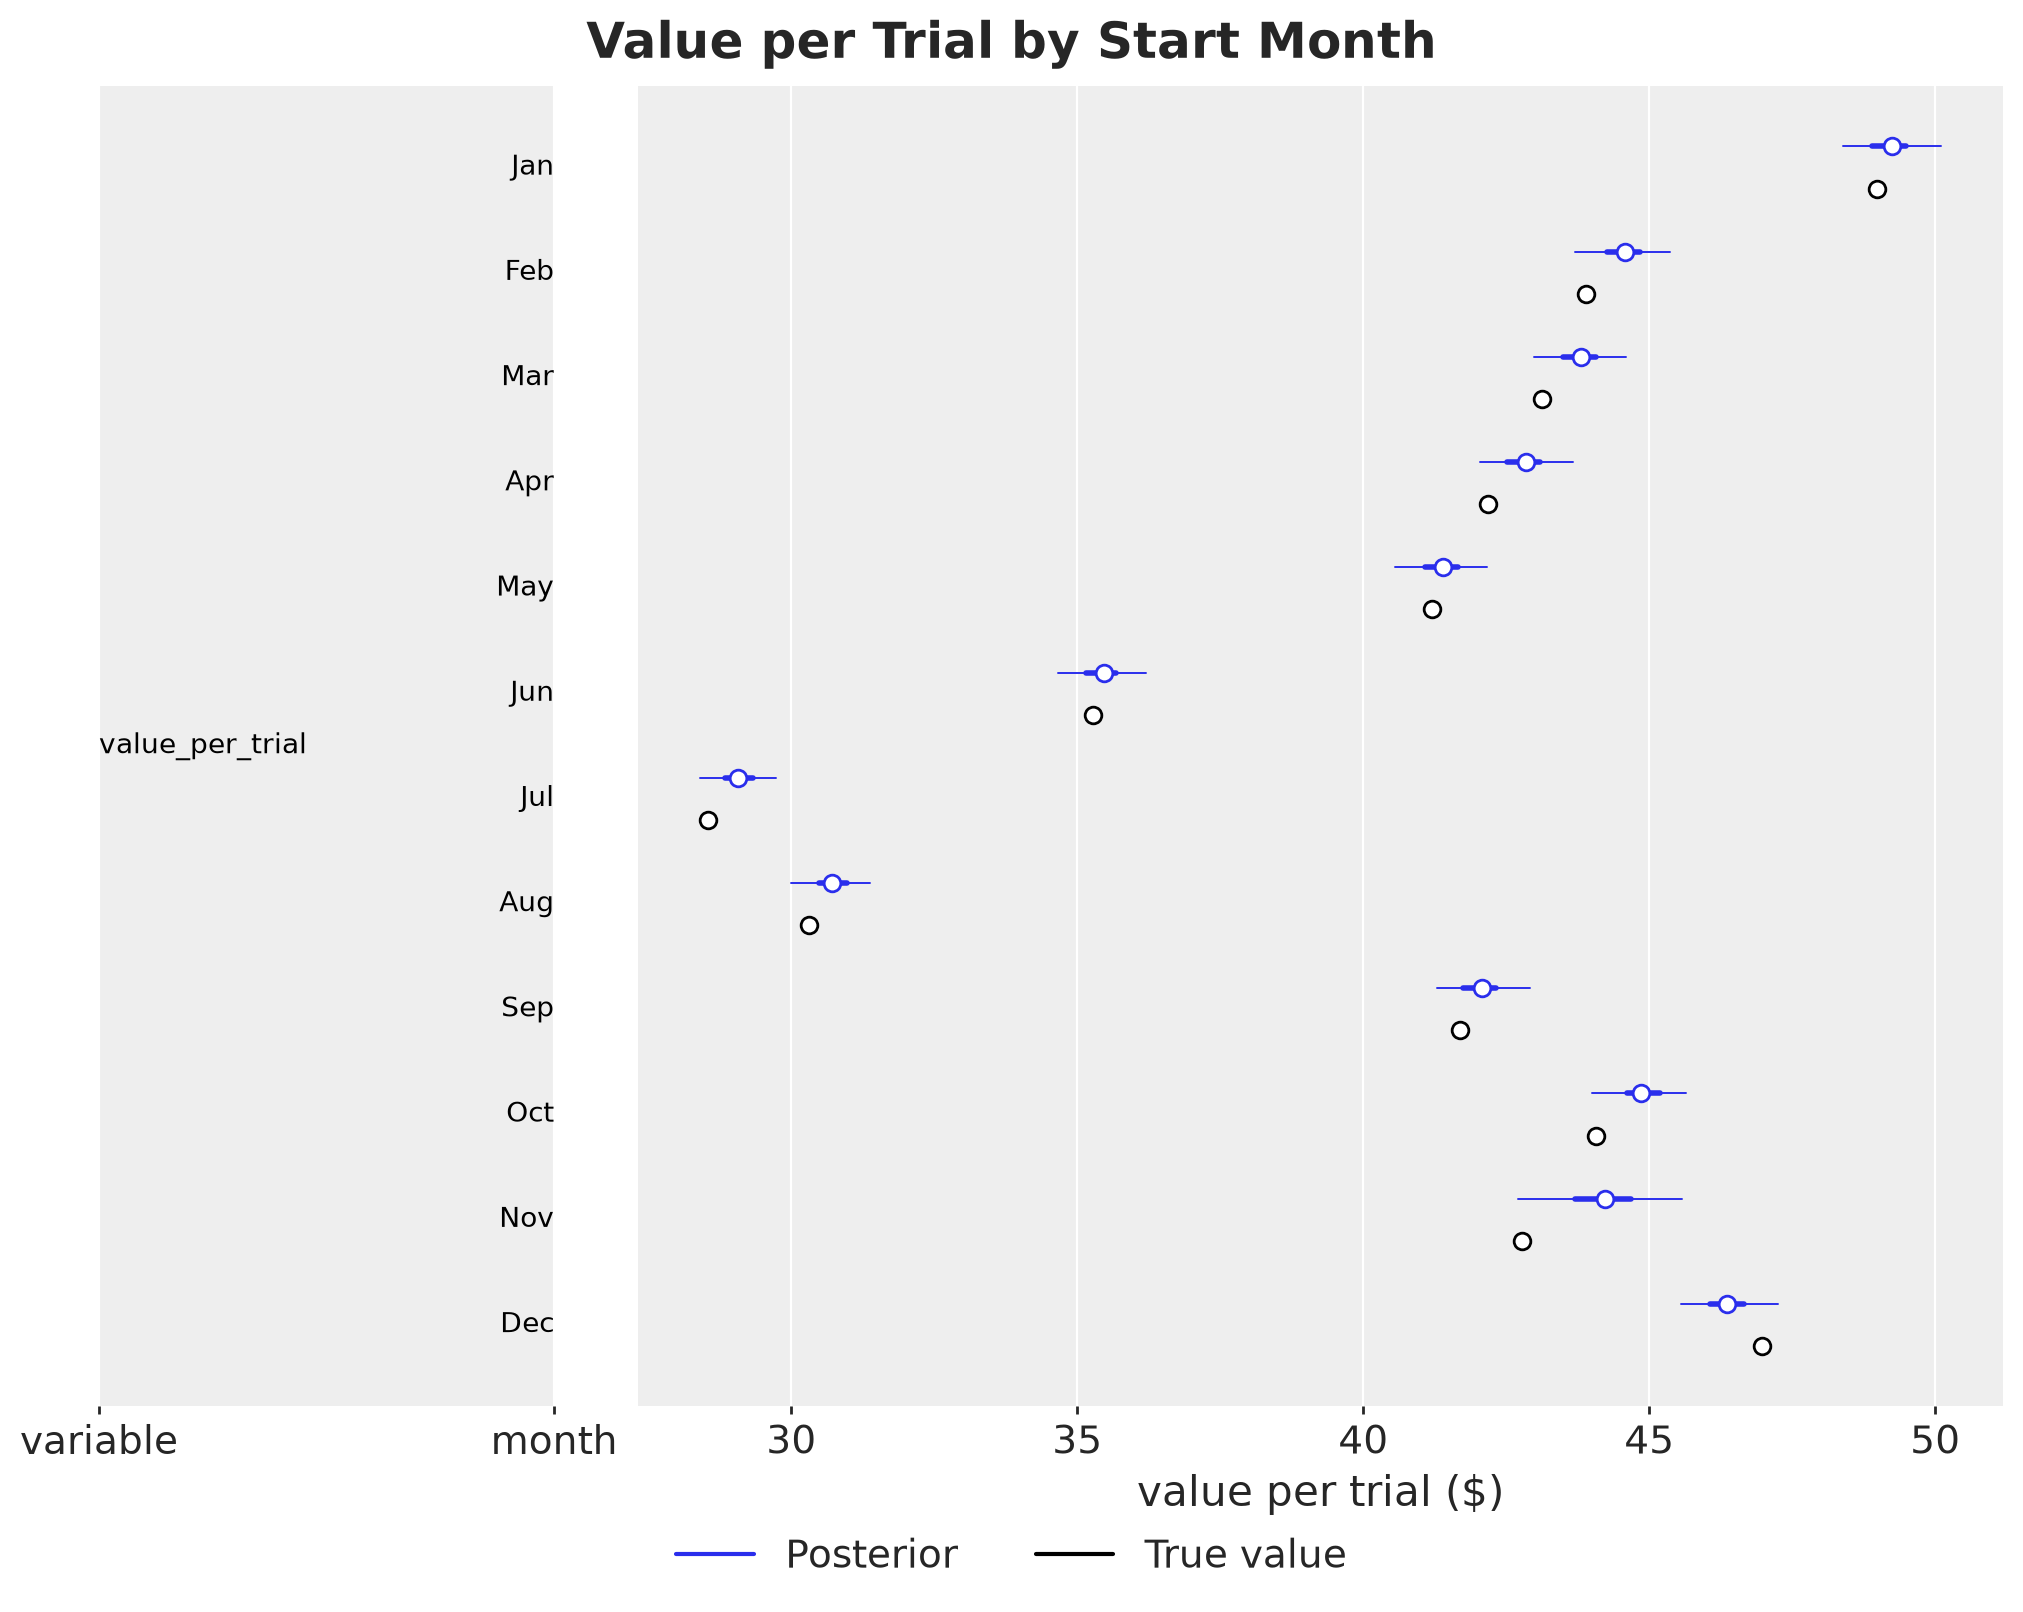

In [25]:
value_truth = truth_tree(
    {
        "value_per_trial": xr.DataArray(
            world["value_per_trial"].values, dims="month", coords={"month": MONTHS}
        )
    },
    posterior=idata["posterior"],
)
value_error = (
    idata["posterior"]["value_per_trial"].mean(("chain", "draw")).values
    - world["value_per_trial"].values
)

assert (value_error > 0).sum() == 11
assert world["churn_cohort_effect"].mean() < 0

pc = az.plot_forest(
    {"Posterior": idata, "True value": value_truth},
    var_names=["value_per_trial"],
    combined=True,
    color=["C0", "black"],
    figure_kwargs={"figsize": (10, 8)},
)
pc.add_legend("model", title="", loc="outside lower center", ncol=2)
ax = pc.viz["plot"].sel(column="forest").item()
ax.set(xlabel="value per trial ($)")
pc.viz["figure"].item().suptitle(
    "Value per Trial by Start Month", fontsize=18, fontweight="bold"
);

Here are the main observations:

- A trial is worth about $\$29$ in July and about $\$49$ in January. The summer trials are worth less because fewer of them convert.
- The November trials, with the promotion, are worth about as much as the trials of the neighboring months. The promotion brings more yearly users, who pay up front, but these users churn more and renew less. Their interval is the widest, because only a few cohorts inform the promotion effects.
- The true value sits inside the $94\%$ HDI in all $12$ months, but the first assertion confirms that the posterior mean is above the truth in $11$ of them.

The twelve months share one error. The true value averages over the population of cohorts, while the model learns from the $48$ cohorts that we observe. The second assertion confirms that the cohort effects of our draw have a negative mean, so these cohorts churn a little less than the population, and the model expects a little more revenue. Another draw of the generator would move all twelve months together, so they are not twelve independent checks.

Keep in mind that the value per trial is gross revenue. Before we use it as a maximum cost per trial, we have to subtract the store fees and the variable costs, and discount the revenue of the later months.

## Cohort Forecasts

Let's now turn to the second quantity, the $24$-month revenue $R_c$ of each cohort. At the freeze we know the revenue of cohort $c$ up to its current age, and we forecast the rest with a simulation:

1. For each posterior draw, we start every cohort from its active users at its current age.
2. We move the users forward month by month with a Binomial draw that keeps each user with probability $1 - \bar{h}_c(a)$, with the hazards of that draw.
3. The yearly users of a cohort younger than $12$ months renew with a Binomial draw with the renewal probability of that draw.
4. The payers of each month pay a Gamma amount, as in the revenue layer.

Each draw of the simulation carries the uncertainty of the parameters and the randomness of the churn. The function below runs all the cohorts and all the posterior draws at once with numpy, so the loop is over the ages only.

In [26]:
def forecast_revenue(
    idata: xr.DataTree, data: FunnelData, rng: np.random.Generator
) -> xr.DataArray:
    """Posterior predictive draws of the 24-month revenue of each cohort."""
    posterior = idata["posterior"]
    hazard = posterior["hazard"].transpose("chain", "draw", "cohort", "tenure").values
    renewal = (
        posterior["renewal_probability"].transpose("chain", "draw", "cohort").values
    )
    shape = posterior["payment_shape"].transpose("chain", "draw", "plan")
    mean = posterior["revenue_per_payment"].transpose("chain", "draw", "plan")
    monthly_shape = shape.sel(plan=Plan.MONTHLY).values[..., None]
    monthly_mean = mean.sel(plan=Plan.MONTHLY).values[..., None]
    yearly_shape = shape.sel(plan=Plan.YEARLY).values[..., None]
    yearly_mean = mean.sel(plan=Plan.YEARLY).values[..., None]
    current_age = data.current_age
    active = np.broadcast_to(data.current_active, renewal.shape).copy()
    future_revenue = np.zeros(renewal.shape)

    for age in calendar.tenures:
        is_future = age > current_age
        survivors = rng.binomial(active, 1 - hazard[..., age - 1])
        active = np.where(is_future, survivors, active)
        payers = np.where(is_future, active, 0)
        future_revenue += rng.gamma(
            payers * monthly_shape, monthly_mean / monthly_shape
        )

    renewed = rng.binomial(data.cohorts["n_users_yearly"].to_numpy(), renewal)
    renewal_payers = np.where(current_age < 12, renewed, 0)
    future_revenue += rng.gamma(
        renewal_payers * yearly_shape, yearly_mean / yearly_shape
    )

    return xr.DataArray(
        data.revenue_to_date + future_revenue,
        dims=("chain", "draw", "cohort"),
        coords={"cohort": data.cohort_labels},
        name="cohort_revenue",
    )


cohort_revenue_forecast = forecast_revenue(idata, data, rng)

The true $24$-month revenue of every cohort is the revenue to date at a freeze after the end of the horizon of the last cohort. We plot the forecast of the cohorts that are not complete at the freeze, together with the revenue that we have seen so far and the true $24$-month revenue.

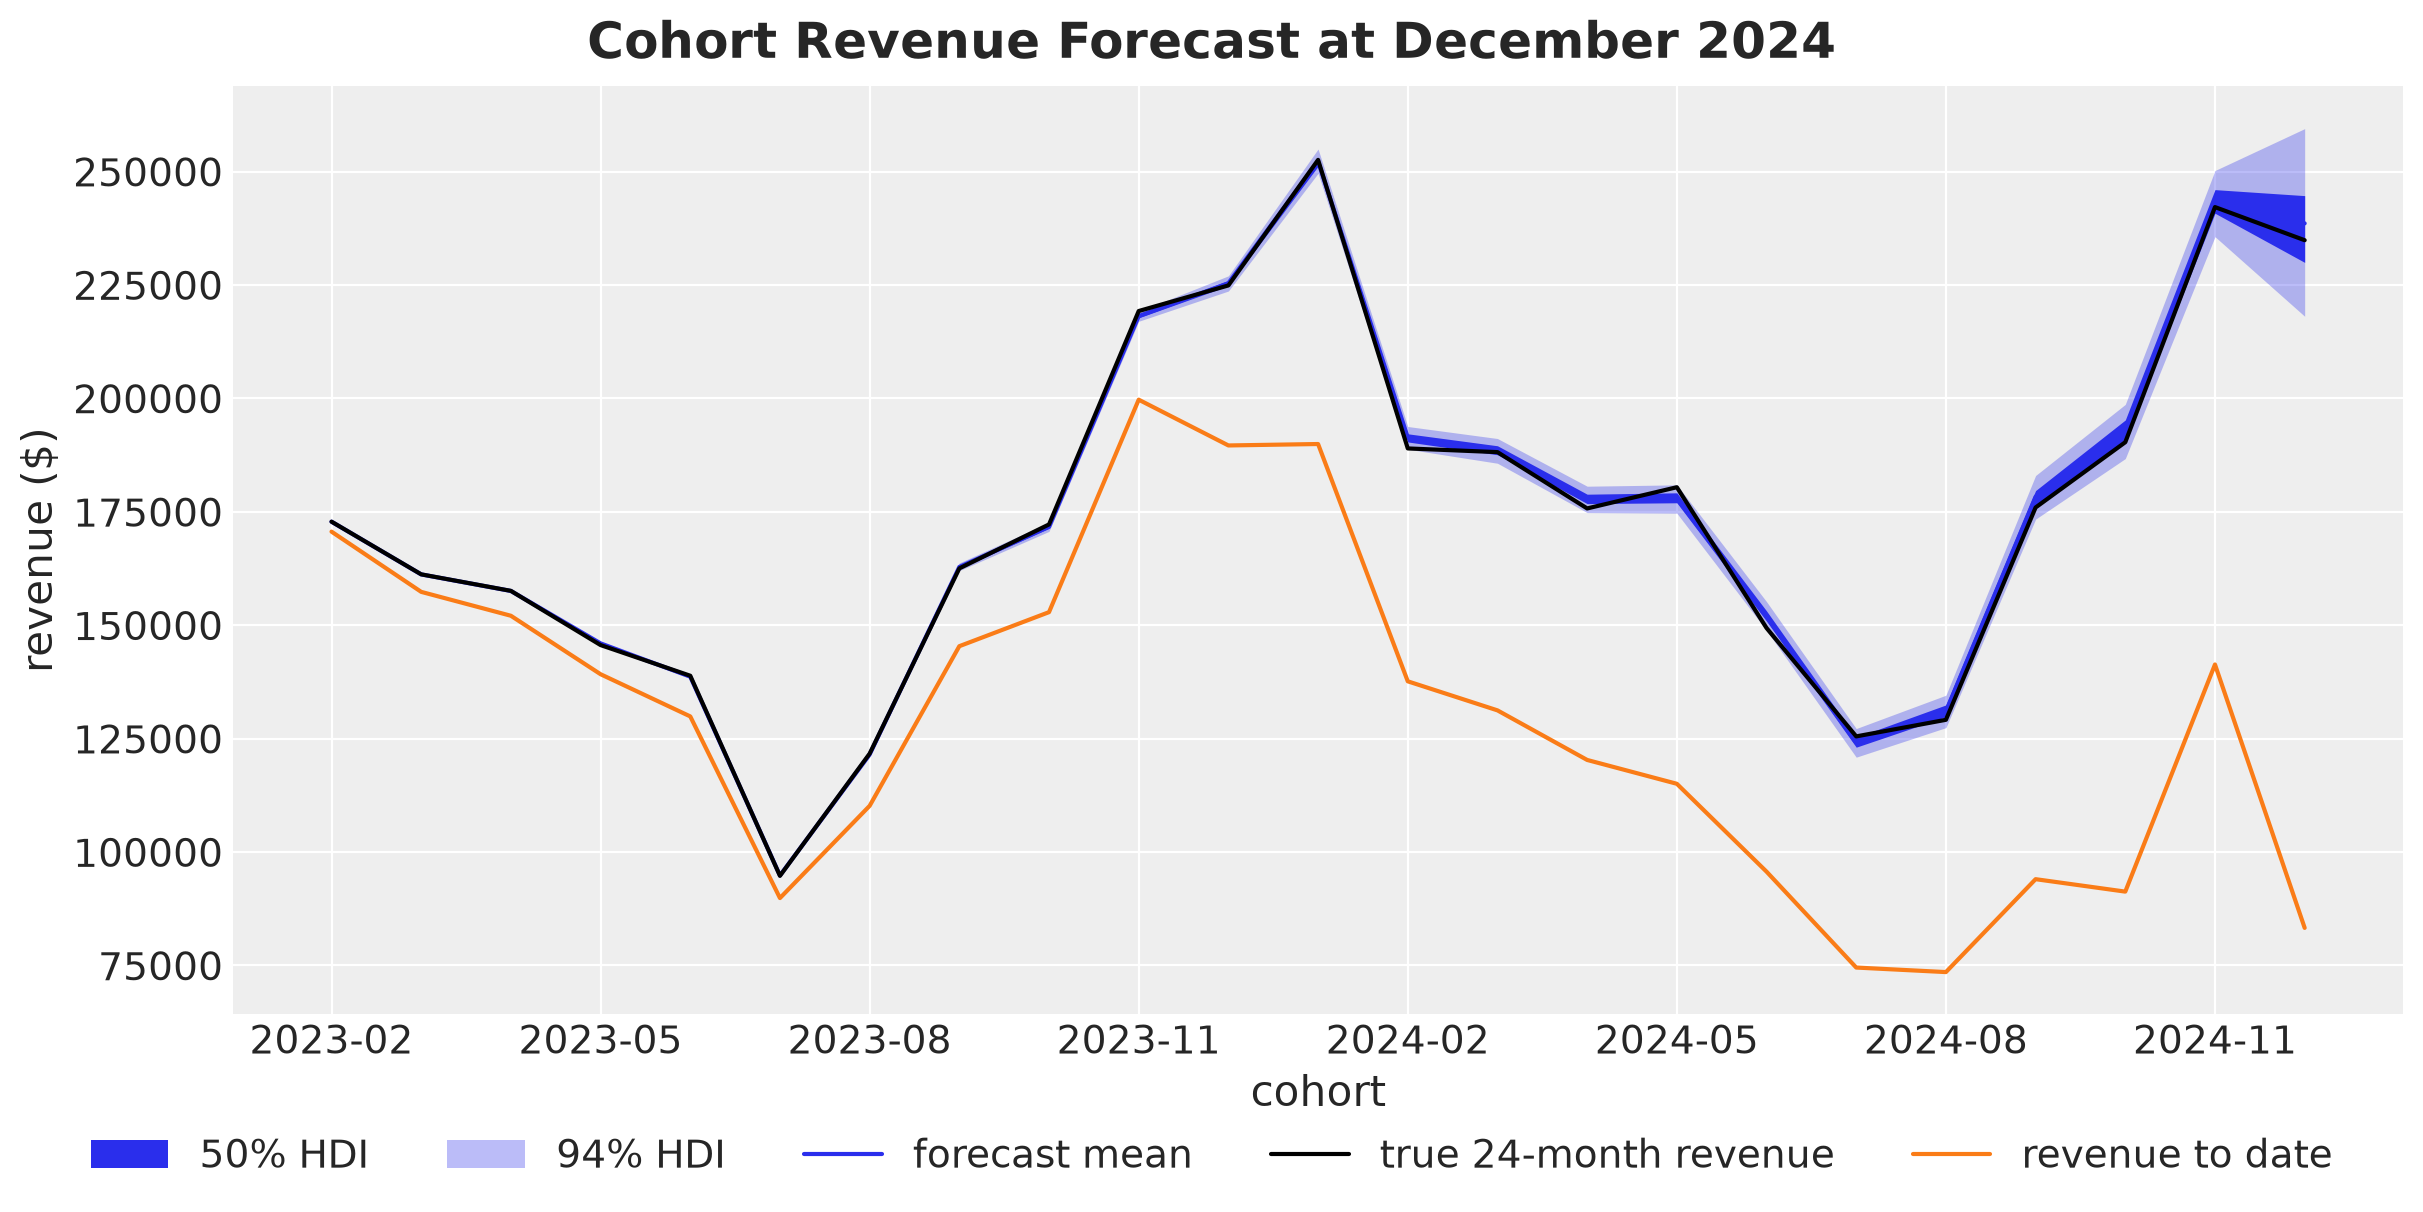

In [27]:
true_cohort_revenue = observe(calendar.n_cohorts + calendar.horizon).revenue_to_date

open_cohorts = data.current_age < calendar.horizon - 1
open_labels = np.array(data.cohort_labels)[open_cohorts]
open_dates = np.array(open_labels, dtype="datetime64[M]").astype(float)

forecast_tree = az.from_dict(
    {
        "posterior_predictive": {
            "revenue": cohort_revenue_forecast.sel(cohort=open_labels).values
        },
        "observed_data": {"revenue": true_cohort_revenue[: FREEZE + 1][open_cohorts]},
        "constant_data": {"x": open_dates},
    },
    coords={"cohort": open_labels},
    dims={"revenue": ["cohort"], "x": ["cohort"]},
)

pc = az.plot_lm(
    forecast_tree,
    x="x",
    y="revenue",
    smooth=False,
    ci_prob=(0.5, HDI_PROB),
    point_estimate="mean",
    visuals={
        "ci_band": {"color": "C0"},
        "pe_line": {"color": "C0", "alpha": 1.0},
        "observed_scatter": False,
    },
    figure_kwargs={"figsize": (12, 6)},
)
ax = pc.viz["plot"]["x"].item()
pc.viz["ci_band"]["x"].sel(prob=HDI_PROB).item().set_label(f"{HDI_PROB:.0%} HDI")
pc.viz["ci_band"]["x"].sel(prob=0.5).item().set_label("50% HDI")
pc.viz["pe_line"]["x"].item().set_label("forecast mean")
ax.plot(
    open_dates,
    true_cohort_revenue[: FREEZE + 1][open_cohorts],
    color="black",
    label="true 24-month revenue",
)
ax.plot(
    open_dates, data.revenue_to_date[open_cohorts], color="C1", label="revenue to date"
)
ax.set_xticks(open_dates[::3], list(open_labels[::3]))
ax.set(xlabel="cohort", ylabel="revenue ($)", title="")
pc.viz["figure"].item().legend(loc="outside lower center", ncol=5)
pc.viz["figure"].item().suptitle(
    "Cohort Revenue Forecast at December 2024", fontsize=18, fontweight="bold"
);

For the cohorts of early 2023 most of the revenue is already in, and the forecast adds the last months. For the cohorts of late 2024 most of the revenue is still to come, so the bands widen, most of all for the youngest cohort, which has paid once. The true revenue follows the forecast mean closely. Whether the bands cover the truth as often as they should is a question for many freezes, which we answer in the next section.

## Backtest

A single freeze tells us little about how the forecast behaves over time. So we replay the forecast at the end of every month of 2024, refit the model on the data of each freeze, and compare the forecast of every incomplete cohort with its true $24$-month revenue. This gives twelve forecasts at every age between $0$ and $22$ months. Note that the same cohort appears in several freezes, so the forecasts are not independent.

### Chain Ladder

We compare the model with the **chain ladder** method, which actuaries use to project cohort triangles. It projects a cohort with the growth of the cohorts that came before it, without any model of the funnel. We run it separately for each plan, because the two plans grow in different ways and the promotion changes the mix of plans.

Let $C_{c,a}$ be the cumulative revenue of cohort $c$ of one plan up to age $a$, and let $\mathcal{C}_{a+1}$ be the set of cohorts that we observe at age $a + 1$. The **development factor** $d_a$ is the ratio of the cumulative revenue at age $a + 1$ to the cumulative revenue at age $a$, pooled over the cohorts in $\mathcal{C}_{a+1}$. The forecast of a cohort at current age $a_c$ multiplies its cumulative revenue by the factors of all later ages:

$$
\hat{R}_c = C_{c,a_c} \prod_{a=a_c}^{H-2} d_a, \qquad d_a = \frac{\sum_{c' \in \mathcal{C}_{a+1}} C_{c',a+1}}{\sum_{c' \in \mathcal{C}_{a+1}} C_{c',a}}.
$$

At age $0$ the chain ladder multiplies the first payment by the ratio of the $24$-month revenue to the first payment of the older cohorts. [Mack (1993)](https://doi.org/10.2143/AST.23.2.2005092) states the assumptions under which this forecast is unbiased and derives its standard error.

In [28]:
def cumulative_revenue(data: FunnelData, plan: Plan) -> np.ndarray:
    """Cumulative revenue of one plan, cohort by age, NaN after the freeze."""
    revenue = np.zeros((len(data.cohorts), calendar.horizon))
    rows = data.payments.filter(pl.col("plan") == plan)
    revenue[
        np.searchsorted(data.cohorts["cohort"].to_numpy(), rows["cohort"].to_numpy()),
        rows["age"].to_numpy(),
    ] = rows["revenue"].to_numpy()
    cumulative = np.cumsum(revenue, axis=1)
    is_future = calendar.ages[None, :] > data.current_age[:, None]
    return np.where(is_future, np.nan, cumulative)


def chain_ladder(data: FunnelData) -> np.ndarray:
    """Cumulative revenue to date times the development factors of the later ages."""
    forecast = np.zeros(len(data.cohorts))

    for plan in Plan:
        cumulative = cumulative_revenue(data, plan)
        observed_next = ~np.isnan(cumulative[:, 1:])
        factors = np.where(observed_next, cumulative[:, 1:], 0).sum(axis=0) / np.where(
            observed_next, cumulative[:, :-1], 0
        ).sum(axis=0)
        to_date = cumulative[np.arange(len(cumulative)), data.current_age]
        remaining = np.array([np.prod(factors[age:]) for age in data.current_age])
        forecast += to_date * remaining

    return forecast

### Scores

We score the forecasts with the **continuous ranked probability score** (CRPS) of [Gneiting and Raftery (2007)](https://doi.org/10.1198/016214506000001437). For a forecast distribution $F$ and a true value $y$ it is $\text{E}|R - y| - \frac{1}{2} \text{E}|R - R'|$, where $R$ and $R'$ are two independent draws from $F$. It generalizes the absolute error to a distribution, it is in the units of the data, and lower is better.

For a point forecast the second term is zero and the CRPS is the absolute error, so the same score covers the chain ladder and the model. Part of the advantage of a distribution under the CRPS comes from its spread, so we also report the absolute error of the posterior median of the model. To compare ages with cohorts of different sizes, we divide the sum of the scores at each age by the sum of the true revenues. For the model we also record whether the $94\%$ HDI covers the true value.

We now run the backtest. The freeze of December 2024 reuses the fit of the *Model Fitting* section.

In [29]:
class Score(StrEnum):
    CHAIN_LADDER = "chain ladder, absolute error"
    FUNNEL_MODEL_CRPS = "funnel model, CRPS"
    FUNNEL_MODEL_MEDIAN = "funnel model, absolute error of the median"


SCORE_STYLES: Final[dict[Score, dict[str, str]]] = {
    Score.CHAIN_LADDER: {"color": "C4", "linestyle": "-"},
    Score.FUNNEL_MODEL_CRPS: {"color": "C0", "linestyle": "-"},
    Score.FUNNEL_MODEL_MEDIAN: {"color": "C0", "linestyle": "--"},
}


def score_freeze(
    data: FunnelData, idata: xr.DataTree, rng: np.random.Generator
) -> pl.DataFrame:
    """Scores of the incomplete cohorts at one freeze, one row per cohort."""
    truth = true_cohort_revenue[: data.freeze + 1]
    forecast = forecast_revenue(idata, data, rng)
    draws = forecast.stack(sample=("chain", "draw")).transpose("sample", "cohort")
    hdi = az.hdi(forecast, prob=HDI_PROB)
    is_open = data.current_age < calendar.horizon - 1
    return pl.DataFrame(
        {
            "freeze": calendar.cohort_labels[data.freeze],
            "current_age": data.current_age,
            "truth": truth,
            Score.CHAIN_LADDER: np.abs(chain_ladder(data) - truth),
            Score.FUNNEL_MODEL_CRPS: crps_empirical(draws.values, truth),
            Score.FUNNEL_MODEL_MEDIAN: np.abs(
                forecast.median(("chain", "draw")).values - truth
            ),
            "covered": (
                (hdi.sel(ci_bound="lower").values <= truth)
                & (truth <= hdi.sel(ci_bound="upper").values)
            ),
        }
    ).filter(pl.Series(is_open))


BACKTEST_FREEZES: Final[list[int]] = [
    calendar.cohort_labels.index(f"2024-{month:02d}") for month in range(1, 13)
]

backtest = pl.concat(
    [
        score_freeze(
            observe(freeze),
            idata if freeze == FREEZE else fit(observe(freeze)),
            rng,
        )
        for freeze in BACKTEST_FREEZES
    ]
)

scores_by_age = (
    backtest.group_by("current_age")
    .agg(
        pl.len().alias("n_forecasts"),
        pl.col("covered").mean().alias("coverage"),
        *[
            (pl.col(score).sum() / pl.col("truth").sum()).alias(score)
            for score in Score
        ],
    )
    .sort("current_age")
)

assert (scores_by_age["n_forecasts"] == len(BACKTEST_FREEZES)).all()

The assertion confirms that every age has one forecast per freeze. Now let's compare the scores and the coverage by the age of the cohort at the freeze.

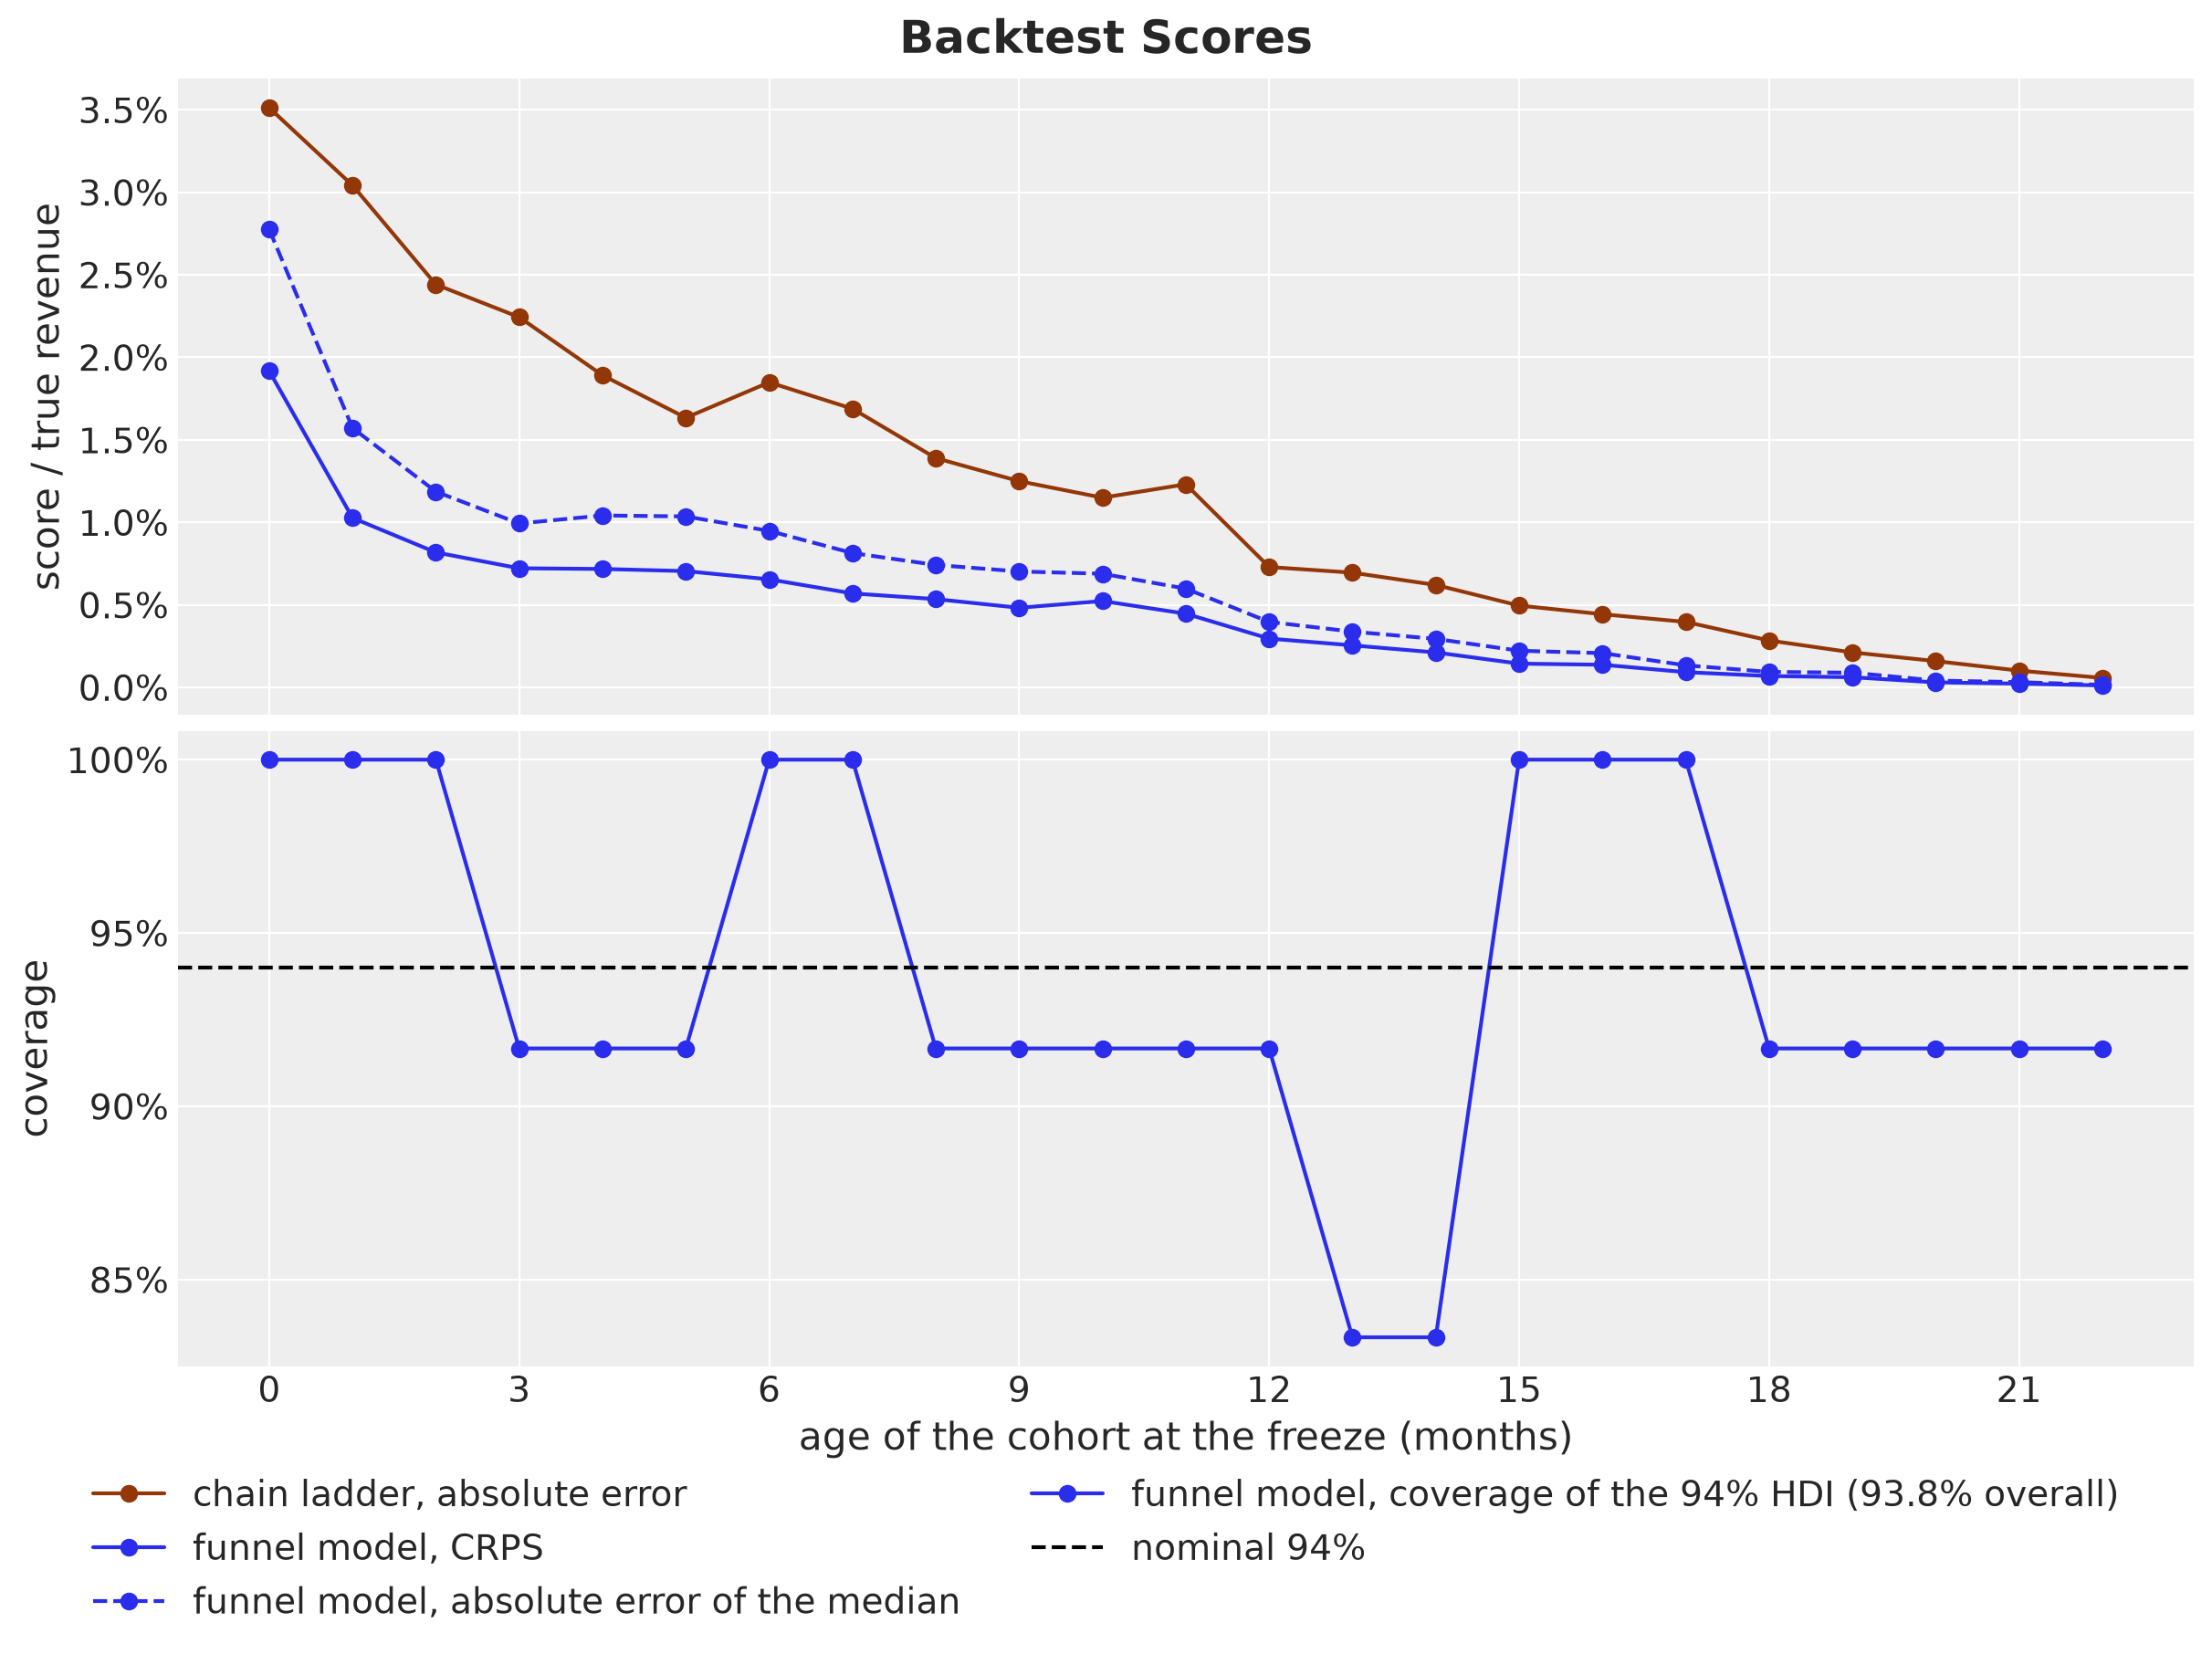

In [30]:
fig, axes = plt.subplots(
    nrows=2, ncols=1, figsize=(12, 9), sharex=True, sharey=False, layout="constrained"
)
ax = axes[0]

for score in Score:
    ax.plot(
        scores_by_age["current_age"],
        scores_by_age[score],
        marker="o",
        label=score,
        **SCORE_STYLES[score],
    )

ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
ax.set(ylabel="score / true revenue")
ax = axes[1]
ax.plot(
    scores_by_age["current_age"],
    scores_by_age["coverage"],
    marker="o",
    color="C0",
    label="funnel model, coverage of the 94% HDI "
    f"({backtest['covered'].mean():.1%} overall)",
)
ax.axhline(HDI_PROB, color="black", linestyle="--", label=f"nominal {HDI_PROB:.0%}")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.set(xlabel="age of the cohort at the freeze (months)", ylabel="coverage")
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle("Backtest Scores", fontsize=18, fontweight="bold");

Here are the results:

- **Chain ladder:** Its error falls from about $3.5\%$ of the revenue for the cohorts at age $0$ to almost zero at age $22$, as more of the revenue of a cohort is observed.
- **Funnel model:** Its CRPS is between about a fifth and a half of the error of the chain ladder at every age. Its point forecast, the posterior median, also beats the chain ladder at every age, so the gain does not come from the spread of the forecast alone.
- **Coverage:** The $94\%$ HDI covers between $10$ and $12$ of the $12$ true values at every age, and $93.8\%$ of all forecasts, which is what we want from a $94\%$ interval.

The largest gap between the two methods is at ages $1$ and $2$. This is consistent with what each method sees. The model already knows the plan mix and the first months of churn of the cohort, and it projects them with the age effect, the season and the fading cohort effect. The chain ladder applies the average growth of the older cohorts, which started in other months and with or without the promotion.

## Conclusion

In this notebook we modeled the funnel of a subscription app with one GLM per step, fitted the steps in one PyMC model, and pushed the posterior draws through the funnel to predict the $24$-month value of a trial and the $24$-month revenue of each cohort. On synthetic data in which every user has their own churn probability, the model recovers the true hazards of the cohorts and the value per trial. In a backtest over the twelve months of 2024, its forecasts beat the chain ladder at every age, with intervals that cover the truth as often as they should 🚀.

### Key Findings

- **Survivor selection:** A cohort loses its high-churn users first, so its hazard falls with age even when no user changes. A churn rate from the first months understates the value of a user, and the age effect of a hazard model should be free to follow the shape that the older cohorts show.
- **Fading of persistent effects:** A difference between cohorts that lasts their whole life, such as a promotion or the mix of ad networks, fades from the hazard of the cohort as its frail users leave. A model of the hazard of a cohort should let such effects fade. A shift that lasts one month, such as the season, does not need to.
- **Population-averaged parameters:** The parameters of a model of cohorts describe the cohort, not the user. We check them through the quantities that they imply, such as the hazard of a cohort and the value per trial, and not against the parameters of a model of users.
- **Modular funnel:** The steps of the funnel share no parameter, so the posterior factorizes and we can check, replace or extend one step at a time. The forecast couples the steps by pushing the draws of one step through the next.
- **Structure over triangles:** The chain ladder sees only the revenue, while the funnel model sees the counts behind it: the plan mix, the active users, the season and the promotion. These counts matter most for the young cohorts, which are the ones that the marketing team asks about.

### Model Limitations

- **Promotion and November:** The promotion runs every November, so we cannot separate its effect from a November effect without an assumption, and the model cannot tell us what happens if we move or drop the promotion.
- **Cohort effects only in the churn:** The conversion, the plan choice, the refunds and the renewal have no cohort effect, neither in the generator nor in the model. In real data they vary from cohort to cohort as well, and the intervals of the value per trial would be wider.
- **Additive season:** The generator shifts the hazard of each user with the season, while the model adds one seasonal effect at every age. The residuals show no pattern here, but a stronger season could leave one.
- **Stable funnel:** Apart from the cohort effect, the rates of the funnel do not drift across cohorts. A product change that lowers the churn of all later cohorts needs an effect that changes over time.
- **Average trial and expected value:** The value per trial averages over all the trials of a month, and its interval is the uncertainty of this average. The value of one more trial and the spread of the revenue of a single cohort are different quantities.
- **Gross revenue:** We ignore taxes, app store fees, variable costs and the time value of money.
- **One synthetic world:** The backtest replays twelve freezes of one simulated world, and the same cohort appears in several freezes, so the scores are not independent.

### Recommendations

1. **Backtest before you bid.** Replay the forecast at past freezes on your own data and compare it with the chain ladder before you use the value per trial to set bids.
2. **Read the residuals by cohort and age.** A pattern along the ages points to the age effect or the fading, and a pattern along the diagonals points to a missing calendar effect.
3. **Turn the value into a margin.** Subtract the store fees and the variable costs, and discount the revenue of the later months, before you set a maximum cost per trial.
4. **Test the promotion.** If the promotion matters for the plan, run it for a random part of the November traffic, so that its effect no longer depends on the assumption about November.

## Next Steps

1. **Cohort effects in every step.** Add partially pooled cohort effects to the conversion, the plan choice and the renewal, and see how much wider the intervals of the value per trial become.
2. **Drift across cohorts.** Replace the constant intercepts with a Gaussian process over the cohorts, so that the model can follow changes of the product and of the prices.
3. **Plan changes.** Model the switches between the monthly and the yearly plan with a multi-state model.
4. **Margin and discounting.** Add the store fee and a discount rate to the value per trial, so that it reads directly as a maximum cost per trial.
5. **Users instead of cohorts.** When we have data on each user, fit an sBG model with covariates on the churn probability of each user and compare it with the model of cohorts.

## References

- Allison, P. D. (1982). [Discrete-Time Methods for the Analysis of Event Histories](https://doi.org/10.2307/270718). *Sociological Methodology*, 13, 61-98.
- Fader, P. S. and Hardie, B. G. S. (2007). [How to Project Customer Retention](https://doi.org/10.1002/dir.20074). *Journal of Interactive Marketing*, 21(1), 76-90.
- Gneiting, T. and Raftery, A. E. (2007). [Strictly Proper Scoring Rules, Prediction, and Estimation](https://doi.org/10.1198/016214506000001437). *Journal of the American Statistical Association*, 102(477), 359-378.
- Mack, T. (1993). [Distribution-Free Calculation of the Standard Error of Chain Ladder Reserve Estimates](https://doi.org/10.2143/AST.23.2.2005092). *ASTIN Bulletin*, 23(2), 213-225.
- Vaupel, J. W., Manton, K. G. and Stallard, E. (1979). [The Impact of Heterogeneity in Individual Frailty on the Dynamics of Mortality](https://doi.org/10.2307/2061224). *Demography*, 16(3), 439-454.
- Zeger, S. L., Liang, K.-Y. and Albert, P. S. (1988). [Models for Longitudinal Data: A Generalized Estimating Equation Approach](https://doi.org/10.2307/2531734). *Biometrics*, 44(4), 1049-1060.